# Preprocessing Data Debit Sungai James

Notebook ini berisi proses pengolahan data mentah USGS dan NOAA menjadi tensor
yang siap dipakai untuk melatih model CNN-LSTM dengan Monte Carlo Dropout.
Setiap tahap ditulis di sel tersendiri, dan gambar dibuat langsung pada tahap
yang membutuhkannya.

## Informasi umum

| | |
|---|---|
| Lokasi | DAS James River, Virginia, Amerika Serikat |
| Pos target | 02035000 James River at Cartersville |
| Periode | 1 Januari 2000 sampai 31 Desember 2024 (9.132 hari) |
| Sumber data | USGS NWIS, USGS NLDI, GAGES-II, NOAA GHCN-Daily |
| Pos debit | 16 pos dengan gap maksimum 2 hari |
| Input deret waktu | Debit harian; curah hujan disiapkan sebagai tensor terpisah |
| Pembagian data | 70 : 15 : 15 menurut urutan waktu |
| Scaling debit | Standardisasi, tanpa logaritma |
| Atribut statis | 10 atribut, dipilih dari 571 |
| Window dan horizon | 14 hari, prediksi 1 sampai 3 hari ke depan |
| Nilai perkiraan (`A:e`) | Tetap dipakai untuk training; sampel uji yang nilai targetnya `A:e` dikeluarkan |

## Susunan notebook

| Bagian | Tahap | Isi |
|---|---|---|
| I | 1–7 | Membaca data debit mentah, memeriksa kualitas, dan menyaring pos |
| II | 8–13 | Metadata pos, jaringan sungai, dan atribut DAS |
| III | 14–17 | Curah hujan: format file, kualitas, jam pengamatan, akumulasi, pemetaan ke pos |
| IV | 18–19 | Hubungan antarstasiun |
| V | 20–26 | Penambalan gap, pembagian data, scaling, window, dan penyusunan tensor |
| VI | 27–29 | Verifikasi dan penyimpanan output |
| VII | 30 | Persiapan eksperimen ablasi sumbu stasiun |

Data mentah diunduh dengan skrip `00a` sampai `00d` di folder yang sama.
Output notebook disimpan di folder `processed/`.

---
## Persiapan

Sel ini berisi semua import, konstanta, pengaturan gambar, dan fungsi yang
dipakai di lebih dari satu tahap. Fungsi yang hanya dipakai di satu tahap
ditulis langsung di tahap tersebut.

Batas pembagian data 70:15:15 juga ditetapkan di sini. Analisis eksploratif di
tahap-tahap awal, seperti pengecekan jam pengamatan hujan, matriks korelasi,
lag perambatan, dan analisis resesi, hanya memakai data latih, jadi batasnya
perlu sudah ada sejak awal. Alasan pembagian ini dijelaskan di tahap 22.

Gambar memakai latar putih, ukuran huruf minimal 9 pt, dan koma sebagai pemisah
desimal. Colormap `viridis` dipakai untuk semua besaran kontinu karena tingkat
terangnya naik secara monoton, sehingga tetap terbaca saat dicetak hitam putih
maupun oleh pembaca buta warna.

In [1]:
import json, re, math, time, warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.lines import Line2D

warnings.filterwarnings("ignore")
MULAI_JALAN = time.time()

# --- lokasi folder: notebook bisa dijalankan dari root repo maupun dari folder preprocessing/
ROOT = Path.cwd() if (Path.cwd() / "raw").exists() else Path.cwd().parent
RAW = ROOT / "raw"
PROC = ROOT / "processed"; PROC.mkdir(exist_ok=True)
PROC_H = PROC / "hujan"; PROC_H.mkdir(exist_ok=True)

# --- konversi satuan
FT3_KE_M3 = 0.0283168466    # ft3/s -> m3/s
FT_KE_M   = 0.3048          # ft -> m
MI2_KE_KM2 = 2.58999         # mil2 -> km2

PERIODE = pd.date_range("2000-01-01", "2024-12-31", freq="D")
n_hari = len(PERIODE)
i_latih, i_val = int(n_hari * 0.70), int(n_hari * 0.85)   # batas 70:15:15, lihat tahap 22
LATIH = PERIODE[:i_latih]

STASIUN = sorted(p.stem for p in (RAW / "hujan" / "dly").glob("*.dly"))
NAMA_PENDEK = {
    "USC00441955": "Concord", "USC00442044": "Covington", "USC00442142": "Crozier",
    "USC00443310": "Gathright", "USC00443375": "Glasgow", "USC00445050": "Louisa",
    "USC00445595": "MillGap", "USC00445880": "Mustoe", "USC00446491": "Scottsville",
    "USC00446712": "Piedmont", "USC00447278": "Roanoke8N", "USC00448941": "Waynesboro",
    "USC00468308": "Snowshoe", "USW00013733": "Lynchburg", "USW00013741": "RoanokeAP",
    "USW00093736": "Charlottesville",
}
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# --- pengaturan gambar
WARNA = {
    "utama":   "#1b4f72",   # pos yang dipakai, garis utama
    "aksen":   "#c0392b",   # marker dan garis bantu
    "abu":     "#9aa5ae",   # pos yang tidak dipakai, elemen sekunder
    "hujan":   "#2e86c1",   # stasiun hujan
    "risiko":  "#f5b041",   # tahap yang berisiko data leakage
    "netral":  "#eaf2f8",   # kotak diagram biasa
}
CMAP = "viridis"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "font.family": "DejaVu Sans", "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 9,
})

def koma(x, _=None, d=2):
    """Angka dengan koma desimal."""
    return f"{x:.{d}f}".replace(".", ",")

def ribu(x):
    """Bilangan bulat dengan titik pemisah ribuan."""
    return f"{int(round(x)):,}".replace(",", ".")

def sumbu_koma(ax, sumbu="y", d=1):
    f = FuncFormatter(lambda x, _: koma(x, d=d))
    (ax.yaxis if sumbu == "y" else ax.xaxis).set_major_formatter(f)

# --- debit USGS
def baca_rdb(path):
    """Baca file RDB USGS, buang baris komentar dan baris tipe kolom."""
    baris = [b for b in Path(path).read_text().splitlines()
             if b.strip() and not b.startswith("#")]
    kol = baris[0].split("\t")
    data = [b.split("\t") for b in baris[1:]]
    # buang baris tipe kolom (5s, 20d, ...) dan header yang berulang
    data = [d for d in data
            if len(d) == len(kol) and d != kol
            and not re.fullmatch(r"\d+[sdn]", d[0])]
    return pd.DataFrame(data, columns=kol)

def muat_satu_pos(path):
    """Ambil (kode_pos, debit ft3/s, kode kualitas) dari satu file RDB."""
    df = baca_rdb(path)
    kol_v = next(c for c in df.columns if c.endswith("_00060_00003"))
    kol_c = next((c for c in df.columns if c.endswith("_00060_00003_cd")), None)
    kode = df["site_no"].iloc[0]
    tgl = pd.to_datetime(df["datetime"], errors="coerce")
    nilai = pd.Series(pd.to_numeric(df[kol_v], errors="coerce").values, index=tgl)
    kualitas = pd.Series(df[kol_c].values, index=tgl) if kol_c else None
    return kode, nilai, kualitas

def nama_pos(kode, n=30):
    """Nama pos dari baris komentar RDB, misalnya '#    USGS 02018000 CRAIG CREEK AT PARR, VA'."""
    b = next(b for b in (RAW / "discharge" / f"dv_{kode}.rdb").read_text().splitlines()
             if b.startswith("#") and f"USGS {kode} " in b)
    s = b.split(kode, 1)[1].strip().title()
    for a, z in [(" At ", " at "), (" Near ", " near "), (" Nr ", " near "), (" Bl ", " below "),
                 (" Above ", " above "), (", Va", ", VA"), (" Abv ", " abv ")]:
        s = s.replace(a, z)
    return s if len(s) <= n else s[:n - 1] + "…"

def panjang_gap(s):
    """Panjang gap (rentetan NaN) di setiap baris, 0 jika ada nilainya."""
    k = s.isna()
    g = (k != k.shift()).cumsum()
    return k.groupby(g).transform("sum").where(k, 0)

def panjang_konstan(s):
    """Panjang rentetan nilai yang sama berturut-turut."""
    sama = (s.diff() == 0)
    g = (sama != sama.shift()).cumsum()
    return sama.groupby(g).transform("sum").where(sama, 0)

# --- hujan GHCN-Daily
def urai_prcp(path, th0, th1):
    """Semua blok PRCP dari satu file .dly: nilai mentah (persepuluh mm) dan flag M, Q, S.
    Format file dijelaskan di tahap 14. Tanggal yang tidak ada (30 Februari, 31 April, dst.) dilewati."""
    rows = []
    for b in Path(path).read_text().splitlines():
        if b[17:21] != "PRCP":
            continue
        th, bl = int(b[11:15]), int(b[15:17])
        if not th0 <= th <= th1:
            continue
        b = b.ljust(269)
        for i in range(31):
            try:
                t = pd.Timestamp(th, bl, i + 1)
            except ValueError:
                continue
            p = 21 + 8 * i
            rows.append((t, int(b[p:p + 5]), b[p + 5], b[p + 6], b[p + 7]))
    return pd.DataFrame(rows, columns=["tanggal", "nilai", "M", "Q", "S"]).set_index("tanggal")

def jarak_km(a1, o1, a2, o2):
    """Jarak haversine (km) antara dua titik (lintang, bujur) dalam derajat."""
    a1, o1, a2, o2 = map(np.radians, (a1, o1, a2, o2))
    h = np.sin((a2 - a1) / 2) ** 2 + np.cos(a1) * np.cos(a2) * np.sin((o2 - o1) / 2) ** 2
    return 2 * 6371.0088 * np.arcsin(np.sqrt(h))

print(f"root repo   : {ROOT}")
print(f"periode     : {PERIODE[0].date()} s.d. {PERIODE[-1].date()}, {n_hari:,} hari")
print(f"data latih  : s.d. {LATIH[-1].date()} ({i_latih:,} hari)")
print(f"stasiun hujan: {len(STASIUN)}")

root repo   : /Users/bernardswidiyazulfathirrochim/Library/Mobile Documents/com~apple~CloudDocs/Proyek Individu/cnn-lstm-mcdropout-streamflow
periode     : 2000-01-01 s.d. 2024-12-31, 9,132 hari
data latih  : s.d. 2017-07-01 (6,392 hari)
stasiun hujan: 16


---
# Bagian I — Membaca data debit mentah

---
## 1. Melihat satu file RDB

Data debit USGS disimpan dalam format RDB, yaitu teks yang dipisahkan tab.
Bagian awal file berisi baris komentar (diawali `#`) yang menjelaskan satuan,
kode parameter, dan arti kode kualitas. Sebelum data diolah, isi salah satu file
ditampilkan terlebih dahulu.

In [2]:
contoh = RAW / "discharge" / "dv_02035000.rdb"
isi = contoh.read_text().splitlines()
print(f"file   : {contoh.relative_to(ROOT)}")
print(f"baris  : {len(isi):,}")
print(f"komentar (#): {sum(1 for b in isi if b.startswith('#'))}")
print("\n" + "="*78)
for b in isi[:38]:
    print(b[:110])
print("="*78)

file   : raw/discharge/dv_02035000.rdb
baris  : 9,162
komentar (#): 28

# ---------------------------------- WARNING ----------------------------------------
# Some of the data that you have obtained from this U.S. Geological Survey database may not 
# have received Director's approval.  Any such data values are qualified as provisional and 
# are subject to revision.  Provisional data are released on the condition that neither the 
# USGS nor the United States Government may be held liable for any damages resulting from its use.
#  Go to http://help.waterdata.usgs.gov/policies/provisional-data-statement for more information.
#
# File-format description:  http://help.waterdata.usgs.gov/faq/about-tab-delimited-output
# Automated-retrieval info: http://help.waterdata.usgs.gov/faq/automated-retrievals
#
# Contact:   gs-w_support_nwisweb@usgs.gov
# retrieved: 2026-11-10 17:31:48 -05:00	(natwebcaas01)
#
# Data for the following 1 site(s) are contained in this file
#    USGS 02035000 JAMES R

Dari baris komentar diperoleh informasi berikut:

- Satuan debit adalah kaki kubik per detik (ft³/s), sehingga perlu dikonversi
  ke m³/s
- `00060` adalah kode parameter debit, `00003` adalah kode statistik rata-rata
  harian
- `145280` adalah nomor deret internal USGS yang berbeda untuk setiap pos
- Kode kualitas `A` berarti data sudah disetujui, `e` berarti nilai hasil
  perkiraan

Setelah komentar, baris pertama berisi nama kolom dan baris kedua berisi tipe
kolom (`5s` teks 5 karakter, `20d` tanggal, `14n` angka). Data baru dimulai di
baris ketiga. Karena itu fungsi `baca_rdb` di sel persiapan membuang baris
komentar, baris tipe kolom, dan header yang berulang.

In [3]:
d = baca_rdb(contoh)
print(f"bentuk: {d.shape}")
print(f"kolom : {list(d.columns)}")
d.head()

bentuk: (9132, 5)
kolom : ['agency_cd', 'site_no', 'datetime', '145280_00060_00003', '145280_00060_00003_cd']


,agency_cd,site_no,datetime,145280_00060_00003,145280_00060_00003_cd
0,USGS,02035000,2000-01-01,3500,A
1,USGS,02035000,2000-01-02,3300,A
2,USGS,02035000,2000-01-03,3300,A
3,USGS,02035000,2000-01-04,3040,A
4,USGS,02035000,2000-01-05,3700,A


---
## 2. Nama kolom yang berbeda di setiap pos

Nama kolom debit mengikuti pola `<TS_ID>_<parameter>_<statistik>`, dan `TS_ID`
berbeda untuk setiap pos. Artinya 23 file debit memiliki 23 nama kolom yang
berbeda. Jika data digabungkan berdasarkan nama kolom, hasilnya akan menjadi
tabel dengan 23 kolom debit yang sebagian besar kosong.

In [4]:
file_debit = sorted(RAW.glob("discharge/dv_*.rdb"))
print(f"jumlah file debit: {len(file_debit)}\n")
for f in file_debit[:6]:
    kol = [b for b in f.read_text().splitlines() if not b.startswith("#")][0]
    print(f"  {f.name:18} -> {kol.split(chr(9))[3]}")
print(f"  ... dan {len(file_debit)-6} file lain, masing-masing dengan TS_ID sendiri")

jumlah file debit: 23

  dv_02018000.rdb    -> 145202_00060_00003
  dv_02019500.rdb    -> 323877_00060_00003
  dv_02020500.rdb    -> 145218_00060_00003
  dv_02021500.rdb    -> 145222_00060_00003
  dv_02022500.rdb    -> 145225_00060_00003
  dv_02024000.rdb    -> 323883_00060_00003
  ... dan 17 file lain, masing-masing dengan TS_ID sendiri


Untuk mengatasinya, kolom debit dicari berdasarkan akhiran `_00060_00003`,
bukan berdasarkan nama lengkapnya, karena akhiran ini sama di semua pos. Cara
ini diterapkan di fungsi `muat_satu_pos` pada sel persiapan.

In [5]:
kode, v, c = muat_satu_pos(contoh)
print(f"pos {kode}: {len(v):,} nilai, {v.index.min().date()} s.d. {v.index.max().date()}")
print(f"satuan masih ft3/s -> min {v.min():.0f}, median {v.median():.0f}, maks {v.max():.0f}")

pos 02035000: 9,132 nilai, 2000-01-01 s.d. 2024-12-31
satuan masih ft3/s -> min 447, median 4170, maks 101000


---
## 3. Memeriksa missing value

Pertama, nilai null dihitung pada hasil baca file, yaitu cara yang biasa dipakai
untuk mencari missing value.

In [6]:
mentah = baca_rdb(contoh)
kol_v = next(c for c in mentah.columns if c.endswith("_00060_00003"))
print("=== cek null pada hasil baca file ===")
print(mentah.isna().sum().to_string())
print(f"\nsel kosong di kolom debit : {int((mentah[kol_v].str.strip()=='').sum())}")
print(f"nilai non-numerik         : {int(pd.to_numeric(mentah[kol_v], errors='coerce').isna().sum())}")
print("\nHasil: tidak ada nilai null.")

=== cek null pada hasil baca file ===
agency_cd                0
site_no                  0
datetime                 0
145280_00060_00003       0
145280_00060_00003_cd    0

sel kosong di kolom debit : 0
nilai non-numerik         : 0

Hasil: tidak ada nilai null.


Hasilnya menunjukkan tidak ada nilai null, padahal USGS tidak menulis baris
untuk tanggal yang tidak memiliki data. Barisnya memang tidak ada di file,
sehingga `isna()` pada hasil baca selalu bernilai nol dan gap data tidak
terlihat.

Karena itu data di-reindex ke kalender harian penuh, yaitu `PERIODE` yang sudah
ditetapkan di sel persiapan, lalu nilai yang kosong dihitung ulang.

In [7]:
print(f"hari dalam periode 2000-2024 : {len(PERIODE):,}")
print(f"baris di file pos {kode}     : {len(v):,}")
print(f"selisih                      : {len(PERIODE)-len(v):,}\n")

print("=== cara benar: reindex ke kalender penuh, lalu periksa ===")
for f in file_debit[:8]:
    k, vv, _ = muat_satu_pos(f)
    s = vv.reindex(PERIODE)
    hil = int(s.isna().sum())
    print(f"  {k}: baris {len(vv):>5,} | setelah reindex kosong {hil:>5,} hari "
          f"({hil/len(PERIODE)*100:5.1f}%)")

hari dalam periode 2000-2024 : 9,132
baris di file pos 02035000     : 9,132
selisih                      : 0

=== cara benar: reindex ke kalender penuh, lalu periksa ===
  02018000: baris 9,132 | setelah reindex kosong     0 hari (  0.0%)
  02019500: baris 9,132 | setelah reindex kosong     0 hari (  0.0%)
  02020500: baris 9,132 | setelah reindex kosong     0 hari (  0.0%)
  02021500: baris 9,132 | setelah reindex kosong     0 hari (  0.0%)
  02022500: baris 9,132 | setelah reindex kosong     0 hari (  0.0%)
  02024000: baris 9,132 | setelah reindex kosong     0 hari (  0.0%)
  02024752: baris 7,032 | setelah reindex kosong 2,100 hari ( 23.0%)
  02024915: baris 8,090 | setelah reindex kosong 1,042 hari ( 11.4%)


Setelah di-reindex, gap data mulai terlihat. Beberapa pos kosong ribuan hari
karena pencatatannya baru dimulai jauh setelah tahun 2000. Jadi pemeriksaan
missing value harus dilakukan setelah data disejajarkan dengan kalender.

---
## 4. Kode kualitas dan nilai perkiraan

Kolom berakhiran `_cd` berisi kode kualitas untuk setiap nilai debit. Dari kolom
ini dapat diketahui apakah sebuah nilai merupakan hasil pengukuran atau hasil
perkiraan USGS.

In [8]:
hitung = Counter()
for f in file_debit:
    _, _, cc = muat_satu_pos(f)
    if cc is not None:
        hitung.update(cc.dropna().tolist())

arti = {"A": "disetujui, hasil pengukuran",
        "A:e": "disetujui, tetapi HASIL PERKIRAAN",
        "A:<": "nilai sebenarnya lebih kecil dari tercatat",
        "A:>": "nilai sebenarnya lebih besar dari tercatat",
        "A:R": "sudah direvisi",
        "P": "sementara, belum ditinjau"}
tot = sum(hitung.values())
print(f"{'kode':6} {'jumlah':>10} {'persen':>8}  arti")
for k, n in hitung.most_common():
    print(f"{k:6} {n:>10,} {n/tot*100:>7.2f}%  {arti.get(k,'-')}")

kode       jumlah   persen  arti
A         183,537   96.20%  disetujui, hasil pengukuran
A:e         7,244    3.80%  disetujui, tetapi HASIL PERKIRAAN
A:<             3    0.00%  nilai sebenarnya lebih kecil dari tercatat
A:R             2    0.00%  sudah direvisi


In [9]:
baris = []
for f in file_debit:
    k, vv, cc = muat_satu_pos(f)
    e = cc.str.contains("e", na=False)
    baris.append({"pos": k, "n_nilai": len(vv),
                  "perkiraan": int(e.sum()),
                  "persen_perkiraan": round(e.mean()*100, 1)})
pe = pd.DataFrame(baris).sort_values("persen_perkiraan", ascending=False)
print("proporsi nilai perkiraan per pos:")
print(pe.to_string(index=False))

proporsi nilai perkiraan per pos:
     pos  n_nilai  perkiraan  persen_perkiraan
02032250     7118        857              12.0
02024752     7032        453               6.4
02032640     9007        549               6.1
02027500     9132        505               5.5
02020500     9132        492               5.4
02027000     9132        436               4.8
02031000     9132        426               4.7
02030000     9131        408               4.5
02022500     9132        357               3.9
02028500     9132        349               3.8
02035000     9132        302               3.3
02021500     9132        291               3.2
02024915     8090        253               3.1
02024000     9132        274               3.0
02025500     9131        254               2.8
02030500     7132        154               2.2
02029000     9132        189               2.1
02034000     9132        179               2.0
02026000     9132        178               1.9
02025652     4709         

Sebanyak 3,8 persen nilai di seluruh file merupakan hasil perkiraan, dengan
rentang 1,3 sampai 12 persen per pos.

Nilai perkiraan tetap dipakai untuk training karena jumlah data terbatas,
tetapi dikeluarkan dari data uji agar evaluasi akhir hanya memakai nilai hasil
pengukuran. Flag nilai perkiraan disimpan sampai ke tensor agar bisa diperiksa
kembali.

---
## 5. Memuat seluruh pos

Semua pos dimuat dengan langkah yang sama: mencari kolom debit berdasarkan
akhiran, mengubah nilai negatif (`-999999`) menjadi NaN, mengonversi satuan ke
m³/s, me-reindex ke kalender harian penuh, dan menyimpan flag nilai perkiraan.

In [10]:
def muat_semua(file_debit, periode):
    nilai, kualitas = {}, {}
    for f in file_debit:
        k, v, c = muat_satu_pos(f)
        v = v[~v.index.duplicated()]
        v[v < 0] = np.nan            # -999999 = missing value di USGS
        nilai[k] = v.reindex(periode) * FT3_KE_M3
        if c is not None:
            kualitas[k] = c[~c.index.duplicated()].reindex(periode)
    Q = pd.DataFrame(nilai).sort_index(axis=1)
    E = pd.DataFrame(kualitas).reindex(columns=Q.columns)
    E = E.apply(lambda s: s.str.contains("e", na=False))   # True = perkiraan
    return Q, E

Q_semua, E_semua = muat_semua(file_debit, PERIODE)
print(f"Q : {Q_semua.shape}  (hari x pos), satuan m3/s")
print(f"E : {E_semua.shape}  (True = nilai perkiraan)")
print(f"\npos: {', '.join(Q_semua.columns)}")
Q_semua.iloc[:3, :6].round(2)

Q : (9132, 23)  (hari x pos), satuan m3/s
E : (9132, 23)  (True = nilai perkiraan)

pos: 02018000, 02019500, 02020500, 02021500, 02022500, 02024000, 02024752, 02024915, 02025500, 02025652, 02026000, 02027000, 02027500, 02028500, 02029000, 02030000, 02030500, 02031000, 02032250, 02032515, 02032640, 02034000, 02035000


,02018000,02019500,02020500,02021500,02022500,02024000
2000-01-01,4.36,23.81,1.76,3.54,0.2,7.73
2000-01-02,4.05,22.80,1.70,3.26,0.2,7.25
2000-01-03,3.82,21.86,1.67,3.06,0.2,6.85


---
## 6. Tabel kualitas seluruh pos

Tabel kualitas dihitung untuk semua pos yang memiliki data, tidak hanya pos yang
nantinya dipakai, supaya proses penyaringan dapat ditelusuri.

Hal yang diperiksa:

- **Gap maksimum**, yaitu jumlah hari kosong berturut-turut yang paling panjang.
  Ukuran ini dipakai sebagai dasar kelayakan pos, bukan persentase
  kelengkapan. Pos yang 99 persen lengkap tetapi memiliki satu gap 90 hari lebih
  buruk daripada pos yang 97 persen lengkap dengan gap 1 hari yang tersebar.
- **Nilai konstan**, yaitu nilai yang sama persis selama beberapa hari
  berturut-turut. Pada debit sungai, kondisi ini bisa menandakan alat ukur macet.
- **Nilai nol**, yang wajar pada anak sungai kecil yang bisa mengering, tetapi
  tidak wajar pada sungai besar.

In [11]:
def tabel_mutu(Q, E):
    rows = []
    for k in Q.columns:
        s = Q[k]
        gap = panjang_gap(s)
        konst = panjang_konstan(s)
        rows.append({
            "pos": k,
            "n_hari": int(s.notna().sum()),
            "lengkap_%": round(s.notna().mean()*100, 2),
            "gap_maks": int(gap.max()),
            "n_gap": int(((gap > 0) & (gap != gap.shift())).sum()),
            "konstan_ge5": int((konst >= 5).sum()),
            "n_nol": int((s == 0).sum()),
            "perkiraan_%": round(E[k].mean()*100, 1),
            "mulai": s.dropna().index.min().date() if s.notna().any() else None,
            "min": round(float(s.min()), 3) if s.notna().any() else None,
            "median": round(float(s.median()), 2) if s.notna().any() else None,
            "maks": round(float(s.max()), 1) if s.notna().any() else None,
        })
    return pd.DataFrame(rows)

mutu = tabel_mutu(Q_semua, E_semua).sort_values(["gap_maks", "lengkap_%"],
                                                ascending=[True, False])
print(f"{len(mutu)} pos diperiksa\n")
print(mutu.to_string(index=False))

23 pos diperiksa

     pos  n_hari  lengkap_%  gap_maks  n_gap  konstan_ge5  n_nol  perkiraan_%      mulai    min  median   maks
02018000    9132     100.00         0      0           12      0          1.3 2000-01-01  0.643    5.66  376.6
02019500    9132     100.00         0      0            0      0          1.3 2000-01-01  9.090   37.52 1834.9
02020500    9132     100.00         0      0            5      0          5.4 2000-01-01  0.012    1.90  232.8
02021500    9132     100.00         0      0           20      0          3.2 2000-01-01  0.271    4.73  351.1
02022500    9132     100.00         0      0           20      0          3.9 2000-01-01  0.063    0.48   56.4
02024000    9132     100.00         0      0            0      0          3.0 2000-01-01  1.073    9.85  569.2
02026000    9132     100.00         0      0            0      0          1.9 2000-01-01  8.495   68.67 2078.5
02027000    9132     100.00         0      0            0      0          4.8 2000-01-01  0.01

### Hasil pemeriksaan

- Sebagian pos memiliki gap maksimum 0, artinya tidak ada satu hari pun yang
  kosong selama 25 tahun.
- Pos lainnya kosong ribuan hari karena pencatatannya baru dimulai setelah
  tahun 2000, kecuali satu pos yang lengkap sejak awal tetapi memiliki gap
  panjang di tengah periode.
- Hampir tidak ada nilai konstan yang panjang, sehingga tidak ada indikasi alat
  ukur macet.
- Nilai nol hanya muncul di anak sungai kecil, dan hal ini wajar.

### Gambar 3 — Ketersediaan data

Setiap baris mewakili satu pos debit atau stasiun hujan, dan batang menunjukkan
hari yang memiliki data. Gambar ini menampilkan 23 pos yang memiliki debit
harian dan 16 stasiun hujan. Angka di sebelah kanan adalah jumlah hari kosong
selama 2000–2024.

Warna pos debit membedakan pos dengan gap maksimum paling lama 2 hari dan pos
dengan gap lebih panjang. Batas 2 hari ini dipakai untuk menyaring pos di
tahap 7.

Ketersediaan data hujan dihitung dengan fungsi `urai_prcp` dari sel persiapan.
Format file hujan dijelaskan di tahap 14. Hari kosong pada data hujan mencakup
nilai `-9999`, baris yang tidak ada, dan nilai yang gagal uji kualitas NOAA.
Hasil pembacaan disimpan di `prcp_mentah` dan dipakai kembali di tahap 14.

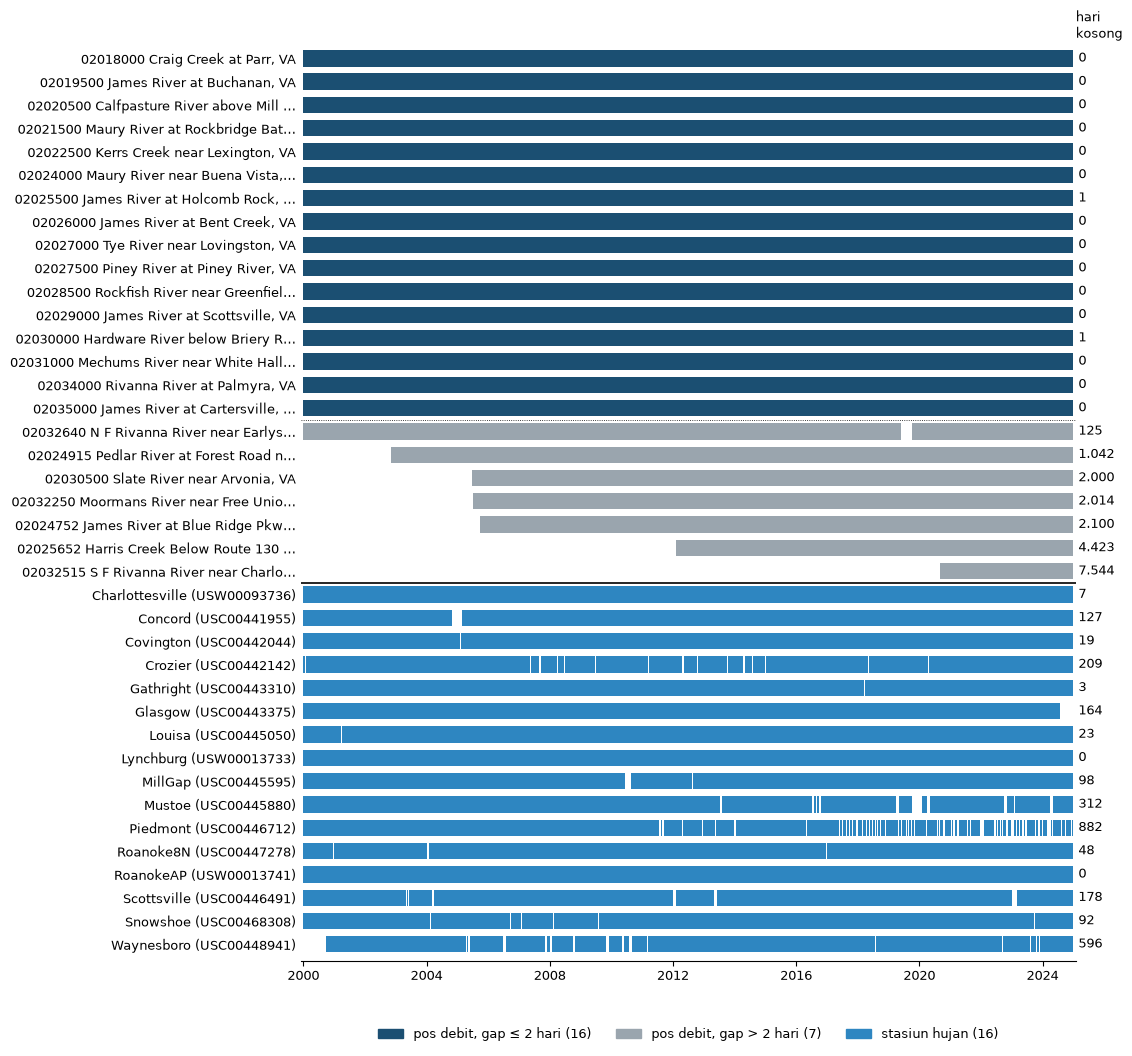


pos dengan gap lebih dari 2 hari:
     pos      mulai  hari_kosong  gap_di_tengah
02032640 2000-01-01          125            125
02024915 2002-11-08         1042              0
02030500 2005-06-23         2000              0
02032250 2005-07-07         2014              0
02024752 2005-10-01         2100              0
02025652 2012-02-09         4423              1
02032515 2020-08-27         7544              0


In [12]:
prcp_mentah = {s: urai_prcp(RAW / "hujan" / "dly" / f"{s}.dly", PERIODE[0].year, PERIODE[-1].year)
               for s in STASIUN}
ada_hujan = (pd.DataFrame({s: (d_["nilai"] != -9999) & (d_["Q"] == " ")
                           for s, d_ in prcp_mentah.items()})
             .reindex(PERIODE).fillna(False).astype(bool))

pendek = sorted(mutu.loc[mutu["gap_maks"] <= 2, "pos"])
panjang = sorted(mutu.loc[mutu["gap_maks"] > 2, "pos"], key=lambda k: Q_semua[k].first_valid_index())
urut_hujan = sorted(STASIUN, key=NAMA_PENDEK.get)
baris = ([("Q", k, Q_semua[k].notna(), True) for k in pendek]
         + [("Q", k, Q_semua[k].notna(), False) for k in panjang]
         + [("R", s, ada_hujan[s], None) for s in urut_hujan])

def runs(ada):
    a = ada.to_numpy().astype(int)
    d_ = np.diff(np.r_[0, a, 0])
    return list(zip(np.where(d_ == 1)[0], np.where(d_ == -1)[0]))

x0 = mdates.date2num(PERIODE[0])
fig, ax = plt.subplots(figsize=(10, 0.27 * len(baris) + 1.4))
for i, (jenis, k, ada, lolos_) in enumerate(baris):
    y_ = len(baris) - 1 - i
    w = WARNA["hujan"] if jenis == "R" else (WARNA["utama"] if lolos_ else WARNA["abu"])
    ax.broken_barh([(x0 + a, b - a) for a, b in runs(ada)], (y_ - 0.35, 0.7), color=w, lw=0)
    ax.text(mdates.date2num(PERIODE[-1]) + 60, y_, ribu((~ada).sum()), va="center", fontsize=9)
lab = [f"{k} {nama_pos(k)}" if j == "Q" else f"{NAMA_PENDEK[k]} ({k})" for j, k, _, _ in baris]
ax.set_yticks(range(len(baris))); ax.set_yticklabels(lab[::-1])
ax.axhline(len(baris) - len(pendek) - len(panjang) - 0.5, color="black", lw=1.2)
ax.axhline(len(baris) - len(pendek) - 0.5, color="black", lw=0.6, ls=":")
ax.set_xlim(x0 - 30, mdates.date2num(PERIODE[-1]) + 30)
ax.xaxis.set_major_locator(mdates.YearLocator(4)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.text(1.0, 1.0, "hari\nkosong", transform=ax.transAxes, ha="left", va="bottom", fontsize=9)
ax.set_ylim(-0.7, len(baris) - 0.3)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.legend(handles=[Patch(color=WARNA["utama"], label=f"pos debit, gap ≤ 2 hari ({len(pendek)})"),
                   Patch(color=WARNA["abu"], label=f"pos debit, gap > 2 hari ({len(panjang)})"),
                   Patch(color=WARNA["hujan"], label=f"stasiun hujan ({len(urut_hujan)})")],
          loc="upper center", bbox_to_anchor=(0.5, -0.06), ncol=3, frameon=False)
plt.show()

alasan = pd.DataFrame({
    "pos": panjang,
    "mulai": [Q_semua[k].first_valid_index().date() for k in panjang],
    "hari_kosong": [int(Q_semua[k].isna().sum()) for k in panjang],
    "gap_di_tengah": [int(Q_semua[k].loc[Q_semua[k].first_valid_index():].isna().sum()) for k in panjang],
})
print("\npos dengan gap lebih dari 2 hari:")
print(alasan.to_string(index=False))

In [13]:
mulai_telat = alasan[alasan["mulai"] > PERIODE[0].date()]
gap_tengah = alasan[alasan["mulai"] == PERIODE[0].date()]
ket = (
    f"Gambar 3. Ketersediaan data harian 2000–2024 untuk {Q_semua.shape[1]} pos debit USGS yang memiliki "
    f"deret debit harian dan {len(urut_hujan)} stasiun hujan GHCN-Daily. Batang menandai hari yang tersedia; "
    f"angka di kanan adalah jumlah hari kosong. Sebanyak {len(pendek)} pos tidak memiliki gap lebih dari "
    f"2 hari (biru tua) dan dipakai. Dari {len(panjang)} pos lainnya, {len(mulai_telat)} baru mulai merekam "
    f"antara {min(mulai_telat['mulai']).year} dan {max(mulai_telat['mulai']).year}"
    + (f", sedangkan {len(gap_tengah)} pos lengkap sejak awal tetapi memiliki gap "
       f"{int(gap_tengah['gap_di_tengah'].max())} hari berturut-turut" if len(gap_tengah) else "")
    + ". Hari kosong pada stasiun hujan mencakup nilai −9999, baris yang tidak ada, dan nilai yang gagal "
      "uji kualitas NOAA, sebelum penambalan."
)
print(ket)

Gambar 3. Ketersediaan data harian 2000–2024 untuk 23 pos debit USGS yang memiliki deret debit harian dan 16 stasiun hujan GHCN-Daily. Batang menandai hari yang tersedia; angka di kanan adalah jumlah hari kosong. Sebanyak 16 pos tidak memiliki gap lebih dari 2 hari (biru tua) dan dipakai. Dari 7 pos lainnya, 6 baru mulai merekam antara 2002 dan 2020, sedangkan 1 pos lengkap sejak awal tetapi memiliki gap 125 hari berturut-turut. Hari kosong pada stasiun hujan mencakup nilai −9999, baris yang tidak ada, dan nilai yang gagal uji kualitas NOAA, sebelum penambalan.


---
## 7. Penyaringan pos

Pos yang dipakai adalah pos dengan gap maksimum paling lama 2 hari, yaitu gap
yang cukup ditambal dengan interpolasi linear tanpa perlu diberi flag.

Aturan penambalan di tahap 20 sebenarnya mengizinkan gap sampai 7 hari, tetapi
nilai hasil tambalan untuk gap 3 sampai 7 hari harus diberi flag dan dikeluarkan
dari data uji. Karena itu penyaringan memakai batas yang lebih ketat, yaitu
2 hari.

Dengan batas ini, dua pos ikut terpilih walaupun tidak 100 persen lengkap.
Keduanya hanya kosong satu hari dari 9.132 hari:

- **02025500 James River at Holcomb Rock** (8.433 km²), pos di sungai utama.
  Jika pos ini dibuang, akan ada jarak 96 km tanpa pos di sungai utama antara
  02024000 dan 02026000.
- **02030000 Hardware River** (300 km²), pos di anak sungai.

Total nilai hasil interpolasi hanya 2 dari 146.112 sel, atau 0,0014 persen.

In [14]:
GAP_INTERP = 2     # <= 2 hari: interpolasi linear, tanpa flag
GAP_FLAG = 7     # 3-7 hari: interpolasi + flag, keluar dari data uji
                      # > 7 hari: pos dibuang

lolos  = mutu.loc[mutu["gap_maks"] <= GAP_INTERP, "pos"].tolist()
pos_flag = mutu.loc[(mutu["gap_maks"] > GAP_INTERP) &
                  (mutu["gap_maks"] <= GAP_FLAG), "pos"].tolist()
buang  = mutu.loc[mutu["gap_maks"] > GAP_FLAG, "pos"].tolist()

sempurna = mutu.loc[mutu["gap_maks"] == 0, "pos"].tolist()
print(f"gap 0 hari        -> dipakai  : {len(sempurna)} pos")
print(f"gap 1-2 hari      -> dipakai  : {len(lolos)-len(sempurna)} pos "
      f"{sorted(set(lolos)-set(sempurna))}")
print(f"gap 3-7 hari      -> ditolak  : {len(pos_flag)} pos {pos_flag}")
print(f"gap lebih 7 hari  -> ditolak  : {len(buang)} pos")
print(f"\nTOTAL dipakai: {len(lolos)} pos")
print(sorted(lolos))

gap 0 hari        -> dipakai  : 14 pos
gap 1-2 hari      -> dipakai  : 2 pos ['02025500', '02030000']
gap 3-7 hari      -> ditolak  : 0 pos []
gap lebih 7 hari  -> ditolak  : 7 pos

TOTAL dipakai: 16 pos
['02018000', '02019500', '02020500', '02021500', '02022500', '02024000', '02025500', '02026000', '02027000', '02027500', '02028500', '02029000', '02030000', '02031000', '02034000', '02035000']


---
# Bagian II — Metadata, jaringan sungai, dan atribut DAS

---
## 8. Metadata pos dari NWIS

File `site_info.rdb` memiliki 42 kolom, tetapi tidak semua kolom terisi. Sel
berikut memeriksa kolom mana saja yang bisa dipakai.

In [15]:
sinfo = baca_rdb(RAW/"sites"/"site_info.rdb").drop_duplicates("site_no")
sinfo = sinfo.set_index("site_no")
print(f"site_info.rdb: {sinfo.shape[0]} pos, {sinfo.shape[1]} kolom\n")

terisi = pd.Series({c: int((sinfo[c].astype(str).str.strip() != "").sum())
                    for c in sinfo.columns}).sort_values(ascending=False)
print("kolom KOSONG di semua pos:")
print("  " + ", ".join(terisi[terisi == 0].index) + "\n")
print("kolom yang terisi sebagian (perlu dicek):")
print(terisi[(terisi > 0) & (terisi < len(sinfo))].to_string())

site_info.rdb: 249 pos, 41 kolom

kolom KOSONG di semua pos:
  topo_cd, construction_dt, basin_cd, contrib_drain_area_va, land_net_ds, nat_aqfr_cd, aqfr_cd, aqfr_type_cd, well_depth_va, hole_depth_va, depth_src_cd

kolom yang terisi sebagian (perlu dicek):
map_nm            247
map_scale_fc      247
drain_area_va     219
gw_file_cd        153
inventory_dt      127
alt_acy_va         95
alt_datum_cd       95
alt_meth_cd        95
alt_va             95
project_no         21
reliability_cd     17


Kolom `alt_va` (elevasi) hanya terisi di sebagian pos. Karena elevasi akan
dipakai sebagai atribut, kelengkapannya dicek khusus untuk pos yang terpilih.

In [16]:
sub = sinfo.loc[[k for k in lolos if k in sinfo.index]]
for kol, nm in [("alt_va", "elevasi"), ("drain_area_va", "luas DAS"),
                ("dec_lat_va", "lintang"), ("huc_cd", "kode HUC")]:
    ada = int((sub[kol].astype(str).str.strip() != "").sum())
    status = "aman" if ada == len(sub) else "ADA YANG KOSONG"
    print(f"  {nm:12}: {ada}/{len(sub)}  {status}")

meta = pd.DataFrame({
    "nama": sub["station_nm"].str.strip(),
    "lintang": pd.to_numeric(sub["dec_lat_va"], errors="coerce"),
    "bujur": pd.to_numeric(sub["dec_long_va"], errors="coerce"),
    "elevasi_m": pd.to_numeric(sub["alt_va"], errors="coerce") * FT_KE_M,
    "luas_km2": pd.to_numeric(sub["drain_area_va"], errors="coerce") * MI2_KE_KM2,
    "huc": sub["huc_cd"],
})
meta.round(1)

  elevasi     : 16/16  aman
  luas DAS    : 16/16  aman
  lintang     : 16/16  aman
  kode HUC    : 16/16  aman


,nama,lintang,bujur,elevasi_m,luas_km2,huc
site_no,,,,,,
02018000,"CRAIG CREEK AT PARR, VA",37.7,-79.9,302.4,852.1,02080201
02019500,"JAMES RIVER AT BUCHANAN, VA",37.5,-79.7,244.5,5369.0,02080201
02020500,"CALFPASTURE RIVER ABOVE MILL CREEK AT GOSHEN, VA",38.0,-79.5,421.3,365.2,02080202
02021500,"MAURY RIVER AT ROCKBRIDGE BATHS, VA",37.9,-79.4,335.2,852.1,02080202
02022500,"KERRS CREEK NEAR LEXINGTON, VA",37.8,-79.4,298.9,90.9,02080202
02024000,"MAURY RIVER NEAR BUENA VISTA, VA",37.8,-79.4,257.8,1675.7,02080202
02026000,"JAMES RIVER AT BENT CREEK, VA",37.5,-78.8,115.9,9450.9,02080203
02027000,"TYE RIVER NEAR LOVINGSTON, VA",37.7,-79.0,175.1,240.9,02080203
02027500,"PINEY RIVER AT PINEY RIVER, VA",37.7,-79.0,192.3,123.5,02080203


---
## 9. Topologi jaringan dari NLDI

Data NLDI dipakai untuk memastikan bahwa pos yang terpilih benar-benar terhubung
secara hidrologis ke pos target, bukan hanya berdekatan di peta. Hal ini
penting karena CNN memperlakukan sumbu stasiun sebagai dimensi spasial, sehingga
sumbu tersebut hanya bermakna jika semua stasiunnya berada dalam satu jaringan
sungai.

In [17]:
nldi = json.loads((RAW/"network"/"nldi_upstream_02035000.json").read_text())
fitur = nldi["features"]
jar = pd.DataFrame([{
    "pos": f["properties"]["identifier"].replace("USGS-", ""),
    "nama": f["properties"]["name"],
    "comid": f["properties"]["comid"],
    "mainstem": f["properties"].get("mainstem", ""),
} for f in fitur])

print(f"pos terhubung ke jaringan James (NLDI mode UT, radius 300 km): {len(jar)}")
print(f"pos yang punya debit harian                                  : {len(file_debit)}")
print(f"pos yang lolos penyaringan                                   : {len(lolos)}")
hil = [k for k in lolos if k not in set(jar['pos'])]
print(f"\n{len(lolos)} pos terpilih seluruhnya ada di jaringan: {'ya' if not hil else 'TIDAK: '+str(hil)}")

pos terhubung ke jaringan James (NLDI mode UT, radius 300 km): 249
pos yang punya debit harian                                  : 23
pos yang lolos penyaringan                                   : 16

16 pos terpilih seluruhnya ada di jaringan: ya


---
## 10. Atribut DAS dari GAGES-II

GAGES-II menyediakan ratusan atribut untuk setiap pos yang tersebar di 25
lembar. Sebelum atribut dipilih, isi datanya diperiksa terlebih dahulu.

In [18]:
gg = pd.read_csv(RAW/"gagesii"/"gagesii_atribut.csv", dtype={"STAID": str})
gg["STAID"] = gg["STAID"].str.zfill(8)
gg = gg.set_index("STAID")
lembar = pd.read_csv(RAW/"gagesii"/"gagesii_lembar.csv")

print(f"gagesii_atribut.csv: {gg.shape[0]} pos, {gg.shape[1]} atribut\n")
kos = gg.isna().sum()
print(f"atribut lengkap di semua pos : {int((kos==0).sum())}")
print(f"atribut kosong total         : {int((kos==len(gg)).sum())}")
print(f"atribut kosong sebagian      : {int(((kos>0)&(kos<len(gg))).sum())}\n")
print(lembar[lembar['status'].str.contains('ditemukan')]
      .sort_values('atribut', ascending=False).to_string(index=False))

gagesii_atribut.csv: 16 pos, 571 atribut

atribut lengkap di semua pos : 565
atribut kosong total         : 2
atribut kosong sebagian      : 4

            lembar  atribut           status
           FlowRec      115 16 pos ditemukan
Climate_Ppt_Annual       60 16 pos ditemukan
Climate_Tmp_Annual       60 16 pos ditemukan
           Climate       49 16 pos ditemukan
             Hydro       33 16 pos ditemukan
     HydroMod_Dams       28 16 pos ditemukan
             Soils       24 16 pos ditemukan
          LC_Crops       22 16 pos ditemukan
        LC06_Basin       19 16 pos ditemukan
     LC06_Mains800       19 16 pos ditemukan
       LC06_Rip800       19 16 pos ditemukan
       LC06_Rip100       19 16 pos ditemukan
     LC06_Mains100       19 16 pos ditemukan
           Regions       14 16 pos ditemukan
           BasinID       14 16 pos ditemukan
    HydroMod_Other       12 16 pos ditemukan
              Topo       12 16 pos ditemukan
      Pop_Infrastr        7 16 pos ditemukan
 

### Isi lembar `FlowRec`

Isi lembar `FlowRec` untuk 16 pos yang lolos penyaringan.

In [19]:
fr = [c for c in gg.columns if c.startswith("FlowRec__")]
wy = [c for c in fr if c.split("__")[1].startswith("wy")]
fr_lain = [c for c in fr if c not in wy]
print(f"FlowRec: {len(fr)} kolom")
print(f"  {len(wy)} flag tahun air: {wy[0].split('__')[1]} s.d. {wy[-1].split('__')[1]}")
print(f"  {len(fr_lain)} kolom lain  : {[c.split('__')[1] for c in fr_lain]}\n")

g16 = gg.loc[lolos]
print("kolom selain flag tahun air, 16 pos:")
print(g16[fr_lain].rename(columns=lambda c: c.split("__")[1]).to_string())

wy_baru = [f"FlowRec__wy{t}" for t in range(PERIODE[0].year, 2010)]
print(f"\nflag tahun air {PERIODE[0].year}-2009 (irisan dengan periode penelitian):")
print(f"  nilai unik per kolom di 16 pos: {g16[wy_baru].nunique().to_dict()}")
print(f"  nilainya: {sorted(pd.unique(g16[wy_baru].to_numpy().ravel()))}")

FlowRec: 115 kolom
  110 flag tahun air: wy1900 s.d. wy2009
  5 kolom lain  : ['FLOW_PCT_EST_VALUES', 'ACTIVE09', 'FLOWYRS_1900_2009', 'FLOWYRS_1950_2009', 'FLOWYRS_1990_2009']

kolom selain flag tahun air, 16 pos:
          FLOW_PCT_EST_VALUES ACTIVE09  FLOWYRS_1900_2009  FLOWYRS_1950_2009  FLOWYRS_1990_2009
STAID                                                                                          
02018000                 0.59      yes                 84                 60                 20
02019500                 0.31      yes                 99                 60                 20
02020500                 2.20      yes                 69                 58                 18
02021500                 1.19      yes                 81                 60                 20
02022500                 1.08      yes                 81                 60                 20
02024000                 0.88      yes                 71                 60                 20
02026000         

### Lembar yang tidak dipakai

**`FlowRec` (115 atribut)** berisi informasi tentang riwayat pencatatan alat
ukur: 110 kolom flag tahun air `wy1900` sampai `wy2009` (bernilai 1 jika data
tahun air tersebut lengkap), jumlah tahun dengan data lengkap
(`FLOWYRS_1900_2009`, `FLOWYRS_1950_2009`, `FLOWYRS_1990_2009`), persentase
nilai perkiraan (`FLOW_PCT_EST_VALUES`), dan status aktif pada 2009
(`ACTIVE09`). Semua atribut ini menggambarkan riwayat pemantauan pos, yaitu
tahun mana saja pos tersebut merekam aliran, sehingga tidak menjelaskan
perilaku DAS maupun pergerakan air dari hulu ke hilir.
Selain itu, untuk periode 2000 sampai 2009 kesepuluh kolom tahun air bernilai
sama di ke-16 pos, sehingga tidak membedakan satu pos dengan pos lainnya.

Lembar ini juga tidak membocorkan informasi periode uji, karena GAGES-II
berakhir pada 2009, sedangkan periode uji dimulai pada 2021.

**`Climate_Ppt_Annual` dan `Climate_Tmp_Annual`** berisi nilai tahunan, bukan
harian, dan berakhir pada 2009, sehingga tidak cocok dipakai sebagai atribut
statis maupun sebagai input deret waktu.

In [20]:
LEMBAR_DILARANG = ["FlowRec", "Climate_Ppt_Annual", "Climate_Tmp_Annual"]
dilarang = [c for c in gg.columns
            if any(c.startswith(l + "__") for l in LEMBAR_DILARANG)]
print(f"atribut yang tidak dipakai: {len(dilarang)}")
print("contoh:", [c.split('__')[1] for c in dilarang[:8]])
gg_aman = gg.drop(columns=dilarang)
print(f"\nsisa atribut: {gg_aman.shape[1]}")

atribut yang tidak dipakai: 235
contoh: ['PPT1950_AVG', 'PPT1951_AVG', 'PPT1952_AVG', 'PPT1953_AVG', 'PPT1954_AVG', 'PPT1955_AVG', 'PPT1956_AVG', 'PPT1957_AVG']

sisa atribut: 336


---
## 11. Atribut spasial turunan

Beberapa atribut yang penting untuk penelitian ini tidak tersedia di GAGES-II,
karena GAGES-II menjelaskan setiap DAS secara terpisah, bukan posisinya
terhadap pos lain. Atribut berikut dihitung dari data NLDI dengan skrip `00c`:

- **Jarak alur ke pos target**, yaitu panjang sungai dari pos sampai pos target.
  Alur ditelusuri ke hilir lalu dikurangi alur milik pos target. Atribut ini
  menunjukkan posisi pos di jaringan sungai dan menentukan waktu tempuh air.
- **Kemiringan dasar sungai ke pos target**, yaitu selisih elevasi dibagi jarak alur.
  Atribut ini berkaitan dengan kecepatan rambat air.
- **Indeks kebulatan DAS**, yaitu 4πA/P². Nilai yang mendekati 1 berarti DAS
  berbentuk bulat dengan hidrograf yang tajam, sedangkan nilai kecil berarti DAS
  memanjang dengan hidrograf yang lebih landai.

In [21]:
sp = pd.read_csv(RAW/"spatial"/"atribut_turunan.csv", dtype={"kode_pos": str})
sp["kode_pos"] = sp["kode_pos"].str.zfill(8)
sp = sp.set_index("kode_pos")
print(f"atribut_turunan.csv: {sp.shape[0]} pos, {sp.shape[1]} kolom")
print(f"nilai kosong: {int(sp.isna().sum().sum())}\n")
print(sp.isna().sum()[sp.isna().sum() > 0].to_string())

atribut_turunan.csv: 16 pos, 13 kolom
nilai kosong: 1

kemiringan_ke_muara_m_per_km    1


Ada satu nilai kosong, yaitu kemiringan di pos target. Jarak pos target ke
dirinya sendiri adalah nol sehingga kemiringannya tidak bisa dihitung, jadi
nilai ini diisi nol.

---
## 12. Urutan stasiun berdasarkan jarak alur

Stasiun diurutkan berdasarkan jarak alur sungai ke pos target, dari yang
terjauh sampai pos target sendiri.

Sumbu stasiun adalah dimensi yang dikonvolusi oleh CNN, sehingga kernel yang
bergerak di sepanjang sumbu ini perlu bergerak sepanjang urutan yang bermakna
secara fisik. Dengan urutan jarak alur, stasiun yang bersebelahan di tensor juga
berdekatan di sungai. Jika stasiun diurutkan berdasarkan luas DAS atau kode pos,
kernel CNN akan menggabungkan stasiun yang letaknya berjauhan.

Urutan ini memiliki dua keterbatasan. Pertama, urutan relatif pos 02031000
(110,2 km) dan 02028500 (109,6 km) tidak tegas. Selisih jarak alurnya hanya
0,6 km, lebih kecil daripada panjang segmen alur NHDPlus di sepanjang lintasan
kedua pos tersebut, yang rata-ratanya 1,0 sampai 1,6 km. Karena posisi pos di
dalam segmennya sendiri tidak diperhitungkan, selisih sekecil itu berada di
dalam ketelitian data geometri alurnya. Kedua, jaringan sungai berbentuk pohon,
sedangkan sumbu stasiun berbentuk barisan. Keterbatasan kedua ini dibahas di
tahap 30.

In [22]:
TARGET = "02035000"
pos = [p for p in sp.sort_values("jarak_alur_ke_muara_km", ascending=False).index
       if p in lolos]
print(f"{len(pos)} stasiun, urut hulu -> hilir (target lolos: {TARGET in pos}, "
      f"paling hilir: {pos[-1] == TARGET}):\n")

tab = pd.DataFrame({
    "nama": meta.loc[pos, "nama"].str[:34],
    "elevasi_m": meta.loc[pos, "elevasi_m"].round(1),
    "luas_km2": meta.loc[pos, "luas_km2"].round(0),
    "jarak_alur_km": sp.loc[pos, "jarak_alur_ke_muara_km"],
    "kebulatan": sp.loc[pos, "kebulatan"],
})
print(tab.to_string())
jmax = tab["jarak_alur_km"].max()
print(f"\njarak alur terpanjang: {jmax:.1f} km")
print(f"taksiran waktu tempuh pada 1-2 m/s: "
      f"{jmax*1000/2/86400:.1f} - {jmax*1000/1/86400:.1f} hari")
print("-> sejalan dengan horizon prediksi 1 sampai 3 hari")

16 stasiun, urut hulu -> hilir (target lolos: True, paling hilir: True):

                                        nama  elevasi_m  luas_km2  jarak_alur_km  kebulatan
02018000             CRAIG CREEK AT PARR, VA      302.4     852.0          294.1      0.210
02020500  CALFPASTURE RIVER ABOVE MILL CREEK      421.3     365.0          281.2      0.244
02021500  MAURY RIVER AT ROCKBRIDGE BATHS, V      335.2     852.0          265.7      0.316
02022500      KERRS CREEK NEAR LEXINGTON, VA      298.9      91.0          249.4      0.498
02019500         JAMES RIVER AT BUCHANAN, VA      244.5    5369.0          241.4      0.216
02024000    MAURY RIVER NEAR BUENA VISTA, VA      257.8    1676.0          231.8      0.301
02025500     JAMES RIVER AT HOLCOMB ROCK, VA      167.0    8433.0          181.2      0.254
02027000       TYE RIVER NEAR LOVINGSTON, VA      175.1     241.0          135.9      0.394
02027500      PINEY RIVER AT PINEY RIVER, VA      192.3     124.0          132.4      0.451
020260

---
## 13. Pemilihan 10 atribut statis

Dari 571 atribut yang tersedia, dipilih 10 atribut yang berkaitan dengan
pergerakan air dari hulu ke hilir. Atribut yang tidak berhubungan dengan
perambatan air, misalnya penggunaan pestisida atau persentase kawasan lindung,
tidak dipakai.

Jumlah atribut dibatasi karena hanya ada 16 stasiun. Setiap atribut statis
hanya memiliki 16 nilai yang berbeda, sehingga menambah atribut menjadi 20 atau
30 tidak menambah banyak informasi, tetapi justru menambah risiko model
menghafal stasiun tertentu.

Satu dari sepuluh atribut, yaitu indeks aliran dasar (`BFI_AVE`), diturunkan
dari rekaman debit, sama seperti isi lembar `FlowRec` yang tidak dipakai.
Perbedaannya terletak pada apa yang digambarkan. `BFI_AVE` menggambarkan sifat
perilaku DAS, yaitu porsi aliran yang berasal dari simpanan air tanah, dan
lazim dipakai sebagai deskriptor DAS pada literatur hidrologi, termasuk
kumpulan data CAMELS. `FlowRec` menggambarkan riwayat pemantauan, yaitu tahun
mana saja pos merekam aliran, yang tidak menjelaskan perilaku DAS sama sekali.
`BFI_AVE` adalah rata-rata jangka panjang yang diterbitkan pada 2011, jadi
tidak memuat informasi periode uji.

Luas DAS diubah ke skala logaritma karena rentangnya lebih dari dua orde
besaran, yaitu dari 91 sampai 16.193 km². Logaritma ini hanya diterapkan pada
atribut statis, bukan pada debit yang diprediksi.

In [23]:
KOLOM_GG = {}     # atribut -> nama kolom lengkap di gagesii_atribut.csv, diperiksa di tahap 27
def gg_kol(atribut, nama):
    k = next((c for c in gg_aman.columns if c.endswith("__" + nama)), None)
    if k is None:
        raise KeyError(f"atribut {nama} tidak ada atau tidak dipakai")
    KOLOM_GG[atribut] = k
    return gg_aman.loc[pos, k]

A = pd.DataFrame(index=pos)
# posisi di jaringan (dihitung dari NLDI)
A["jarak_alur_km"]   = sp.loc[pos, "jarak_alur_ke_muara_km"]
A["kemiringan_alur"] = sp.loc[pos, "kemiringan_ke_muara_m_per_km"].fillna(0.0)
A["elevasi_pos_m"]   = meta.loc[pos, "elevasi_m"]
A["log_luas"]        = np.log10(meta.loc[pos, "luas_km2"])
A["kebulatan"]       = sp.loc[pos, "kebulatan"]
# sifat fisik DAS (GAGES-II)
A["elev_rata_das_m"] = gg_kol("elev_rata_das_m", "ELEV_MEAN_M_BASIN")
A["kemiringan_das"]  = gg_kol("kemiringan_das", "SLOPE_PCT")
A["hujan_tahunan_cm"]= gg_kol("hujan_tahunan_cm", "PPTAVG_BASIN")
A["aliran_dasar"]    = gg_kol("aliran_dasar", "BFI_AVE")
A["kerapatan_alur"]  = gg_kol("kerapatan_alur", "STREAMS_KM_SQ_KM")

ALASAN = {
 "jarak_alur_km":   "posisi di jaringan, menentukan waktu tempuh",
 "kemiringan_alur": "kecepatan rambat air ke pos target",
 "elevasi_pos_m":   "urutan hulu-hilir secara gravitasi",
 "log_luas":        "besaran DAS, menentukan besar aliran",
 "kebulatan":       "bentuk DAS, menentukan ketajaman hidrograf",
 "elev_rata_das_m": "elevasi seluruh DAS, bukan hanya titik posnya",
 "kemiringan_das":  "kecepatan limpasan permukaan",
 "hujan_tahunan_cm":"membedakan DAS basah dan kering",
 "aliran_dasar":    "porsi aliran dari simpanan air tanah (BFI_AVE); sifat perilaku DAS, bukan riwayat pemantauan",
 "kerapatan_alur":  "kerapatan jaringan alur, mempengaruhi waktu pengumpulan",
}
print(f"{len(A.columns)} atribut terpilih, kosong {int(A.isna().sum().sum())}\n")
for k, v in ALASAN.items():
    print(f"  {k:18} {v}")
print()
A.round(2)

10 atribut terpilih, kosong 0

  jarak_alur_km      posisi di jaringan, menentukan waktu tempuh
  kemiringan_alur    kecepatan rambat air ke pos target
  elevasi_pos_m      urutan hulu-hilir secara gravitasi
  log_luas           besaran DAS, menentukan besar aliran
  kebulatan          bentuk DAS, menentukan ketajaman hidrograf
  elev_rata_das_m    elevasi seluruh DAS, bukan hanya titik posnya
  kemiringan_das     kecepatan limpasan permukaan
  hujan_tahunan_cm   membedakan DAS basah dan kering
  aliran_dasar       porsi aliran dari simpanan air tanah (BFI_AVE); sifat perilaku DAS, bukan riwayat pemantauan
  kerapatan_alur     kerapatan jaringan alur, mempengaruhi waktu pengumpulan



,jarak_alur_km,kemiringan_alur,elevasi_pos_m,log_luas,kebulatan,elev_rata_das_m,kemiringan_das,hujan_tahunan_cm,aliran_dasar,kerapatan_alur
02018000,294.1,0.86,302.41,2.93,0.21,634.99,18.12,108.92,48.02,1.08
02020500,281.2,1.32,421.33,2.56,0.24,714.26,19.87,113.64,43.01,0.41
02021500,265.7,1.07,335.21,2.93,0.32,657.15,17.93,115.27,42.38,0.53
02022500,249.4,0.99,298.95,1.96,0.50,523.89,17.97,113.91,43.18,1.12
02019500,241.4,0.80,244.48,3.73,0.22,647.71,18.83,107.33,44.24,0.82
02024000,231.8,0.89,257.78,3.22,0.30,589.72,16.56,114.88,43.66,0.68
02025500,181.2,0.64,166.98,3.93,0.25,603.35,18.26,110.86,44.55,0.82
02027000,135.9,0.91,175.14,2.38,0.39,548.43,22.11,131.50,51.91,1.01
02027500,132.4,1.07,192.27,2.09,0.45,640.08,25.64,139.90,49.52,1.00
02026000,114.3,0.57,115.95,3.98,0.20,560.79,17.03,111.35,45.50,0.84


In [24]:
A = A.fillna(A.mean())
# standardisasi antar stasiun, bukan antar waktu (nilainya statis); ddof=0 seperti scaling debit
As = ((A - A.mean()) / A.std(ddof=0).replace(0, 1)).to_numpy(float)
print(f"atribut distandarkan: {As.shape}  (stasiun x atribut)")
print(f"rentang: {As.min():+.2f} sampai {As.max():+.2f} standar deviasi")
pd.DataFrame(As, index=pos, columns=A.columns).round(2)

atribut distandarkan: (16, 10)  (stasiun x atribut)
rentang: -2.49 sampai +2.83 standar deviasi


,jarak_alur_km,kemiringan_alur,elevasi_pos_m,log_luas,kebulatan,elev_rata_das_m,kemiringan_das,hujan_tahunan_cm,aliran_dasar,kerapatan_alur
02018000,1.50,0.26,1.05,-0.14,-1.13,0.81,0.28,-0.99,0.59,1.29
02020500,1.36,1.75,2.18,-0.64,-0.78,1.33,0.71,-0.41,-1.16,-2.28
02021500,1.20,0.95,1.36,-0.14,-0.03,0.96,0.24,-0.21,-1.38,-1.64
02022500,1.02,0.71,1.02,-1.47,1.85,0.08,0.25,-0.37,-1.10,1.48
02019500,0.93,0.09,0.49,0.96,-1.07,0.90,0.46,-1.19,-0.73,-0.09
02024000,0.83,0.38,0.62,0.26,-0.19,0.52,-0.09,-0.26,-0.93,-0.81
02025500,0.28,-0.43,-0.25,1.22,-0.67,0.60,0.32,-0.75,-0.62,-0.09
02027000,-0.22,0.45,-0.17,-0.89,0.78,0.25,1.25,1.79,1.94,0.92
02027500,-0.26,0.95,-0.00,-1.28,1.37,0.85,2.10,2.83,1.11,0.85
02026000,-0.45,-0.66,-0.73,1.29,-1.26,0.33,0.02,-0.69,-0.29,0.01


### Tabel 1 — Karakteristik pos

Luas DAS dan elevasi diambil dari NWIS, jarak alur dari NLDI, persentase nilai
perkiraan dari kode kualitas `A:e`, dan statistik debit dihitung dari seluruh
periode 2000–2024 dalam m³/s. Debit di tabel ini belum ditambal (tahap 20),
sehingga dua nilai kosong diabaikan.

In [25]:
Qp = Q_semua[pos]
tab1 = pd.DataFrame({
    "no": range(1, len(pos) + 1),
    "kode_pos": pos,
    "nama": [nama_pos(p, 60) for p in pos],
    "luas_km2": sp.loc[pos, "luas_nwis_km2"].round(0).to_numpy(),
    "elevasi_m": sp.loc[pos, "elevasi_m"].round(1).to_numpy(),
    "jarak_alur_km": sp.loc[pos, "jarak_alur_ke_muara_km"].to_numpy(),
    "perkiraan_persen": (E_semua[pos].mean() * 100).round(1).to_numpy(),
    "q_min": Qp.min().round(2).to_numpy(),
    "q_median": Qp.median().round(2).to_numpy(),
    "q_maks": Qp.max().round(1).to_numpy(),
    "q_std": Qp.std().round(2).to_numpy(),
})
print(tab1.to_string(index=False))

 no kode_pos                                                 nama  luas_km2  elevasi_m  jarak_alur_km  perkiraan_persen  q_min  q_median  q_maks  q_std
  1 02018000                              Craig Creek at Parr, VA     852.0      302.4          294.1               1.3   0.64      5.66   376.6  19.20
  2 02020500     Calfpasture River above Mill Creek at Goshen, VA     365.0      421.3          281.2               5.4   0.01      1.90   232.8  10.06
  3 02021500                  Maury River at Rockbridge Baths, VA     852.0      335.2          265.7               3.2   0.27      4.73   351.1  20.26
  4 02022500                       Kerrs Creek near Lexington, VA      91.0      298.9          249.4               3.9   0.06      0.48    56.4   2.09
  5 02019500                          James River at Buchanan, VA    5369.0      244.5          241.4               1.3   9.09     37.52  1834.9  95.36
  6 02024000                     Maury River near Buena Vista, VA    1676.0      257.8  

---
# Bagian III — Curah hujan

Model dasar hanya memakai debit, mengikuti Ghimire dkk. (2021). Bagian ini
menyiapkan data hujan untuk eksperimen terpisah. Hasilnya disimpan di
`processed/hujan/` dan di tensor `processed/tensor_hujan_h*.npz`, terpisah dari
tensor debit.

USGS tidak menyediakan data curah hujan untuk pos-pos di jaringan ini, sehingga
data hujan diambil dari NOAA GHCN-Daily, yaitu 16 stasiun di dalam dan di
sekitar DAS.

---
## 14. Membaca format `.dly`

Format file `.dly` dijelaskan di `raw/hujan/ghcnd-readme.txt`. Bagian yang
dipakai adalah tata letak kolom (bagian III), definisi flag pengukuran (MFLAG),
dan flag kualitas (QFLAG).

In [26]:
readme = (RAW / "hujan" / "ghcnd-readme.txt").read_text().splitlines()
def potong(awal, akhir):
    i = next(n for n, b in enumerate(readme) if b.startswith(awal))
    j = next(n for n, b in enumerate(readme[i + 1:], i + 1) if b.startswith(akhir))
    return readme[i:j]

for b in potong("III. FORMAT OF DATA FILES", "These variables have"):
    print(b)
print("...")
for b in readme:
    if b.strip().startswith(("PRCP =", "VALUE1     is")):
        print(b)
qf = potong("QFLAG1     is", "SFLAG1     is")
print("\n".join(qf))

III. FORMAT OF DATA FILES (".dly" FILES)

Each ".dly" file contains data for one station.  The name of the file
corresponds to a station's identification code.  For example, "USC00026481.dly"
contains the data for the station with the identification code USC00026481).

Each record in a file contains one month of daily data.  The variables on each
line include the following:

------------------------------
Variable   Columns   Type
------------------------------
ID            1-11   Character
YEAR         12-15   Integer
MONTH        16-17   Integer
ELEMENT      18-21   Character
VALUE1       22-26   Integer
MFLAG1       27-27   Character
QFLAG1       28-28   Character
SFLAG1       29-29   Character
VALUE2       30-34   Integer
MFLAG2       35-35   Character
QFLAG2       36-36   Character
SFLAG2       37-37   Character
  .           .          .
  .           .          .
  .           .          .
VALUE31    262-266   Integer
MFLAG31    267-267   Character
QFLAG31    268-268   Characte

Poin penting dari dokumentasi:

- kolom 1–11 berisi kode stasiun, 12–15 tahun, 16–17 bulan, dan 18–21 elemen
- setelah itu ada 31 blok berukuran 8 karakter, masing-masing berisi 5 karakter
  nilai lalu MFLAG, QFLAG, dan SFLAG yang masing-masing 1 karakter
- `PRCP` dicatat dalam persepuluh milimeter, dan missing value ditulis `-9999`
- QFLAG kosong berarti nilai lolos semua uji kualitas, sedangkan huruf apa pun
  berarti gagal
- setiap bulan tetap memiliki 31 blok walaupun jumlah harinya kurang dari 31.
  Blok untuk tanggal yang tidak ada, seperti 30 Februari atau 31 April,
  dilewati agar tidak terhitung sebagai missing value.

Fungsi `urai_prcp` di sel persiapan dibuat mengikuti tata letak ini. Untuk
memastikan pemotongannya tepat, satu baris mentah ditampilkan beserta nomor
kolomnya.

In [27]:
contoh_dly = RAW / "hujan" / "dly" / "USW00013733.dly"
baris_prcp = next(b for b in contoh_dly.read_text().splitlines() if b[17:21] == "PRCP" and b[11:15] == "2003")
print("kolom : " + "".join(str(i // 10 % 10) if i % 10 == 0 else " " for i in range(1, 70)))
print("        " + "".join(str(i % 10) for i in range(1, 70)))
print(f"baris : {baris_prcp[:69]}")
print(f"\nstasiun {baris_prcp[0:11]} | tahun {baris_prcp[11:15]} | bulan {baris_prcp[15:17]} | elemen {baris_prcp[17:21]}")
for i in range(5):
    p = 21 + 8 * i
    blok = baris_prcp[p:p + 8]
    print(f"  tgl {i+1}: '{blok}' -> nilai {int(blok[:5]):>5} ({int(blok[:5])/10:5.1f} mm)  "
          f"M='{blok[5]}' Q='{blok[6]}' S='{blok[7]}'")
t0 = pd.Timestamp(int(baris_prcp[11:15]), int(baris_prcp[15:17]), 1)
print(f"\nhasil urai_prcp untuk tanggal yang sama: {prcp_mentah['USW00013733'].loc[t0:t0 + pd.Timedelta(days=4), 'nilai'].tolist()}")

kolom :          1         2         3         4         5         6         
        123456789012345678901234567890123456789012345678901234567890123456789
baris : USW00013733200301PRCP  170  0    5  0   84  0    0  0    5  0    0T 0

stasiun USW00013733 | tahun 2003 | bulan 01 | elemen PRCP
  tgl 1: '  170  0' -> nilai   170 ( 17.0 mm)  M=' ' Q=' ' S='0'
  tgl 2: '    5  0' -> nilai     5 (  0.5 mm)  M=' ' Q=' ' S='0'
  tgl 3: '   84  0' -> nilai    84 (  8.4 mm)  M=' ' Q=' ' S='0'
  tgl 4: '    0  0' -> nilai     0 (  0.0 mm)  M=' ' Q=' ' S='0'
  tgl 5: '    5  0' -> nilai     5 (  0.5 mm)  M=' ' Q=' ' S='0'

hasil urai_prcp untuk tanggal yang sama: [170, 5, 84, 0, 5]


### Tiga jenis nilai kosong

Seluruh blok sudah dibaca di tahap 6 dan disimpan di `prcp_mentah` bersama
ketiga flag-nya. Nilai kosong dibedakan menurut penyebabnya:

| Jenis | Arti |
|---|---|
| baris tidak ada | NOAA tidak memiliki catatan `PRCP` untuk bulan tersebut |
| `-9999` | baris bulan tersebut ada, tetapi nilai pada hari itu kosong |
| gagal uji kualitas | nilainya ada, tetapi QFLAG terisi sehingga NOAA menandainya tidak layak |

Ketiganya diperlakukan sebagai nilai kosong, tetapi jumlahnya dihitung
terpisah.

In [28]:
V = pd.DataFrame({s: d_["nilai"] for s, d_ in prcp_mentah.items()}).reindex(PERIODE)
MF = pd.DataFrame({s: d_["M"] for s, d_ in prcp_mentah.items()}).reindex(PERIODE)
QF = pd.DataFrame({s: d_["Q"] for s, d_ in prcp_mentah.items()}).reindex(PERIODE)

tidak_ada = V.isna()
kosong_9999 = V.eq(-9999)
gagal_mutu = QF.fillna(" ").ne(" ") & ~kosong_9999 & ~tidak_ada
print(f"matriks mentah: {V.shape} (hari x stasiun)")
print(f"baris tidak ada  : {int(tidak_ada.sum().sum()):,}")
print(f"-9999 eksplisit  : {int(kosong_9999.sum().sum()):,}")
print(f"gagal uji kualitas: {int(gagal_mutu.sum().sum()):,}")
kode_q = pd.Series(QF[gagal_mutu].stack().values).value_counts()
arti_q = {b.split("=")[0].strip(): b.split("=")[1].strip() for b in qf if "= " in b and "failed" in b or "Datzilla" in b}
print("\nkode QFLAG yang muncul:")
for k, n in kode_q.items():
    print(f"  {k}: {n:>4}  {arti_q.get(k, '')}")

sah_h = ~(tidak_ada | kosong_9999 | gagal_mutu)
mm = (V / 10.0).where(sah_h)           # mm/hari, tanggal sesuai file .dly

matriks mentah: (9132, 16) (hari x stasiun)
baris tidak ada  : 1,129
-9999 eksplisit  : 1,471
gagal uji kualitas: 158

kode QFLAG yang muncul:
  L:   95  failed check on length of multiday period
  D:   60  failed duplicate check
  I:    3  failed internal consistency check


---
## 15. Kualitas stasiun hujan dan koreksi jam pengamatan

### 15a. Koordinat stasiun

Koordinat stasiun dibaca dari `raw/hujan/stasiun_terpakai.txt`. File ini adalah
hasil saringan `ghcnd-stations.txt` milik NOAA (11 MB, lebih dari 100 ribu
stasiun) menjadi 16 baris stasiun yang dipakai, dengan format kolom tetap yang
sama dan isi baris yang tidak diubah. Penyaringan dikerjakan skrip `00d`.
Salinan ini disimpan di repository karena koordinatnya menentukan urutan
stasiun, penentuan tetangga, dan bobot IDW. Jika koordinat dibaca langsung dari
server NOAA setiap kali notebook dijalankan, revisi di sisi NOAA akan mengubah
hasil bagian hujan tanpa diketahui. Koordinat yang sama juga disimpan ke
`processed/hujan/stasiun_hujan.csv` di tahap 28.

In [29]:
teks = (RAW / "hujan" / "stasiun_terpakai.txt").read_text()
st = pd.DataFrame([{"id": b[0:11], "lintang": float(b[12:20]), "bujur": float(b[21:30]),
                    "elevasi_m": float(b[31:37]), "nama": b[41:71].strip()}
                   for b in teks.splitlines() if b[0:11] in set(STASIUN)]).set_index("id")
assert set(st.index) == set(STASIUN), "stasiun_terpakai.txt tidak memuat seluruh stasiun"
st["label"] = st.index.map(NAMA_PENDEK)
st["jaringan"] = np.where(st.index.str.startswith("USW"), "bandara (first-order)", "COOP")
st = st.sort_values("bujur")
ST = list(st.index)                     # urutan baku: barat ke timur
D_ss = pd.DataFrame(jarak_km(st.lintang.values[:, None], st.bujur.values[:, None],
                             st.lintang.values[None, :], st.bujur.values[None, :]), index=ST, columns=ST)
print(st.to_string())

             lintang    bujur  elevasi_m                          nama            label               jaringan
id                                                                                                            
USC00468308  38.4014 -79.9953     1463.6                      SNOWSHOE         Snowshoe                   COOP
USC00442044  37.8111 -79.9883      379.2            COVINGTON FLTR PLT        Covington                   COOP
USW00013741  37.3172 -79.9736      346.9    ROANOKE-BLACKSBURG RGNL AP        RoanokeAP  bandara (first-order)
USC00447278  37.3622 -79.9586      352.7                   ROANOKE 8 N        Roanoke8N                   COOP
USC00443310  37.9458 -79.9542      539.5                 GATHRIGHT DAM        Gathright                   COOP
USC00445595  38.3064 -79.7200      736.4                      MILL GAP          MillGap                   COOP
USC00445880  38.3144 -79.6589      721.5                   MUSTOE 1 SW           Mustoe                   COOP
U

### 15b. Flag pengukuran (MFLAG)

Ada dua flag yang muncul pada nilai yang lolos uji kualitas: `T` (*trace*, hujan
terlalu sedikit untuk diukur dan bernilai 0) dan `P` (*missing presumed zero*,
dicatat kosong oleh pengamat lalu dianggap nol). Nilai `T` jelas bernilai nol.
Nilai `P` perlu diperiksa, karena jika hari ber-`P` ternyata sering merupakan
hari hujan, nilainya seharusnya dijadikan kosong.

Hari ber-`P` dibandingkan dengan hari nol biasa di stasiun yang sama, dengan
stasiun bandara terdekat sebagai acuan. Jika `P` menyembunyikan hujan, stasiun
bandara akan lebih sering mencatat hujan pada hari ber-`P` dibandingkan pada
hari nol biasa.

In [30]:
print("flag M pada nilai yang valid:")
print(pd.DataFrame({s: MF[s][sah_h[s]].replace(" ", np.nan).value_counts() for s in ST})
      .fillna(0).astype(int).rename(columns=NAMA_PENDEK).T.to_string())

bandara = [s for s in ST if s.startswith("USW")]
baris = []
for s in ST:
    p = MF[s].eq("P") & sah_h[s]
    if p.sum() < 100:
        continue
    acuan = min(bandara, key=lambda b: D_ss.at[s, b])
    nol = mm[s].eq(0) & ~p
    # window +/- 1 hari agar tidak terpengaruh perbedaan jam pengamatan (15c)
    ref = mm[acuan].rolling(3, center=True).max()
    baris.append({"stasiun": NAMA_PENDEK[s], "acuan": NAMA_PENDEK[acuan], "hari_P": int(p.sum()),
                  "acuan_hujan_saat_P_%": round((ref[p] >= 1).mean() * 100, 1),
                  "acuan_hujan_saat_nol_biasa_%": round((ref[nol] >= 1).mean() * 100, 1)})
cek_p = pd.DataFrame(baris)
print("\npersentase hari acuan mencatat >= 1 mm (window +/-1 hari):")
print(cek_p.to_string(index=False))

flag M pada nilai yang valid:
                    P     T
Snowshoe           46    29
Covington         405   253
RoanokeAP           0  1218
Roanoke8N          56   147
Gathright          17   500
MillGap            29   394
Mustoe           1807   440
Glasgow            21   561
Lynchburg           0   987
Concord           965   102
Waynesboro         88   141
Charlottesville     0  1023
Scottsville      1056    33
Piedmont           20   527
Louisa             25    38
Crozier          1257     2

persentase hari acuan mencatat >= 1 mm (window +/-1 hari):
    stasiun           acuan  hari_P  acuan_hujan_saat_P_%  acuan_hujan_saat_nol_biasa_%
  Covington       RoanokeAP     405                  38.8                          38.8
     Mustoe Charlottesville    1807                  35.5                          37.2
    Concord       Lynchburg     965                  38.0                          38.1
Scottsville Charlottesville    1056                  35.5                         

Hari ber-`P` tidak lebih sering hujan di stasiun acuan dibandingkan hari nol
biasa. Selisihnya kecil dan justru ke arah sebaliknya, sehingga nilai ber-`P`
dipakai sebagai nol. Flag `P` sebagian besar muncul pada tahun-tahun awal
(2000–2010) di stasiun COOP.

### 15c. Perbedaan jam pengamatan

Stasiun bandara (`USW`) mencatat hujan dari tengah malam sampai tengah malam,
sama dengan kalender debit harian USGS. Sebagian besar stasiun COOP (`USC`)
dibaca oleh pengamat pada pagi hari, dan hujan selama 24 jam sebelumnya dicatat
pada tanggal pembacaan. Akibatnya, hujan yang turun pada hari D di bandara akan
tercatat pada hari D+1 di stasiun COOP.

Contohnya terlihat pada Badai Isabel yang melintasi Virginia pada 18–19
September 2003 (tanggal sesuai file `.dly`):

In [31]:
print(mm.loc["2003-09-16":"2003-09-21", ["USW00013733", "USW00013741", "USC00443375", "USC00446491",
                                          "USC00447278", "USW00093736"]]
      .rename(columns=NAMA_PENDEK).to_string())

            Lynchburg  RoanokeAP  Glasgow  Scottsville  Roanoke8N  Charlottesville
2003-09-16        0.0        0.0      3.3          0.3        0.5              0.0
2003-09-17        0.0        0.3      0.0          0.0        0.0            112.5
2003-09-18       99.6       37.8      0.0          0.0        0.0             26.9
2003-09-19        0.8        0.3    121.4         99.1       55.9              0.0
2003-09-20        0.0        0.0      1.8          0.0        0.8              0.0
2003-09-21        0.0        0.0      0.0          0.0        0.0              0.0


Lynchburg dan RoanokeAP (bandara) mencatat puncak hujan pada 18 September,
sedangkan Glasgow, Scottsville, dan Roanoke8N (COOP) mencatat puncaknya pada 19
September untuk badai yang sama. Charlottesville, walaupun stasiun bandara,
mencatat puncaknya pada 17 September, sehari lebih awal dari bandara lainnya.

Untuk memeriksa semua stasiun, korelasi setiap stasiun terhadap stasiun bandara
Roanoke (datanya 100 persen lengkap) dihitung pada geseran 0 dan +1 hari, hanya
menggunakan data latih.

In [32]:
ACUAN = "USW00013741"
lat = mm.loc[LATIH]
uji_jam = pd.DataFrame({
    "label": st["label"], "jaringan": st["jaringan"],
    "r_geser_0": [lat[ACUAN].corr(lat[s]) for s in ST],
    "r_geser_+1": [lat[ACUAN].corr(lat[s].shift(-1)) for s in ST],
}, index=ST)
uji_jam["konvensi"] = np.where(uji_jam["r_geser_+1"] > uji_jam["r_geser_0"],
                               "terlambat sehari", "selaras bandara")
uji_jam.loc[ACUAN, "konvensi"] = "selaras bandara"
terlambat = [s for s in ST if uji_jam.at[s, "konvensi"] == "terlambat sehari"]
print(uji_jam.round(3).to_string())
print(f"\n{uji_jam['konvensi'].value_counts().to_dict()}")

print("\npasangan stasiun berdekatan dengan konvensi berbeda, korelasi pada geseran -1, 0, +1:")
for a, b in [("USW00013741", "USC00447278"), ("USW00013733", "USC00441955"), ("USW00093736", "USC00446491"),
             ("USW00093736", "USC00446712"), ("USC00445050", "USC00446712")]:
    r = [lat[a].corr(lat[b].shift(-k)) for k in (-1, 0, 1)]
    print(f"  {NAMA_PENDEK[a]:15} - {NAMA_PENDEK[b]:12} ({D_ss.at[a, b]:4.0f} km): "
          + "  ".join(f"{x:+.2f}" for x in r))

                       label               jaringan  r_geser_0  r_geser_+1          konvensi
USC00468308         Snowshoe                   COOP      0.187       0.481  terlambat sehari
USC00442044        Covington                   COOP      0.293       0.596  terlambat sehari
USW00013741        RoanokeAP  bandara (first-order)      1.000       0.157   selaras bandara
USC00447278        Roanoke8N                   COOP      0.390       0.739  terlambat sehari
USC00443310        Gathright                   COOP      0.296       0.548  terlambat sehari
USC00445595          MillGap                   COOP      0.269       0.535  terlambat sehari
USC00445880           Mustoe                   COOP      0.624       0.136   selaras bandara
USC00443375          Glasgow                   COOP      0.301       0.673  terlambat sehari
USW00013733        Lynchburg  bandara (first-order)      0.672       0.148   selaras bandara
USC00441955          Concord                   COOP      0.233       0

Sebelas stasiun memiliki korelasi yang jauh lebih tinggi terhadap acuan setelah
digeser satu hari. Contohnya Roanoke8N, yang hanya berjarak 5 km dari bandara
Roanoke: korelasinya 0,39 pada geseran 0 dan naik menjadi 0,74 pada geseran 1.
Lima stasiun lainnya sudah sejalan dengan bandara, yaitu ketiga stasiun bandara
serta Mustoe dan Louisa, dua stasiun COOP yang kemungkinan dibaca pada sore
atau malam hari.

Ada satu pasangan yang tidak mengikuti pola ini, yaitu Louisa–Piedmont, yang
korelasinya lebih tinggi pada geseran 0 daripada geseran 1. Terhadap acuan
Roanoke, Louisa termasuk sejalan dengan bandara, tetapi terhadap tetangga
terdekatnya Louisa terlihat mengikuti pola yang sama dengan Piedmont. Pembacaan
sore hari menghasilkan pergeseran sekitar setengah hari, sehingga tidak ada
geseran satu hari penuh yang cocok untuk kedua pasangan sekaligus.

### 15d. Arah koreksi berdasarkan kenaikan debit

Ada dua cara untuk menyamakan jam pengamatan:

- **memajukan** sebelas stasiun yang terlambat satu hari, sehingga semua
  stasiun mengikuti kalender bandara yang sama dengan kalender debit USGS
  (tengah malam sampai tengah malam);
- **memundurkan** lima stasiun lainnya satu hari, sehingga semua stasiun
  mengikuti pola pembacaan pagi COOP.

Kedua cara menghasilkan keselarasan antarstasiun yang sama. Perbedaannya hanya
pada posisi seluruh data hujan terhadap kalender debit, yang bergeser satu hari.
Karena itu arah koreksi diuji terhadap debit, yaitu dengan menghitung korelasi
hujan setiap stasiun pada hari t dengan kenaikan debit harian pos target pada
hari t + lag, untuk lag 0 sampai 3 hari, menggunakan data latih saja. Kenaikan
debit dihitung dari selisih harian yang nilai negatifnya dijadikan nol, karena
hujan hanya bisa menaikkan debit.

In [33]:
q_target = Q_semua[TARGET]
naik = q_target.diff().clip(lower=0)
LAG_UJI = range(4)

def profil_lag(Hx):
    return pd.DataFrame({s: [Hx[s].loc[LATIH].corr(naik.loc[LATIH].shift(-L)) for L in LAG_UJI]
                         for s in ST}, index=[f"t{L}" for L in LAG_UJI]).T

maju = pd.DataFrame({s: mm[s].shift(-1) if s in terlambat else mm[s] for s in ST})
p_sebelum, p_sesudah = profil_lag(mm), profil_lag(maju)
banding_lag = pd.concat({"sebelum": p_sebelum, "sesudah": p_sesudah}, axis=1).round(3)
banding_lag[("", "kelompok")] = ["terlambat" if s in terlambat else "selaras bandara" for s in ST]
banding_lag[("sebelum", "terbaik")] = p_sebelum.to_numpy().argmax(axis=1)
banding_lag[("sesudah", "terbaik")] = p_sesudah.to_numpy().argmax(axis=1)
banding_lag.index = [NAMA_PENDEK[s] for s in ST]
print(banding_lag.to_string())

print("\nlag yang memaksimalkan korelasi (jumlah stasiun):")
print(f"  sebelum koreksi: {banding_lag[('sebelum', 'terbaik')].value_counts().sort_index().to_dict()}")
print(f"  sesudah koreksi: {banding_lag[('sesudah', 'terbaik')].value_counts().sort_index().to_dict()}")

def titik_berat(p):
    q = p.clip(lower=0)
    return (q * np.arange(q.shape[1])).sum(axis=1) / q.sum(axis=1)
selaras_b = [s for s in ST if s not in terlambat]
berat_sebelum, berat_sesudah = titik_berat(p_sebelum), titik_berat(p_sesudah)
print("\ntitik berat profil lag (hari), rata-rata per kelompok:")
print(f"  sebelum: terlambat {berat_sebelum[terlambat].mean():.2f} | selaras bandara {berat_sebelum[selaras_b].mean():.2f} "
      f"| selisih {berat_sebelum[selaras_b].mean() - berat_sebelum[terlambat].mean():+.2f}")
print(f"  sesudah: terlambat {berat_sesudah[terlambat].mean():.2f} | selaras bandara {berat_sesudah[selaras_b].mean():.2f} "
      f"| selisih {berat_sesudah[selaras_b].mean() - berat_sesudah[terlambat].mean():+.2f}")

                sebelum                      sesudah                                       sebelum sesudah
                     t0     t1     t2     t3      t0     t1     t2     t3         kelompok terbaik terbaik
Snowshoe          0.251  0.357  0.107 -0.001  -0.007  0.251  0.357  0.107        terlambat       1       2
Covington         0.293  0.451  0.165  0.003   0.001  0.293  0.451  0.165        terlambat       1       2
RoanokeAP         0.031  0.405  0.397  0.073   0.031  0.405  0.397  0.073  selaras bandara       1       1
Roanoke8N         0.275  0.479  0.158  0.004   0.002  0.275  0.479  0.158        terlambat       1       2
Gathright         0.270  0.458  0.163  0.012  -0.011  0.270  0.458  0.163        terlambat       1       2
MillGap           0.261  0.417  0.139  0.020  -0.015  0.261  0.417  0.139        terlambat       1       2
Mustoe            0.029  0.397  0.348  0.065   0.029  0.397  0.348  0.065  selaras bandara       1       1
Glasgow           0.355  0.548  0.134



lag yang memaksimalkan korelasi (jumlah stasiun):
  sebelum koreksi: {0: 2, 1: 14}
  sesudah koreksi: {1: 7, 2: 9}

titik berat profil lag (hari), rata-rata per kelompok:
  sebelum: terlambat 0.78 | selaras bandara 1.37 | selisih +0.59
  sesudah: terlambat 1.76 | selaras bandara 1.37 | selisih -0.38


Memajukan sebuah deret satu hari akan menggeser seluruh profil lag-nya tepat
satu hari, sehingga lag terbaik setiap stasiun yang dimajukan pasti bertambah
satu. Karena itu arah koreksi tidak ditentukan dari jumlah lag terbaik saja,
tetapi juga dari bentuk profilnya.

Sebelum koreksi, stasiun yang terlambat memiliki korelasi kuat di lag 0 dan
hampir nol di lag 2, sedangkan kelompok yang sejalan dengan bandara menunjukkan
pola sebaliknya. Artinya, terhadap debit, stasiun yang terlambat memang
mencatat hujan yang sama lebih lambat. Titik berat profil menunjukkan besarnya:
selisih kedua kelompok mengecil setelah koreksi, tetapi tidak menjadi nol dan
berbalik tanda. Pergeseran sebenarnya kurang dari satu hari, tetapi lebih dekat
ke satu hari daripada ke nol. Hal ini sesuai dengan pembacaan pagi sekitar
pukul 7, yang mencakup sekitar 17 jam hari sebelumnya dan 7 jam hari pembacaan.

### 15e. Nilai prediktif dari setiap pilihan

Selanjutnya diperiksa seberapa banyak informasi tentang debit yang masih ada di
dalam window input untuk setiap pilihan. Regresi linear sederhana dipakai
sebagai alat ukur, bukan sebagai model. Perubahan debit pos target dari hari
terakhir window ke hari target, Q(t + h) − Q(t), diregresikan terhadap hujan 16
stasiun pada tiga hari terakhir window ditambah Q(t). Regresi dilatih pada 80
persen awal data latih dan dievaluasi pada 20 persen sisanya, sehingga data
validasi dan data uji tidak ikut menentukan preprocessing.

In [34]:
pilihan = {
    "tanpa koreksi": mm,
    "COOP dimajukan": maju,
    "lainnya dimundurkan": pd.DataFrame({s: mm[s] if s in terlambat else mm[s].shift(1) for s in ST}),
}
i_pisah = int(i_latih * 0.8)
r2 = {}
for nama, Hx in pilihan.items():
    Hf = Hx.fillna(0)
    F = pd.concat([Hf.shift(k).add_suffix(f"_{k}") for k in range(3)] + [q_target.rename("q")], axis=1)
    for h in (1, 2, 3):
        d_ = pd.concat([F, (q_target.shift(-h) - q_target).rename("y")], axis=1).iloc[:i_latih - h].dropna()
        Xa = np.c_[np.ones(len(d_)), d_.drop(columns="y").to_numpy()]
        ya = d_["y"].to_numpy()
        a = d_.index < PERIODE[i_pisah]
        b_ = np.linalg.lstsq(Xa[a], ya[a], rcond=None)[0]
        e = ya[~a] - Xa[~a] @ b_
        r2[(nama, f"h{h}")] = 1 - e.var() / ya[~a].var()
r2 = pd.Series(r2).unstack().round(3)
print("R² pada 20 persen akhir data latih:")
print(r2.to_string())

R² pada 20 persen akhir data latih:
                        h1     h2     h3
COOP dimajukan       0.450  0.513  0.416
lainnya dimundurkan  0.366  0.302  0.285
tanpa koreksi        0.449  0.435  0.348


Memundurkan lima stasiun yang sejalan dengan bandara membuang banyak nilai
prediktif. R² turun dari 0,45 menjadi 0,37 pada horizon 1 dan dari 0,44 menjadi
0,30 pada horizon 2 dibandingkan data tanpa koreksi. Penyebabnya, kelima
stasiun tersebut, termasuk dua stasiun bandara di bagian hulu, kehilangan hari
terakhirnya dari window. Sebaliknya, memajukan stasiun COOP mempertahankan R²
horizon 1 (0,45) dan menaikkan R² horizon 2 dan 3 (0,51 dan 0,42, dibandingkan
0,44 dan 0,35 pada data tanpa koreksi).

### Koreksi yang dipakai

Stasiun yang terlambat dimajukan satu hari agar mengikuti kalender bandara,
yang juga merupakan kalender debit USGS. Arah koreksi ini didukung oleh data
Badai Isabel, korelasi antarstasiun yang berdekatan, dan bentuk profil lag
terhadap debit. Lima stasiun lainnya tidak diubah.

Koreksi ini memiliki keterbatasan. Pembacaan pagi pada hari D+1 mencakup hujan
dari pagi hari D sampai pagi hari D+1. Setelah dimajukan ke tanggal D, nilainya
juga memuat sekitar 7 jam pertama hari D+1, padahal secara operasional nilai
ini baru tersedia pada pagi hari D+1. Akibatnya, window yang berakhir pada hari
t memuat sedikit hujan dari hari t + 1. Pada horizon 1, hari target adalah t + 1
itu sendiri, sehingga terdapat kebocoran kecil yang tidak bisa dihilangkan
dengan data harian. Kenaikan R² pilihan "COOP dimajukan" dibandingkan "tanpa
koreksi" pada horizon 2 dan 3 bisa berasal dari hujan sore dan malam hari t
yang memang sudah terjadi, atau dari hujan dini hari t + 1 yang belum terjadi,
dan keduanya tidak bisa dipisahkan dengan data harian. Data tanpa koreksi tidak
memiliki masalah ini, tetapi menggabungkan dua pola pencatatan yang berbeda di
sumbu stasiun. Karena itu, jika eksperimen hujan dijalankan, hasilnya juga
perlu dibandingkan dengan data tanpa koreksi.

In [35]:
GESER = {s: (-1 if s in terlambat else 0) for s in ST}    # -1 = dimajukan satu hari
mm_sel = pd.DataFrame({s: mm[s].shift(GESER[s]) for s in ST})
lat2 = mm_sel.loc[LATIH]
print("dimajukan 1 hari:", [NAMA_PENDEK[s] for s in ST if GESER[s]])
print("tidak diubah    :", [NAMA_PENDEK[s] for s in ST if not GESER[s]])
print(f"\ncontoh RoanokeAP - Roanoke8N (5 km): sebelum {lat[ACUAN].corr(lat['USC00447278']):.2f}, "
      f"sesudah {lat2[ACUAN].corr(lat2['USC00447278']):.2f}")
print("\nIsabel setelah koreksi jam pengamatan:")
print(mm_sel.loc["2003-09-16":"2003-09-21", ["USW00013733", "USW00013741", "USC00443375", "USC00446491",
                                              "USC00447278"]].rename(columns=NAMA_PENDEK).to_string())

dimajukan 1 hari: ['Snowshoe', 'Covington', 'Roanoke8N', 'Gathright', 'MillGap', 'Glasgow', 'Concord', 'Waynesboro', 'Scottsville', 'Piedmont', 'Crozier']
tidak diubah    : ['RoanokeAP', 'Mustoe', 'Lynchburg', 'Charlottesville', 'Louisa']

contoh RoanokeAP - Roanoke8N (5 km): sebelum 0.39, sesudah 0.74

Isabel setelah koreksi jam pengamatan:
            Lynchburg  RoanokeAP  Glasgow  Scottsville  Roanoke8N
2003-09-16        0.0        0.0      0.0          0.0        0.0
2003-09-17        0.0        0.3      0.0          0.0        0.0
2003-09-18       99.6       37.8    121.4         99.1       55.9
2003-09-19        0.8        0.3      1.8          0.0        0.8
2003-09-20        0.0        0.0      0.0          0.0        0.0
2003-09-21        0.0        0.0      0.3          0.0        0.0


---
## 16. Nilai yang diduga akumulasi

### 16a. Concord saat Badai Isabel

Stasiun Concord (USC00441955) mencatat nol selama Badai Isabel, lalu mencatat
258,8 mm pada 22 September 2003 ketika stasiun lain hampir tidak mencatat hujan.
Tabel di bawah memakai tanggal sesuai file `.dly`, sebelum koreksi jam
pengamatan.

In [36]:
KONCORD = "USC00441955"
TETANGGA_ISABEL = ["USW00013733", "USC00443375", "USC00446491", "USW00093736"]
rng_isabel = pd.date_range("2003-09-17", "2003-09-23")
tab_isabel = mm.loc[rng_isabel, [KONCORD] + TETANGGA_ISABEL].rename(columns=NAMA_PENDEK)
print(tab_isabel.to_string())
print("\njumlah 17-23 September (mm):")
print(tab_isabel.sum().round(1).to_string())
print("\nbaris mentah Concord, flag M, Q, S pada tanggal itu:")
print(prcp_mentah[KONCORD].loc["2003-09-20":"2003-09-23"].to_string())

            Concord  Lynchburg  Glasgow  Scottsville  Charlottesville
2003-09-17      0.0        0.0      0.0          0.0            112.5
2003-09-18      0.0       99.6      0.0          0.0             26.9
2003-09-19      0.0        0.8    121.4         99.1              0.0
2003-09-20      0.0        0.0      1.8          0.0              0.0
2003-09-21      0.0        0.0      0.0          0.0              0.0
2003-09-22    258.8       13.7      0.3          0.0              9.1
2003-09-23     41.1       21.1     53.1         54.4             20.3

jumlah 17-23 September (mm):
Concord            299.9
Lynchburg          135.2
Glasgow            176.6
Scottsville        153.5
Charlottesville    168.8

baris mentah Concord, flag M, Q, S pada tanggal itu:
            nilai  M  Q  S
tanggal                   
2003-09-20      0        0
2003-09-21      0        0
2003-09-22   2588        0
2003-09-23    411        0


Flag M dan Q kosong, artinya nilai tersebut lolos uji kualitas NOAA dan tidak
ditandai sebagai akumulasi. GHCN-Daily sebenarnya memiliki elemen khusus untuk
hujan beberapa hari yang dibaca sekaligus, yaitu `MDPR` (jumlah hujan beberapa
hari) dan `DAPR` (jumlah harinya). Sel berikut menghitung pemakaian kedua elemen
ini di setiap stasiun selama periode penelitian.

In [37]:
jml_md = {}
for s in ST:
    c_ = Counter(b[17:21] for b in (RAW / "hujan" / "dly" / f"{s}.dly").read_text().splitlines()
                 if b[17:21] in ("MDPR", "DAPR") and PERIODE[0].year <= int(b[11:15]) <= PERIODE[-1].year)
    jml_md[NAMA_PENDEK[s]] = {"bulan_MDPR": c_.get("MDPR", 0), "bulan_DAPR": c_.get("DAPR", 0)}
print(pd.DataFrame(jml_md).T.sort_values("bulan_MDPR", ascending=False).to_string())

                 bulan_MDPR  bulan_DAPR
Piedmont                110         110
Crozier                  22           9
Snowshoe                 20           2
Waynesboro               10          10
MillGap                   9           7
Covington                 4           2
Roanoke8N                 4           1
Mustoe                    1           1
RoanokeAP                 0           0
Gathright                 0           0
Glasgow                   0           0
Lynchburg                 0           0
Concord                   0           0
Charlottesville           0           0
Scottsville               0           0
Louisa                    0           0


Delapan stasiun memakai `MDPR` untuk mencatat hujan beberapa hari, sedangkan
Concord tidak pernah memakainya selama 25 tahun. Jadi tidak ada penanda resmi
akumulasi di Concord, dan dugaan akumulasi didasarkan pada pola datanya: nol
selama badai yang terjadi di semua stasiun tetangga, lalu satu nilai yang
sangat besar ketika stasiun tetangga kering. Total hujan sepekan di Concord
mencapai 299,9 mm, sedangkan di empat stasiun tetangga hanya 135 sampai 177 mm.

### 16b. Mencari pola yang sama di stasiun lain

Pola akumulasi ini diubah menjadi aturan, lalu diterapkan ke semua stasiun pada
data yang sudah dikoreksi jam pengamatannya agar tanggal antarstasiun
sebanding. Tetangga yang dipakai adalah empat stasiun terdekat. Sebuah nilai
dianggap mengikuti pola akumulasi jika:

- hujan pada hari itu paling sedikit 25 mm,
- didahului paling sedikit 3 hari nol berturut-turut,
- selama hari-hari nol tersebut, stasiun tetangga menerima hujan yang cukup
  besar (median jumlahnya paling sedikit 25 mm),
- nilai besar itu tidak dijelaskan oleh hujan di stasiun tetangga pada hari
  yang sama (median maksimum tetangga dalam ±1 hari paling banyak seperempat
  nilainya),
- nilainya sebanding dengan hujan yang terlewat (paling sedikit setengah dari
  hujan tetangga selama hari-hari nol), dan
- total sepekan di stasiun itu jauh di atas tetangganya (paling sedikit 1,5
  kali median tetangga).

Kasus Concord dipakai sebagai acuan, sehingga aturan ini harus bisa
menemukannya.

In [38]:
def cari_akumulasi(X, min_nilai=25, min_nol=3, n_tetangga=4):
    hasil = []
    sehari = pd.Timedelta(days=1)
    for s in ST:
        tg = list(D_ss.loc[s].drop(s).nsmallest(n_tetangga).index)
        x = X[s]
        nol = x.eq(0)
        run = nol.groupby((nol != nol.shift()).cumsum()).cumsum()
        for i in np.flatnonzero((x >= min_nilai).to_numpy()):
            k = int(run.iloc[i - 1]) if i > 0 else 0
            if k < min_nol:
                continue
            D = x.index[i]
            pekan = x.index[max(0, i - 6):i + 1]
            hasil.append({
                "stasiun": s, "label": NAMA_PENDEK[s],
                "tanggal_dly": (D - GESER[s] * sehari).date(), "nilai_mm": x.iat[i], "hari_nol": k,
                "tetangga_saat_nol_mm": X.loc[x.index[i - k:i], tg].sum().median(),
                "tetangga_hari_itu_mm": X.loc[D - sehari:D + sehari, tg].max().median(),
                "pekan_mm": x.loc[pekan].sum(),
                "tetangga_pekan_mm": X.loc[pekan, tg].sum().median(),
                "tetangga": ", ".join(NAMA_PENDEK[t] for t in tg)})
    d_ = pd.DataFrame(hasil)
    d_["rasio_pekan"] = d_["pekan_mm"] / d_["tetangga_pekan_mm"]
    pola = ((d_["tetangga_saat_nol_mm"] >= 25) & (d_["tetangga_hari_itu_mm"] <= 0.25 * d_["nilai_mm"])
            & (d_["nilai_mm"] >= 0.5 * d_["tetangga_saat_nol_mm"]) & (d_["rasio_pekan"] >= 1.5))
    return d_, d_[pola]

semua_calon, calon_akumulasi = cari_akumulasi(mm_sel)
print(f"{len(semua_calon)} hari >= 25 mm yang didahului >= 3 hari nol; {len(calon_akumulasi)} cocok dengan pola akumulasi:\n")
print(calon_akumulasi.drop(columns="stasiun").round(1).to_string(index=False))

1098 hari >= 25 mm yang didahului >= 3 hari nol; 3 cocok dengan pola akumulasi:

     label tanggal_dly  nilai_mm  hari_nol  tetangga_saat_nol_mm  tetangga_hari_itu_mm  pekan_mm  tetangga_pekan_mm                                        tetangga  rasio_pekan
   Concord  2003-09-22     258.8         7                 102.4                  39.2     258.8               99.9      Lynchburg, Glasgow, Scottsville, Roanoke8N          2.6
Waynesboro  2006-06-23      86.4        11                  29.9                  10.1      86.4                0.6 Charlottesville, Scottsville, Piedmont, Glasgow        157.1
   Crozier  2017-10-14      92.7        30                  34.9                   2.4      92.7               30.8  Louisa, Scottsville, Piedmont, Charlottesville          3.0


Aturan ini menemukan Concord dan dua kasus lain. Kedua kasus tersebut diperiksa
lebih lanjut pada data mentah.

In [39]:
for s, a, b, tg in [("USC00442142", "2017-09-10", "2017-10-16", ["USC00445050", "USC00446491", "USC00446712", "USW00093736"]),
                    ("USC00448941", "2006-06-08", "2006-06-24", ["USW00093736", "USC00446491", "USC00446712", "USC00443375"])]:
    x = mm.loc[a:b, [s] + tg].rename(columns=NAMA_PENDEK)
    print(f"{NAMA_PENDEK[s]}, {a} s.d. {b}, tanggal .dly, hanya hari yang tidak nol di salah satu stasiun:")
    print(x[(x.fillna(0) > 0).any(axis=1)].to_string())
    print("jumlah:", x.sum().round(1).to_dict())
    print("jarak ke tetangga (km):", {NAMA_PENDEK[t]: round(D_ss.at[s, t], 1) for t in tg}, "\n")

Crozier, 2017-09-10 s.d. 2017-10-16, tanggal .dly, hanya hari yang tidak nol di salah satu stasiun:
            Crozier  Louisa  Scottsville  Piedmont  Charlottesville
2017-09-12      0.0     0.3          0.0       0.0              2.0
2017-09-13      8.1     7.1          6.4       8.6              1.0
2017-09-14      0.0     0.5          0.0       0.5              0.0
2017-09-18      0.0     0.0          0.0       0.3              0.0
2017-10-07      0.0     0.0          0.0       NaN              0.5
2017-10-08      0.0     0.3          0.0       NaN              3.6
2017-10-09      0.0    12.4         15.2      12.4              8.6
2017-10-10      0.0     0.0          0.0      12.4              0.0
2017-10-11      0.0     9.1         20.1       1.3              4.1
2017-10-12      0.0     3.6          0.0       7.1              2.0
2017-10-13      0.0     0.3          1.8       2.8              0.3
2017-10-14     92.7     0.0          0.0       NaN              0.0
2017-10-15      

**Crozier, 14 Oktober 2017, mengikuti pola akumulasi.** Crozier mencatat nol
selama 30 hari berturut-turut sejak pertengahan September, termasuk 9 sampai 13
Oktober ketika keempat stasiun tetangganya mencatat hujan, lalu mencatat 92,7 mm
pada 14 Oktober ketika semua tetangganya kering. Total hujan Crozier pada
periode itu jauh di atas tetangganya. Polanya sama dengan Concord, tetapi
buktinya lebih lemah karena dua hal: stasiun tetangga Crozier berjarak 43 sampai
73 km, lebih jauh dibandingkan tetangga Concord, dan Crozier sebenarnya memakai
`MDPR` pada 22 bulan lain, hanya saja tidak pada Oktober 2017.

**Waynesboro, 23 Juni 2006, bukan akumulasi.** Waynesboro mencatat nol selama
sebelas hari, tetapi bandara Charlottesville mencatat 75,2 mm pada tanggal yang
sama. Artinya memang ada badai besar pada hari itu, dan Waynesboro terdeteksi
oleh aturan hanya karena stasiun tetangga lainnya kering.

### 16c. Penanganan

Hanya nilai Concord pada 22 September 2003 yang dijadikan NaN dan diberi flag
sebagai dugaan akumulasi beberapa hari. Tanggal sebenarnya dari hujan tersebut
tidak bisa dipastikan, sehingga nilainya tidak dipindahkan atau dibagi ke
beberapa hari. Sel ini nantinya diisi oleh aturan cadangan pemetaan di tahap 17,
sama seperti hari kosong lainnya, dan tidak ikut diisi nol pada tahap 16d.

Nilai Crozier belum diubah karena buktinya lebih lemah, dan penanganannya masih
perlu diputuskan.

In [40]:
AKUMULASI = {KONCORD: ["2003-09-22"]}      # tanggal sesuai file .dly
akumulasi = pd.DataFrame(False, index=PERIODE, columns=ST)
catatan_akumulasi = []
for s, tgl in AKUMULASI.items():
    for t in tgl:
        t_sel = pd.Timestamp(t) + pd.Timedelta(days=GESER[s])      # posisinya setelah koreksi jam pengamatan
        catatan_akumulasi.append({"stasiun": s, "label": NAMA_PENDEK[s], "tanggal_dly": t,
                                  "tanggal_selaras": str(t_sel.date()), "nilai_mm": float(mm_sel.at[t_sel, s])})
        akumulasi.at[t_sel, s] = True
mm_sel = mm_sel.mask(akumulasi)
print(pd.DataFrame(catatan_akumulasi).to_string(index=False))
print(f"\nsel yang dijadikan NaN: {int(akumulasi.sum().sum())}")

    stasiun   label tanggal_dly tanggal_selaras  nilai_mm
USC00441955 Concord  2003-09-22      2003-09-21     258.8

sel yang dijadikan NaN: 1


### 16d. Penambalan gap pendek

Data hujan tidak diinterpolasi secara linear. Debit berubah perlahan sehingga
nilai di antara dua hari bisa diperkirakan dari kedua hari tersebut, tetapi
hujan tidak demikian. Interpolasi linear di antara dua hari kering akan
menghasilkan nol, tetapi interpolasi di antara hari hujan dan hari kering akan
menghasilkan hujan yang sebenarnya tidak pernah turun.

Aturan yang dipakai:

- hanya gap pendek, paling lama **7 hari**, sama dengan batas atas penambalan
  debit di tahap 20. Gap yang lebih panjang menandakan stasiun tidak aktif, dan
  mengisinya dari tetangga sama saja dengan menyalin data tetangga
- satu hari kosong diisi **nol** hanya jika ada paling sedikit satu stasiun
  tetangga dalam radius **30 km** yang memiliki data pada hari itu, dan **semua**
  tetangga yang memiliki data mencatat nol
- sel yang dijadikan NaN karena dugaan akumulasi tidak diisi nol, karena
  hujannya diketahui tidak nol
- selain kondisi di atas, nilai dibiarkan kosong

Penambalan dilakukan setelah koreksi jam pengamatan karena ada dua pasang
tetangga (RoanokeAP–Roanoke8N dan Louisa–Piedmont) yang pola pencatatannya
berbeda.

In [41]:
GAP_PENDEK, R_TETANGGA = 7, 30.0
tetangga = {s: [t for t in ST if t != s and D_ss.at[s, t] <= R_TETANGGA] for s in ST}
for s in ST:
    print(f"  {NAMA_PENDEK[s]:16} -> {[f'{NAMA_PENDEK[t]} ({D_ss.at[s, t]:.1f} km)' for t in tetangga[s]] or 'tidak ada'}")

H = mm_sel.copy()
diisi = pd.DataFrame(False, index=PERIODE, columns=ST)
for s in ST:
    if not tetangga[s]:
        continue
    tg = mm_sel[tetangga[s]]
    ada = tg.notna().sum(axis=1)
    semua_nol = tg.fillna(0).eq(0).all(axis=1) & tg.notna().any(axis=1)
    bisa = (H[s].isna() & (panjang_gap(mm_sel[s]) <= GAP_PENDEK) & (ada > 0) & semua_nol
            & ~akumulasi[s])
    H.loc[bisa, s] = 0.0
    diisi[s] = bisa
H.index.name = "tanggal"

print(f"\nhari diisi nol            : {int(diisi.sum().sum()):,}")
print(f"kosong sebelum penambalan : {int(mm_sel.isna().sum().sum()):,}")
print(f"kosong sesudah penambalan : {int(H.isna().sum().sum()):,}")

  Snowshoe         -> ['MillGap (26.2 km)']
  Covington        -> ['Gathright (15.3 km)']
  RoanokeAP        -> ['Roanoke8N (5.2 km)']
  Roanoke8N        -> ['RoanokeAP (5.2 km)']
  Gathright        -> ['Covington (15.3 km)']
  MillGap          -> ['Snowshoe (26.2 km)', 'Mustoe (5.4 km)']
  Mustoe           -> ['MillGap (5.4 km)']
  Glasgow          -> tidak ada
  Lynchburg        -> ['Concord (22.3 km)']
  Concord          -> ['Lynchburg (22.3 km)']
  Waynesboro       -> tidak ada
  Charlottesville  -> tidak ada
  Scottsville      -> tidak ada
  Piedmont         -> ['Louisa (22.8 km)']
  Louisa           -> ['Piedmont (22.8 km)']
  Crozier          -> tidak ada

hari diisi nol            : 565
kosong sebelum penambalan : 2,769
kosong sesudah penambalan : 2,204


### 16e. Tabel kualitas per stasiun

Hari hujan didefinisikan sebagai hari dengan hujan paling sedikit 1 mm, batas
yang umum dipakai untuk membedakan hujan dari embun atau *trace*.

In [42]:
mutu_hujan = pd.DataFrame({
    "label": st["label"], "jaringan": st["jaringan"],
    "geser_hari": pd.Series(GESER),
    "hari_periode": n_hari,
    "baris_tidak_ada": tidak_ada[ST].sum(),
    "nilai_9999": kosong_9999[ST].sum(),
    "gagal_uji_kualitas": gagal_mutu[ST].sum(),
    "dicurigai_akumulasi": akumulasi.sum(),
    "diisi_nol": diisi.sum(),
    "kosong_akhir": H.isna().sum(),
    "lengkap_awal_%": (mm[ST].notna().mean() * 100).round(2),
    "lengkap_akhir_%": (H.notna().mean() * 100).round(2),
    "hujan_maks_mm": H.max().round(1),
    "hari_hujan_%": (H.ge(1).sum() / H.notna().sum() * 100).round(1),
    "hari_nol_%": (H.eq(0).sum() / H.notna().sum() * 100).round(1),
}, index=ST)
mutu_hujan.index.name = "stasiun"
print(mutu_hujan.to_string())

                       label               jaringan  geser_hari  hari_periode  baris_tidak_ada  nilai_9999  gagal_uji_kualitas  dicurigai_akumulasi  diisi_nol  kosong_akhir  lengkap_awal_%  lengkap_akhir_%  hujan_maks_mm  hari_hujan_%  hari_nol_%
stasiun                                                                                                                                                                                                                                               
USC00468308         Snowshoe                   COOP          -1          9132                0          90                   2                    0         49            44           98.99            99.52          109.2          43.7        41.1
USC00442044        Covington                   COOP          -1          9132                0          19                   0                    0         13             7           99.79            99.92          106.7          29.2        65.0
USW00013741 

### 16f. Nilai besar yang tidak didukung stasiun tetangga

Pemeriksaan ini lebih umum daripada pola akumulasi. Yang dicari adalah hari
dengan hujan paling sedikit 50 mm di satu stasiun, sementara semua stasiun lain
dalam radius 50 km (atau dua stasiun terdekat jika tidak ada) mencatat kurang
dari 5 mm pada hari itu, sehari sebelumnya, dan sehari sesudahnya. Kolom
`tanggal` mengikuti kalender setelah koreksi, sedangkan `tanggal_dly` adalah
tanggal sesuai file mentah.

In [43]:
curiga = []
for s in ST:
    nb = [t for t in ST if t != s and D_ss.at[s, t] <= 50] or list(D_ss.loc[s].drop(s).nsmallest(2).index)
    tmax = H[nb].rolling(3, center=True, min_periods=1).max().max(axis=1)
    for t in H.index[(H[s] >= 50) & (tmax < 5)]:
        curiga.append({"stasiun": NAMA_PENDEK[s], "tanggal": t.date(),
                       "tanggal_dly": (t - pd.Timedelta(days=GESER[s])).date(), "hujan_mm": H.at[t, s],
                       "maks_tetangga_mm": round(tmax[t], 1), "bulan": t.month})
curiga = pd.DataFrame(curiga)
print(curiga.to_string(index=False))
print(f"\n{len(curiga)} kasus, {int(curiga['bulan'].between(5, 9).sum())} di antaranya Mei-September")

    stasiun    tanggal tanggal_dly  hujan_mm  maks_tetangga_mm  bulan
   Snowshoe 2024-09-21  2024-09-22      61.0               3.6      9
    Glasgow 2016-09-28  2016-09-29      66.3               4.8      9
    Glasgow 2020-06-09  2020-06-10      53.8               0.8      6
    Glasgow 2021-06-13  2021-06-14      74.7               2.8      6
  Lynchburg 2007-07-17  2007-07-17      65.8               0.5      7
    Concord 2012-07-09  2012-07-10      79.5               3.6      7
    Concord 2015-09-09  2015-09-10      51.1               1.5      9
 Waynesboro 2001-08-28  2001-08-29      71.1               0.3      8
 Waynesboro 2004-02-01  2004-02-02      50.8               0.0      2
 Waynesboro 2012-10-20  2012-10-21      53.3               0.0     10
 Waynesboro 2012-11-07  2012-11-08      53.3               0.0     11
Scottsville 2017-07-17  2017-07-18      64.8               0.0      7
    Crozier 2012-07-18  2012-07-19      89.9               0.0      7
    Crozier 2017-10-

Sebagian besar kasus terjadi pada Mei sampai September, yaitu musim badai
konvektif yang memang bisa menghasilkan hujan lebat di area yang sangat lokal.
Aturan otomatis tidak bisa membedakan hujan lokal dengan kesalahan pencatatan,
sehingga nilai-nilai ini tidak diubah dan daftarnya disimpan di
`metadata_hujan.json`. Kasus Crozier dari tahap 16b juga termasuk dalam daftar
ini.

---
## 17. Pemetaan stasiun hujan ke pos debit

### 17a. Jarak pos debit ke stasiun hujan

In [44]:
D_ps = pd.DataFrame(jarak_km(sp.loc[pos, "lintang"].values[:, None], sp.loc[pos, "bujur"].values[:, None],
                             st.lintang.values[None, :], st.bujur.values[None, :]), index=pos, columns=ST)
D_ps.index.name = "kode_pos"
terdekat = D_ps.idxmin(axis=1)
R_IDW = 50.0
n_dalam = (D_ps <= R_IDW).sum(axis=1)
print(pd.DataFrame({"terdekat": terdekat.map(NAMA_PENDEK), "jarak_km": D_ps.min(axis=1).round(1),
                    f"stasiun_dalam_{int(R_IDW)}km": n_dalam}).to_string())
print(f"\nstasiun terdekat yang dipakai bersama: {terdekat.map(NAMA_PENDEK).value_counts().to_dict()}")

                 terdekat  jarak_km  stasiun_dalam_50km
kode_pos                                               
02018000        Covington      17.5                   5
02020500           Mustoe      39.1                   5
02021500          Glasgow      32.2                   3
02022500          Glasgow      23.1                   3
02019500          Glasgow      23.5                   5
02024000          Glasgow      16.5                   1
02025500          Glasgow      20.1                   3
02027000          Glasgow      41.4                   4
02027500          Glasgow      37.1                   4
02026000          Concord      30.5                   3
02031000  Charlottesville      12.7                   4
02028500       Waynesboro      23.9                   3
02030000      Scottsville       9.1                   4
02029000      Scottsville      10.0                   3
02034000      Scottsville      17.5                   5
02035000          Crozier      18.4             

### Gambar 7 — Matriks jarak

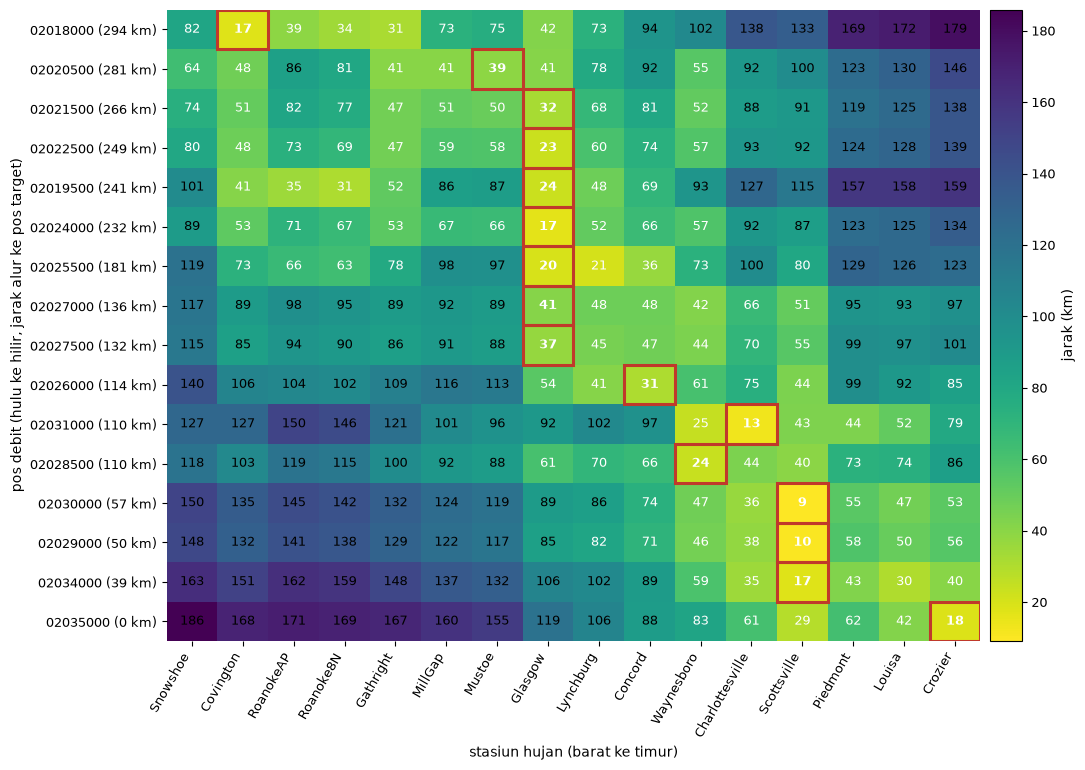

Gambar 7. Jarak horizontal (km) dari tiap pos debit ke tiap stasiun hujan. Kotak merah menandai stasiun terdekat. Stasiun Glasgow menjadi stasiun terdekat bagi 7 dari 16 pos, dan pos 02024000 hanya memiliki 1 stasiun dalam radius 50 km.


In [45]:
fig, ax = plt.subplots(figsize=(12.5, 8.2))
im = ax.imshow(D_ps.to_numpy(), cmap=CMAP + "_r", aspect="auto")
for i, p in enumerate(pos):
    for j, s in enumerate(ST):
        v = D_ps.iat[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=9,
                color="white" if v < D_ps.values.mean() else "black",
                weight="bold" if s == terdekat[p] else "normal")
    j = ST.index(terdekat[p])
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=WARNA["aksen"], lw=2.2))
ax.set_xticks(range(len(ST))); ax.set_xticklabels(st["label"], rotation=60, ha="right")
ax.set_yticks(range(len(pos))); ax.set_yticklabels([f"{p} ({sp.at[p, 'jarak_alur_ke_muara_km']:.0f} km)" for p in pos])
ax.set_xlabel("stasiun hujan (barat ke timur)"); ax.set_ylabel("pos debit (hulu ke hilir, jarak alur ke pos target)")
for s_ in ax.spines.values():
    s_.set_visible(False)
cb = fig.colorbar(im, ax=ax, pad=0.01); cb.set_label("jarak (km)")
n_glas = int((terdekat == "USC00443375").sum())
ket = (f"Gambar 7. Jarak horizontal (km) dari tiap pos debit ke tiap stasiun hujan. Kotak merah menandai "
       f"stasiun terdekat. Stasiun Glasgow menjadi stasiun terdekat bagi {n_glas} dari {len(pos)} pos, "
       f"dan pos 02024000 hanya memiliki {int(n_dalam['02024000'])} stasiun dalam radius {int(R_IDW)} km.")
plt.show()
print(ket)

### 17b. Dua metode pemetaan

Data hujan dipetakan ke setiap pos debit dengan dua metode:

- **Stasiun terdekat**, yaitu setiap pos memakai data dari stasiun hujan
  terdekat;
- **Inverse distance weighting (IDW)**, yaitu rata-rata berbobot 1/d² dari semua
  stasiun dalam radius 50 km.

Tensor tidak boleh berisi nilai kosong, sehingga kedua metode memerlukan aturan
cadangan. Pada metode stasiun terdekat, hari yang kosong diisi dari stasiun
terdekat berikutnya yang memiliki data. Pada IDW, bobot dihitung ulang hanya
dari stasiun yang memiliki data pada hari itu, dan jika tidak ada satu pun
stasiun dalam radius 50 km, dipakai stasiun terdekat yang memiliki data. Setiap
pemakaian aturan cadangan dicatat.

In [46]:
def petakan_terdekat(H, D):
    out, cad = {}, {}
    for p in D.index:
        urut = D.loc[p].sort_values().index
        x = H[urut[0]].copy()
        c = pd.Series(False, index=H.index)
        for s in urut[1:]:
            k = x.isna() & H[s].notna()
            x[k] = H.loc[k, s]; c |= k
        out[p], cad[p] = x, c
    return pd.DataFrame(out), pd.DataFrame(cad)

def petakan_idw(H, D, radius):
    terd, _ = petakan_terdekat(H, D)
    out, cad = {}, {}
    for p in D.index:
        sel = D.loc[p][D.loc[p] <= radius]
        w = 1.0 / sel ** 2
        X = H[sel.index]
        bobot = X.notna().mul(w, axis=1)
        x = (X.fillna(0).mul(w, axis=1).sum(axis=1) / bobot.sum(axis=1)).where(bobot.sum(axis=1) > 0)
        c = x.isna()
        out[p], cad[p] = x.fillna(terd[p]), c
    return pd.DataFrame(out), pd.DataFrame(cad)

P_terdekat, cad_terdekat = petakan_terdekat(H, D_ps)
P_idw, cad_idw = petakan_idw(H, D_ps, R_IDW)
for nama, P_, c in [("terdekat", P_terdekat, cad_terdekat), ("idw", P_idw, cad_idw)]:
    P_.index.name = "tanggal"
    print(f"{nama:9}: kosong {int(P_.isna().sum().sum())}, memakai cadangan {int(c.sum().sum()):,} sel "
          f"({c.to_numpy().mean()*100:.2f}%)")

terdekat : kosong 0, memakai cadangan 2,870 sel (1.96%)
idw      : kosong 0, memakai cadangan 166 sel (0.11%)


### 17c. Kemiripan antarkolom hasil pemetaan

Korelasi antarkolom dihitung pada data latih. Pasangan dengan korelasi di atas
0,99 dianggap duplikat, karena bagi CNN dua stasiun dengan input hujan yang
hampir sama tidak bisa dibedakan dari sisi hujan.

In [47]:
def ringkas_duplikat(P_, nama):
    K = P_.loc[LATIH].corr()
    iu = np.triu_indices(len(K), 1)
    r = K.to_numpy()[iu]
    pas = [(K.index[i], K.columns[j], K.iat[i, j]) for i, j in zip(*iu) if K.iat[i, j] > 0.99]
    identik = sum(P_[K.index[i]].equals(P_[K.columns[j]]) for i, j in zip(*iu))
    return K, {"metode": nama, "pasangan": len(r), "r_median": round(float(np.median(r)), 3),
               "r_maks": round(float(r.max()), 4), "pasangan_r>0.99": len(pas),
               "pasangan_identik_penuh": int(identik)}, pas

K_t, rk_t, pas_t = ringkas_duplikat(P_terdekat, "terdekat")
K_i, rk_i, pas_i = ringkas_duplikat(P_idw, "idw")
banding = pd.DataFrame([rk_t, rk_i])
print(banding.to_string(index=False))
for nama, pas in [("terdekat", pas_t), ("idw", pas_i)]:
    print(f"\npasangan r > 0,99 ({nama}):")
    for a, b, r in pas:
        print(f"  {a} - {b}  r = {r:.4f}  (stasiun terdekat: {NAMA_PENDEK[terdekat[a]]} / {NAMA_PENDEK[terdekat[b]]})")

  metode  pasangan  r_median  r_maks  pasangan_r>0.99  pasangan_identik_penuh
terdekat       120     0.646   1.000               24                       4
     idw       120     0.771   0.999                2                       0

pasangan r > 0,99 (terdekat):
  02021500 - 02022500  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02021500 - 02019500  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02021500 - 02024000  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02021500 - 02025500  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02021500 - 02027000  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02021500 - 02027500  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02022500 - 02019500  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02022500 - 02024000  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02022500 - 02025500  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  02022500 - 02027000  r = 1.0000  (stasiun terdekat: Glasgow / Glasgow)
  020

In [48]:
# bobot IDW per pos: seberapa besar porsi stasiun dengan bobot terbesar
dom = []
for p in pos:
    sel = D_ps.loc[p][D_ps.loc[p] <= R_IDW]
    w = (1 / sel ** 2); w = w / w.sum()
    dom.append({"pos": p, "n_stasiun": len(sel), "stasiun_dominan": NAMA_PENDEK[w.idxmax()],
                "bobot_dominan_%": round(w.max() * 100, 1)})
dom = pd.DataFrame(dom)
print(dom.to_string(index=False))

     pos  n_stasiun stasiun_dominan  bobot_dominan_%
02018000          5       Covington             51.4
02020500          5          Mustoe             22.7
02021500          3         Glasgow             53.0
02022500          3         Glasgow             67.8
02019500          5         Glasgow             38.6
02024000          1         Glasgow            100.0
02025500          3         Glasgow             44.3
02027000          4         Glasgow             28.8
02027500          4         Glasgow             33.3
02026000          3         Concord             49.2
02031000          4 Charlottesville             69.9
02028500          3      Waynesboro             60.3
02030000          4     Scottsville             87.9
02029000          3     Scottsville             89.6
02034000          5     Scottsville             51.8
02035000          3         Crozier             62.5


Metode **stasiun terdekat** menghasilkan 24 pasangan kolom dengan korelasi di
atas 0,99, yaitu 21 pasangan dari tujuh pos yang memakai Glasgow dan 3 pasangan
dari tiga pos yang memakai Scottsville. Glasgow menjadi stasiun terdekat bagi
tujuh pos. Pasangan ini tidak sepenuhnya identik karena hari kosong di Glasgow
diisi dari stasiun cadangan yang berbeda untuk setiap pos.

Metode **IDW** mengurangi jumlahnya menjadi 2 pasangan, yaitu Tye–Piney dan
Hardware–Scottsville. Namun IDW tidak sepenuhnya menyelesaikan masalah ini. Pos
02024000 hanya memiliki satu stasiun dalam radius 50 km, sehingga kolom IDW-nya
sama persis dengan Glasgow, dan pada pos 02030000 dan 02029000, Scottsville
memegang 88 sampai 90 persen bobot. Penyebab utamanya adalah jumlah stasiun yang
sedikit, bukan metode pemetaannya. Di bagian tengah DAS hanya ada satu stasiun,
sehingga metode interpolasi apa pun tidak bisa menghasilkan variasi spasial yang
tidak terukur.

### Gambar 8 — Perbandingan metode pemetaan

Gambar ini menampilkan hari dengan rata-rata hujan terbesar di data latih
(rata-rata 16 kolom IDW), mulai 2 hari sebelum sampai 3 hari sesudahnya.

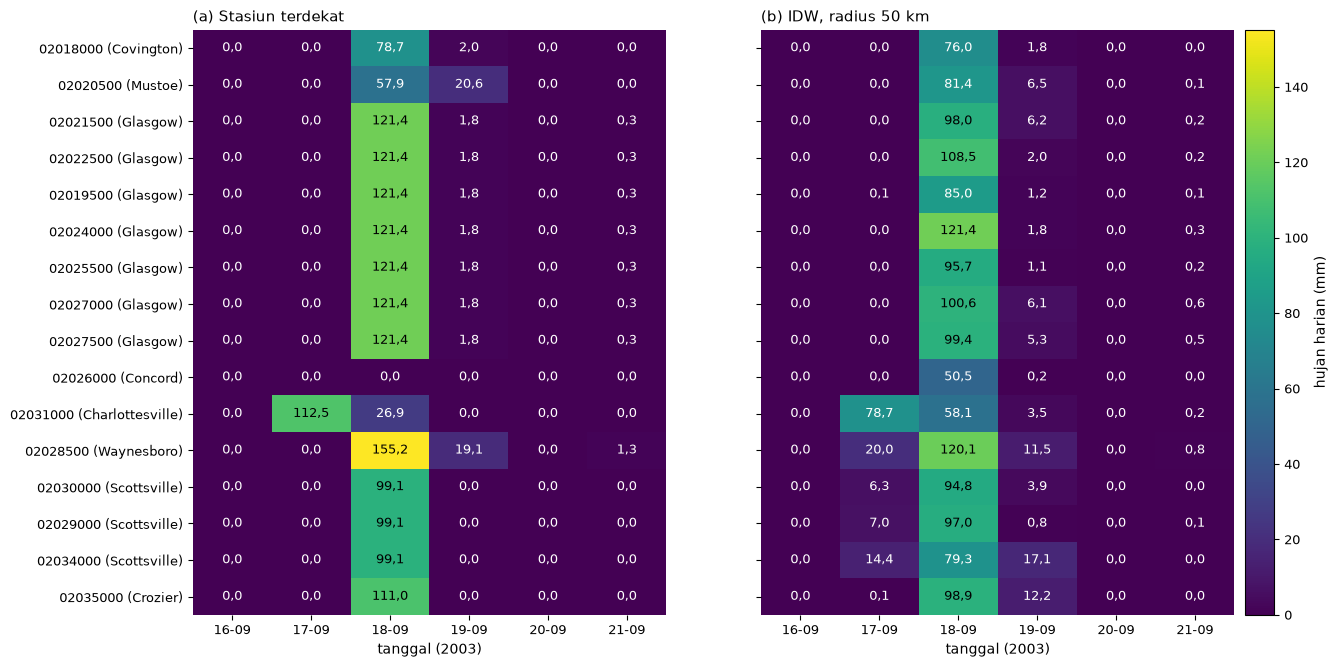

Gambar 8. Hujan harian (mm) di 16 pos debit hasil dua metode pemetaan, sekitar hari dengan hujan rata-rata terbesar di data latih (18-09-2003). Nama dalam kurung adalah stasiun terdekat. (a) Metode stasiun terdekat menghasilkan baris yang identik untuk pos-pos yang berbagi stasiun. (b) IDW dengan bobot 1/d² dari stasiun dalam radius 50 km. Tanggal mengikuti kalender tengah malam ke tengah malam, setelah stasiun COOP yang dibaca pagi hari dimajukan sehari.


In [49]:
rerata = P_idw.loc[LATIH].mean(axis=1)
puncak_hujan = rerata.idxmax()
rng_hari = pd.date_range(puncak_hujan - pd.Timedelta(days=2), puncak_hujan + pd.Timedelta(days=3))
vmax_h = max(P_terdekat.loc[rng_hari].max().max(), P_idw.loc[rng_hari].max().max())

fig, axs = plt.subplots(1, 2, figsize=(14, 7.6), sharey=True)
for ax, P_, jd in [(axs[0], P_terdekat, "(a) Stasiun terdekat"), (axs[1], P_idw, f"(b) IDW, radius {int(R_IDW)} km")]:
    M = P_.loc[rng_hari].T
    im = ax.imshow(M.to_numpy(), cmap=CMAP, vmin=0, vmax=vmax_h, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iat[i, j]
            ax.text(j, i, koma(v, d=1), ha="center", va="center", fontsize=9,
                    color="white" if v < vmax_h * 0.55 else "black")
    ax.set_xticks(range(len(rng_hari))); ax.set_xticklabels([t.strftime("%d-%m") for t in rng_hari])
    ax.set_title(jd, loc="left")
    ax.set_xlabel(f"tanggal ({puncak_hujan.year})")
    for s_ in ax.spines.values():
        s_.set_visible(False)
axs[0].set_yticks(range(len(pos)))
axs[0].set_yticklabels([f"{p} ({NAMA_PENDEK[terdekat[p]]})" for p in pos])
cb = fig.colorbar(im, ax=axs, pad=0.01, fraction=0.03); cb.set_label("hujan harian (mm)")
ket = (f"Gambar 8. Hujan harian (mm) di 16 pos debit hasil dua metode pemetaan, sekitar hari dengan hujan "
       f"rata-rata terbesar di data latih ({puncak_hujan.strftime('%d-%m-%Y')}). Nama dalam kurung adalah "
       f"stasiun terdekat. (a) Metode stasiun terdekat menghasilkan baris yang identik untuk pos-pos yang "
       f"berbagi stasiun. (b) IDW dengan bobot 1/d² dari stasiun dalam radius {int(R_IDW)} km. Tanggal mengikuti "
       f"kalender tengah malam ke tengah malam, setelah stasiun COOP yang dibaca pagi hari dimajukan sehari.")
plt.show()
print(ket)

### Gambar 9 — Hietograf dan hidrograf pos target

Gambar ini menampilkan kejadian banjir terbesar di data latih. Hujan
ditampilkan sebagai rata-rata 16 kolom IDW, sebagai pendekatan hujan rata-rata
DAS, dengan sumbu terbalik di bagian atas sesuai kebiasaan dalam hidrologi.
Debit diambil dari `Q_semua` (tahap 5); pos target tidak memiliki gap sehingga
tidak perlu menunggu penambalan di tahap 20.

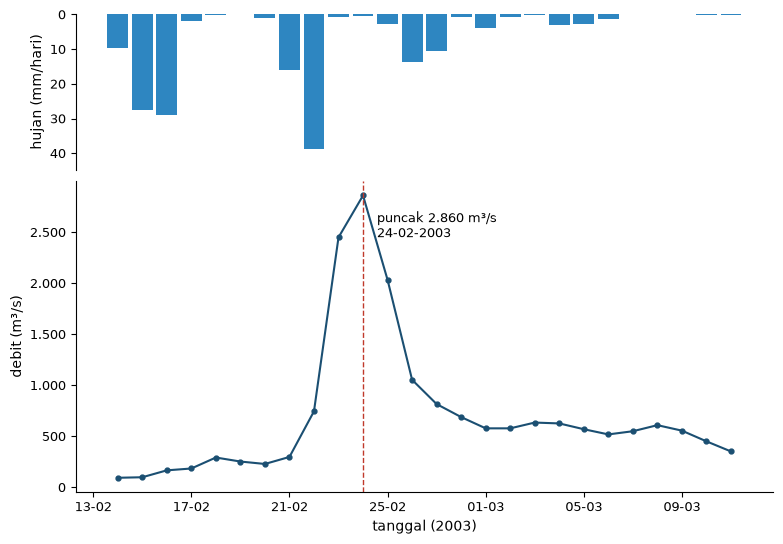

Gambar 9. Hietograf hujan rata-rata 16 kolom IDW (atas, sumbu dibalik) dan hidrograf debit pos target 02035000 (bawah) pada kejadian banjir terbesar di data latih, puncak 2.860 m³/s pada 24-02-2003. Hujan dan debit memakai kalender yang sama, tengah malam ke tengah malam.

hujan rata-rata DAS di sekitar puncak (mm):
tanggal
2003-02-16    29.1
2003-02-17     1.9
2003-02-18     0.0
2003-02-19     0.0
2003-02-20     1.0
2003-02-21    16.1
2003-02-22    38.9
2003-02-23     0.8
2003-02-24     0.3
2003-02-25     2.6
Freq: D


In [50]:
q = Q_semua[TARGET]
t_banjir = q.loc[LATIH].idxmax()
rb = pd.date_range(t_banjir - pd.Timedelta(days=10), t_banjir + pd.Timedelta(days=15))
hujan_das = P_idw.loc[rb].mean(axis=1)

fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6.2), sharex=True, gridspec_kw={"height_ratios": [1, 2], "hspace": 0.05})
a1.bar(rb, hujan_das, width=0.85, color=WARNA["hujan"])
a1.set_ylim(hujan_das.max() * 1.15, 0)
a1.set_ylabel("hujan (mm/hari)")
a1.spines["bottom"].set_visible(False); a1.tick_params(axis="x", length=0)
a2.plot(rb, q.loc[rb], "o-", color=WARNA["utama"], ms=3.5, lw=1.5)
a2.axvline(t_banjir, color=WARNA["aksen"], ls="--", lw=1)
a2.annotate(f"puncak {ribu(q[t_banjir])} m³/s\n{t_banjir.strftime('%d-%m-%Y')}",
            xy=(t_banjir, q[t_banjir]), xytext=(10, -30), textcoords="offset points", fontsize=9)
a2.set_ylabel("debit (m³/s)")
a2.yaxis.set_major_formatter(FuncFormatter(lambda y_, _: ribu(y_)))
a2.xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
a2.set_xlabel(f"tanggal ({t_banjir.year})")
ket = (f"Gambar 9. Hietograf hujan rata-rata 16 kolom IDW (atas, sumbu dibalik) dan hidrograf debit pos target "
       f"{TARGET} (bawah) pada kejadian banjir terbesar di data latih, puncak {ribu(q[t_banjir])} m³/s pada "
       f"{t_banjir.strftime('%d-%m-%Y')}. Hujan dan debit memakai kalender yang sama, tengah malam ke tengah malam.")
plt.show()
print(ket)
print("\nhujan rata-rata DAS di sekitar puncak (mm):")
print(hujan_das.loc[t_banjir - pd.Timedelta(days=8): t_banjir + pd.Timedelta(days=1)].round(1).to_string())

In [51]:
# salju di sekitar kejadian: SNWD = tebal salju di tanah (mm), SNOW = salju baru (mm), tanggal .dly
salju = {}
for s_ in ["USC00443375", "USW00013741", "USW00013733"]:
    for b in (RAW / "hujan" / "dly" / f"{s_}.dly").read_text().splitlines():
        if b[11:17] == t_banjir.strftime("%Y%m") and b[17:21] in ("SNWD", "SNOW"):
            v = [int(b[21 + 8 * i: 26 + 8 * i]) for i in range(31)]
            for d_ in range(max(1, t_banjir.day - 10), t_banjir.day + 1):
                salju.setdefault(f"{NAMA_PENDEK[s_]}_{b[17:21]}", {})[d_] = v[d_ - 1]
print(pd.DataFrame(salju).T.to_string())

                14  15  16   17   18   19   20   21  22  23  24
Glasgow_SNOW     0   0  23  114    8    0    0    0   0   0   0
Glasgow_SNWD     0   0  25  127  127  127  127  102  51   0   0
RoanokeAP_SNOW   0   0   3   38    0    0    0    0   0   0   0
RoanokeAP_SNWD   0   0   0   51   51   51   25    0   0   0   0
Lynchburg_SNOW   0  25  66    8    0    0    0    0   0   0   0
Lynchburg_SNWD   0   0   0    0    0    0    0    0   0   0   0


Banjir terbesar di data latih ternyata bukan banjir akibat hujan biasa. Hujan
rata-rata DAS dua hari sebelum puncak hanya sekitar 55 mm, tetapi sepekan
sebelumnya terjadi hujan salju lebat (tabel salju memakai tanggal file `.dly`).
Glasgow mencatat salju setebal 127 mm di permukaan tanah, yang mencair tepat
sebelum puncak banjir. Kejadian ini merupakan hujan di atas salju (*rain on
snow*), dan sebagian besar airnya berasal dari salju yang mencair.

Hal ini berpengaruh pada eksperimen hujan. Elemen `PRCP` mencatat salju sebagai
setara air pada hari salju turun, bukan pada hari salju mencair. Model yang
diberi input hujan akan melihat "hujan" sepekan sebelum banjir, tetapi tidak
melihat apa pun saat salju mencair. Kejadian ini dicatat sebagai keterbatasan
data, dan elemen `SNWD` bisa dipertimbangkan sebagai input tambahan jika
eksperimen hujan dijalankan.

---
# Bagian IV — Hubungan antarstasiun

---
## 18. Matriks korelasi

Matriks korelasi Pearson antarstasiun dibuat mengikuti Fig. 2 pada Le dkk.
(2025), dengan nilai korelasi ditulis di setiap sel. Pos debit diberi akhiran
`_Q`, sedangkan stasiun hujan diberi akhiran `_R`.

Matriks dibuat dalam dua versi:

- **Gambar 1a, nilai harian (level)**, setara dengan Le dkk. sehingga bisa
  dibandingkan langsung;
- **Gambar 1b, selisih harian**, yang menghilangkan komponen musiman sehingga
  yang tersisa adalah perubahan dari hari ke hari.

Keduanya dihitung hanya dari data latih, karena matriks korelasi dipakai
sebagai dasar pemilihan input. Jika dihitung dari seluruh data, periode uji ikut
memengaruhi rancangan model.

Debit di tahap ini belum ditambal (tahap 20), sehingga korelasi dihitung
berpasangan dan dua nilai kosong diabaikan. Data hujan yang dipakai adalah
hasil tahap 16, yaitu sudah dikoreksi jam pengamatannya, nilai Concord sudah
dijadikan NaN, dan gap pendek sudah diisi nol. Pos debit diurutkan dari hulu ke
hilir berdasarkan jarak alur, sedangkan stasiun hujan dari barat ke timur.
Kedua matriks memakai skala warna yang sama.

In [52]:
lab_q = [f"{p}_Q" for p in pos]
lab_r = [f"{NAMA_PENDEK[s]}_R" for s in ST]
gab = pd.concat([Q_semua[pos].set_axis(lab_q, axis=1), H[ST].set_axis(lab_r, axis=1)], axis=1)
gab_latih = gab.loc[LATIH]

K_level = gab_latih.corr()
K_diff = gab_latih.diff().corr()

nq = len(lab_q)
def blok(K):
    a = K.to_numpy(); m = ~np.eye(len(a), dtype=bool)
    return {"Q-Q": a[:nq, :nq][m[:nq, :nq]], "R-R": a[nq:, nq:][m[nq:, nq:]],
            "Q-R": a[:nq, nq:].ravel()}
ring = []
for nama, K in [("level", K_level), ("selisih", K_diff)]:
    for b, x in blok(K).items():
        ring.append({"panel": nama, "blok": b, "min": x.min(), "median": np.median(x),
                     "maks": x.max(), "rentang": x.max() - x.min()})
ringkas_korelasi = pd.DataFrame(ring).round(3)
print(ringkas_korelasi.to_string(index=False))

# pembanding: blok Q-R jika hujan dipakai tanpa koreksi jam pengamatan
gab_mentah = pd.concat([Q_semua[pos].set_axis(lab_q, axis=1), mm[ST].set_axis(lab_r, axis=1)], axis=1).loc[LATIH]
med_qr = lambda K: np.median(K.iloc[:nq, nq:].to_numpy())
print(f"\nmedian blok Q-R dengan hujan tanpa koreksi: level {med_qr(gab_mentah.corr()):.3f}, "
      f"selisih {med_qr(gab_mentah.diff().corr()):.3f}")

  panel blok    min  median  maks  rentang
  level  Q-Q  0.428   0.727 0.980    0.553
  level  R-R  0.234   0.549 0.850    0.616
  level  Q-R -0.026   0.062 0.375    0.401
selisih  Q-Q -0.217   0.537 0.963    1.179
selisih  R-R -0.018   0.466 0.828    0.847
selisih  Q-R -0.331  -0.177 0.343    0.674

median blok Q-R dengan hujan tanpa koreksi: level 0.272, selisih 0.214


### Gambar 1a dan 1b

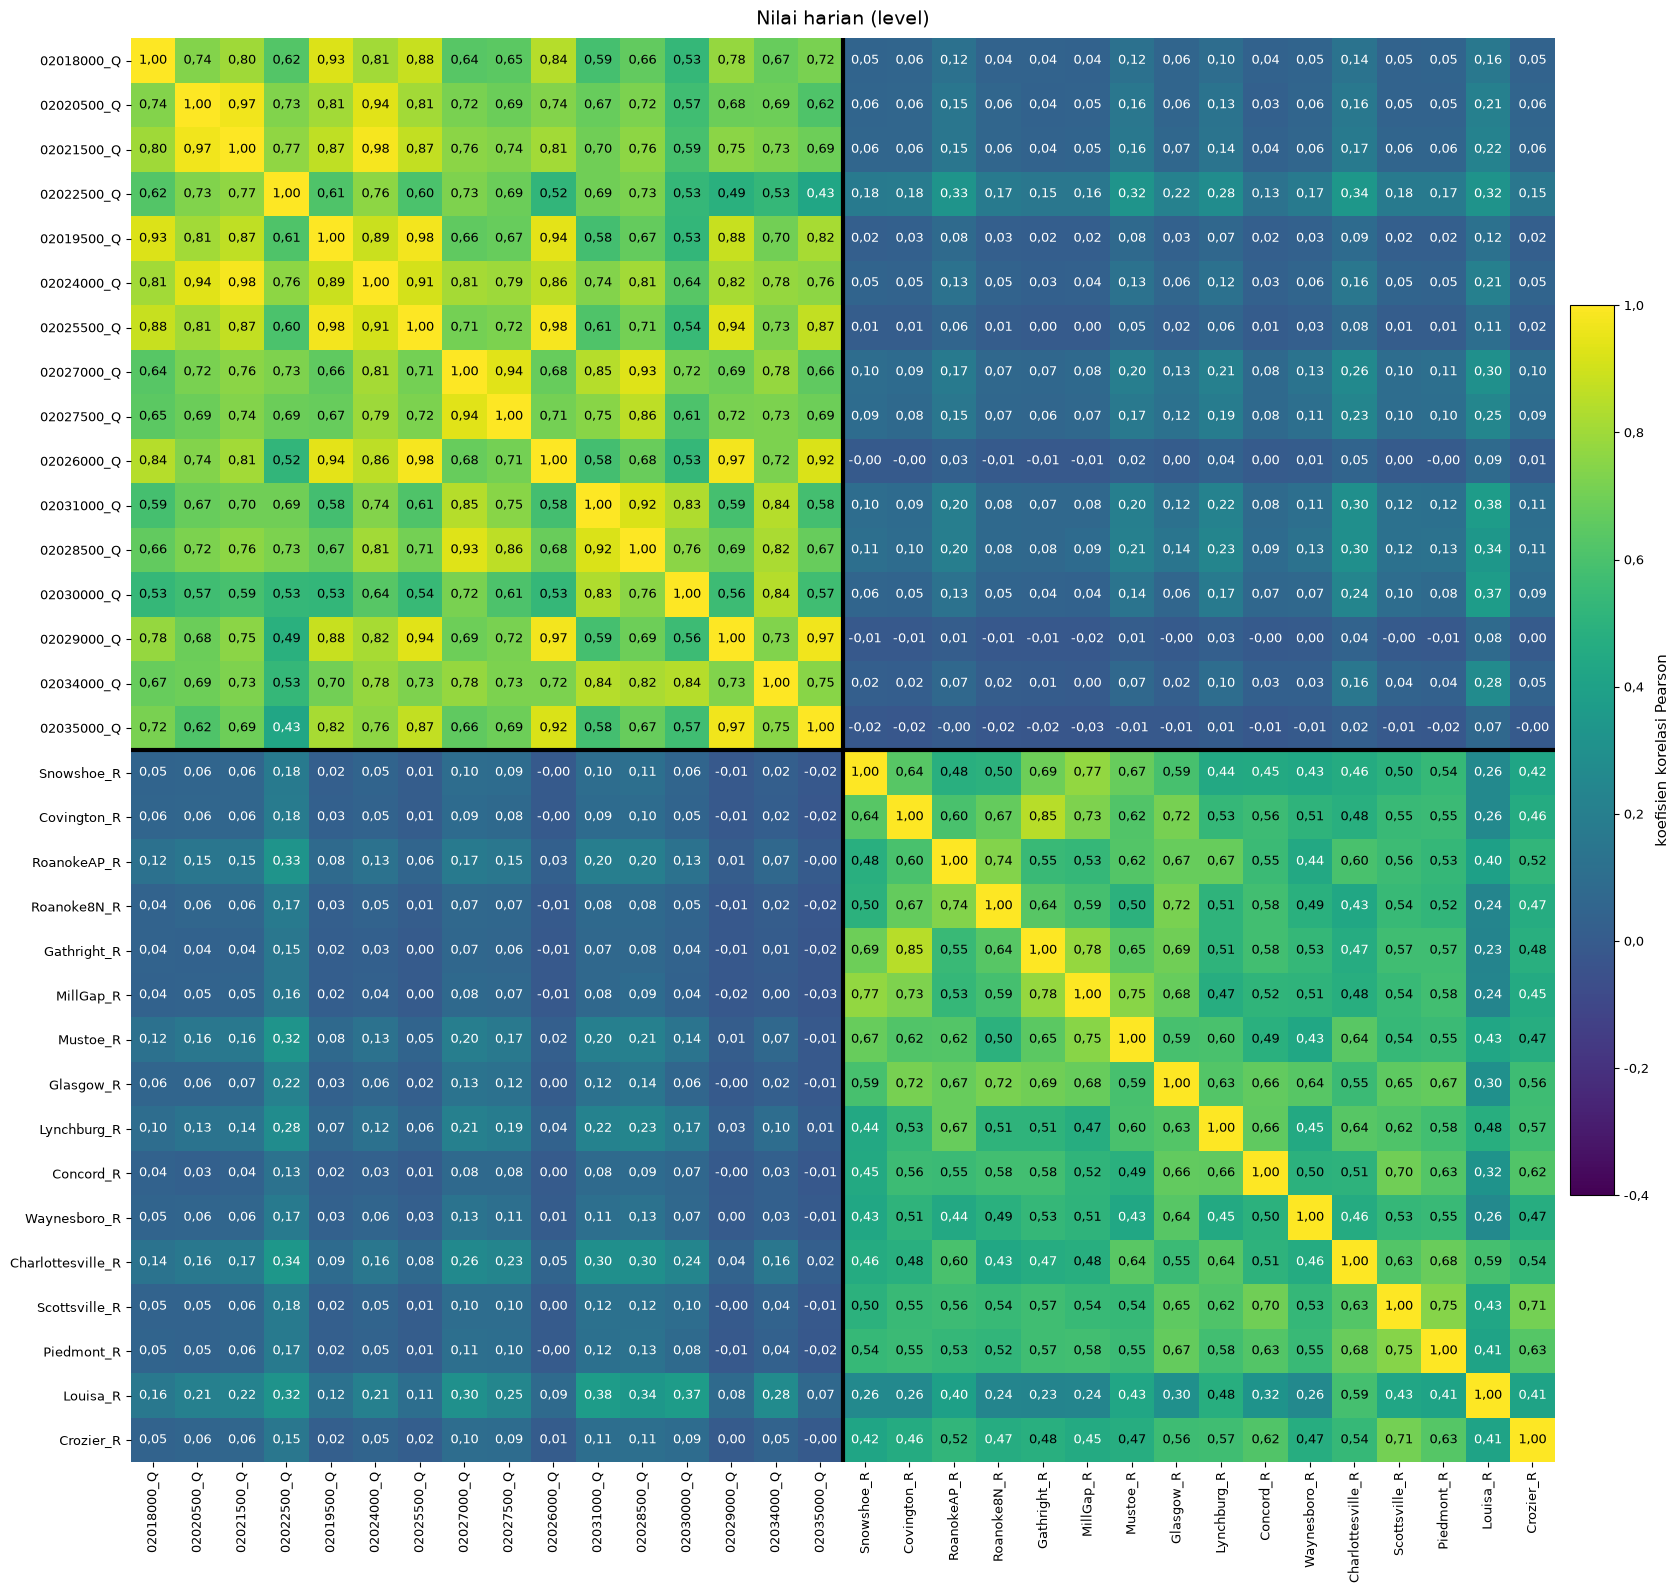

Gambar 1a. Matriks korelasi Pearson nilai harian (level) antara 16 pos debit (_Q, diurutkan dari hulu ke hilir menurut jarak alur) dan 16 stasiun hujan (_R, diurutkan dari barat ke timur), data latih (2000–2017). Antarpos debit berkisar 0,43–0,98 (median 0,73). Hujan sudah diselaraskan jam pengamatannya. Garis tebal memisahkan blok debit dan blok hujan.


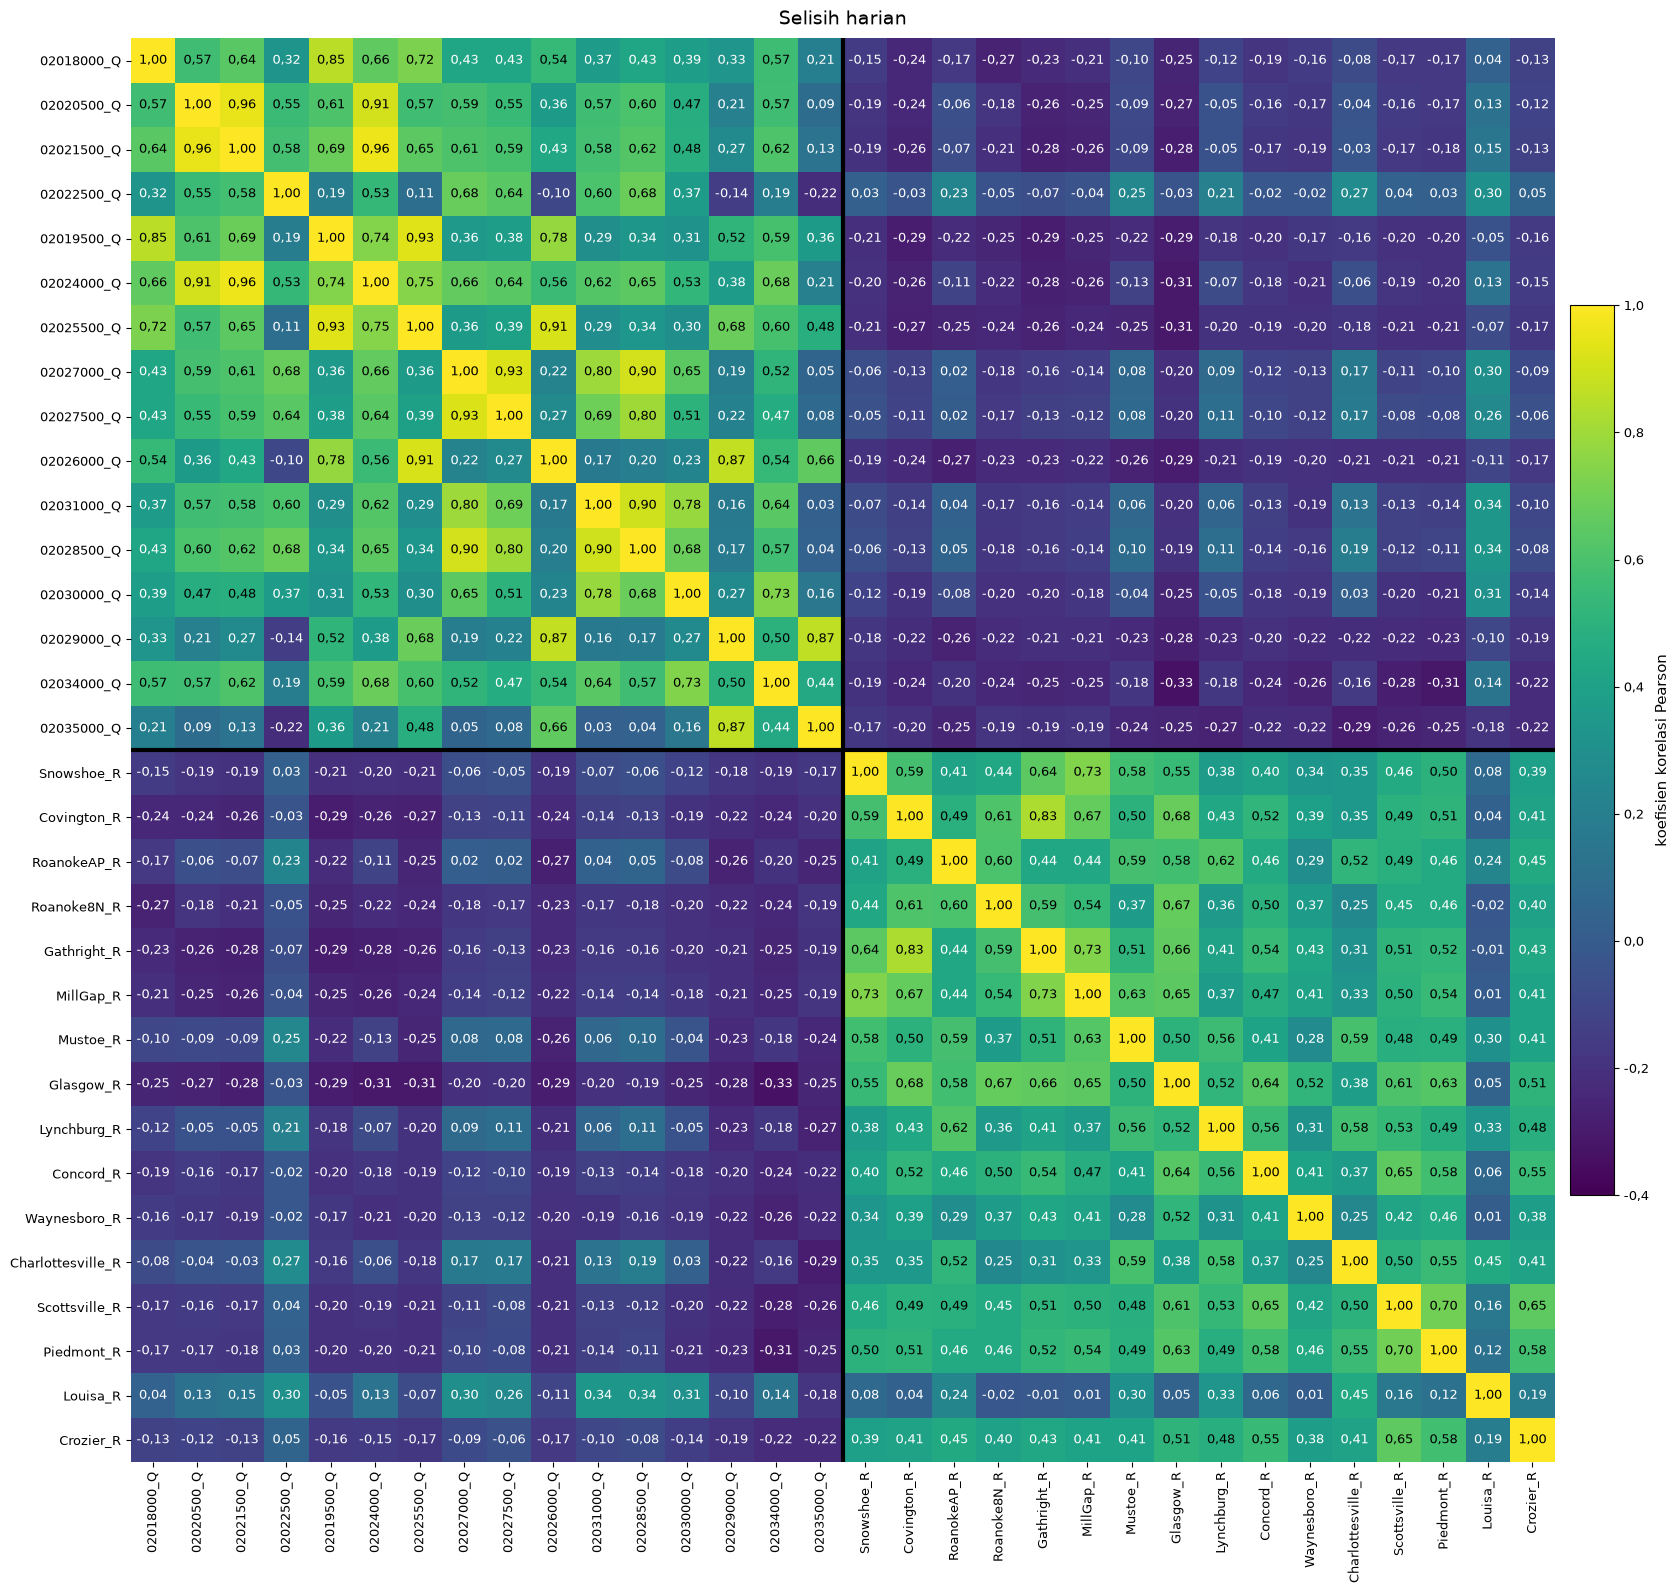

Gambar 1b. Matriks korelasi Pearson selisih harian, susunan sama dengan Gambar 1a. Antarpos debit berkisar -0,22–0,96 (median 0,54). Skala warna sama dengan Gambar 1a.


In [53]:
def gambar_matriks(ax, K, judul, vmin, vmax, ukuran_angka=9):
    n_ = len(K)
    im = ax.imshow(K.to_numpy(), cmap=CMAP, vmin=vmin, vmax=vmax)
    cm_ = plt.get_cmap(CMAP); nrm_ = mpl.colors.Normalize(vmin, vmax)
    for i in range(n_):
        for j in range(n_):
            v = K.iat[i, j]
            if np.isnan(v):
                continue
            r, g, b, _ = cm_(nrm_(v))
            terang = 0.299 * r + 0.587 * g + 0.114 * b
            ax.text(j, i, koma(v), ha="center", va="center", fontsize=ukuran_angka,
                    color="black" if terang > 0.5 else "white")
    ax.set_xticks(range(n_)); ax.set_xticklabels(K.columns, rotation=90)
    ax.set_yticks(range(n_)); ax.set_yticklabels(K.index)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.axhline(nq - 0.5, color="black", lw=3); ax.axvline(nq - 0.5, color="black", lw=3)
    ax.set_title(judul, fontsize=14, pad=10)
    return im

def rentang_blok(panel, b, kol):
    return ringkas_korelasi.query("panel == @panel and blok == @b")[kol].iat[0]

vmin = math.floor(min(K_level.min().min(), K_diff.min().min()) * 10) / 10
vmax = 1.0
SEL = 0.52   # inci per sel, cukup untuk "-0,22" pada 9 pt tanpa bertumpuk
n_sel = len(K_level)
ket_1 = {
    "gambar_1a": (
        f"Gambar 1a. Matriks korelasi Pearson nilai harian (level) antara {len(pos)} pos debit (_Q, diurutkan "
        f"dari hulu ke hilir menurut jarak alur) dan {len(ST)} stasiun hujan (_R, diurutkan dari barat ke timur), "
        f"data latih ({LATIH[0].year}–{LATIH[-1].year}). Antarpos debit berkisar "
        f"{koma(rentang_blok('level','Q-Q','min'))}–{koma(rentang_blok('level','Q-Q','maks'))} (median "
        f"{koma(rentang_blok('level','Q-Q','median'))}). Hujan sudah diselaraskan jam pengamatannya. Garis tebal "
        f"memisahkan blok debit dan blok hujan."),
    "gambar_1b": (
        f"Gambar 1b. Matriks korelasi Pearson selisih harian, susunan sama dengan Gambar 1a. Antarpos debit "
        f"berkisar {koma(rentang_blok('selisih','Q-Q','min'))}–{koma(rentang_blok('selisih','Q-Q','maks'))} "
        f"(median {koma(rentang_blok('selisih','Q-Q','median'))}). Skala warna sama dengan Gambar 1a."),
}
for nama, K, jd in [("gambar_1a", K_level, "Nilai harian (level)"),
                    ("gambar_1b", K_diff, "Selisih harian")]:
    f1, a1 = plt.subplots(figsize=(n_sel * SEL + 2.5, n_sel * SEL + 2))
    im1 = gambar_matriks(a1, K, jd, vmin, vmax)
    c1 = f1.colorbar(im1, ax=a1, fraction=0.03, pad=0.01)
    c1.set_label("koefisien korelasi Pearson", fontsize=11)
    c1.ax.yaxis.set_major_formatter(FuncFormatter(lambda x, _: koma(x, d=1)))
    plt.show()
    print(ket_1[nama])

In [54]:
def pasangan(K, blok_a, blok_b, n=5, terbesar=True):
    M = K.loc[blok_a, blok_b].stack()
    M = M[[a < b for a, b in M.index]]        # matriks simetris: ambil setiap pasangan sekali
    return (M.nlargest(n) if terbesar else M.nsmallest(n)).round(2)

print("korelasi tiap pos debit terhadap pos target:")
print(pd.DataFrame({"level": K_level[f"{TARGET}_Q"][lab_q], "selisih": K_diff[f"{TARGET}_Q"][lab_q]}).round(2).T.to_string())
print("\npasangan debit tertinggi pada panel selisih:")
print(pasangan(K_diff, lab_q, lab_q).to_string())
print("\nkorelasi stasiun bandara dan stasiun COOP terdekatnya, setelah koreksi jam pengamatan (level):")
for a, b in [("RoanokeAP_R", "Roanoke8N_R"), ("Lynchburg_R", "Concord_R"), ("Charlottesville_R", "Scottsville_R"),
             ("Covington_R", "Gathright_R"), ("Lynchburg_R", "Charlottesville_R")]:
    print(f"  {a:18} - {b:16} r = {K_level.at[a, b]:.2f}")

korelasi tiap pos debit terhadap pos target:
         02018000_Q  02020500_Q  02021500_Q  02022500_Q  02019500_Q  02024000_Q  02025500_Q  02027000_Q  02027500_Q  02026000_Q  02031000_Q  02028500_Q  02030000_Q  02029000_Q  02034000_Q  02035000_Q
level          0.72        0.62        0.69        0.43        0.82        0.76        0.87        0.66        0.69        0.92        0.58        0.67        0.57        0.97        0.75         1.0
selisih        0.21        0.09        0.13       -0.22        0.36        0.21        0.48        0.05        0.08        0.66        0.03        0.04        0.16        0.87        0.44         1.0

pasangan debit tertinggi pada panel selisih:
02021500_Q  02024000_Q    0.96
02020500_Q  02021500_Q    0.96
02019500_Q  02025500_Q    0.93
02027000_Q  02027500_Q    0.93
02025500_Q  02026000_Q    0.91

korelasi stasiun bandara dan stasiun COOP terdekatnya, setelah koreksi jam pengamatan (level):
  RoanokeAP_R        - Roanoke8N_R      r = 0.74
  Lynchbu

### Hasil

**Korelasi pada nilai harian tidak seragam.** Semula diduga semua pos debit akan
berkorelasi sangat tinggi karena sama-sama mengikuti pola musiman. Ternyata
korelasi antarpos debit pada nilai harian berkisar 0,43 sampai 0,98 dengan
median 0,73. Anak sungai kecil seperti Kerrs Creek (91 km²) hanya berkorelasi
0,43 dengan pos target. Pola musiman memang menaikkan korelasi, tetapi tidak
membuatnya seragam.

**Korelasi pada selisih harian lebih rendah dan lebih bervariasi.** Median turun
dari 0,73 menjadi 0,54 dan rentangnya melebar menjadi −0,22 sampai 0,96.
Korelasi yang tetap tinggi terdapat pada pasangan pos yang terhubung langsung
atau berdekatan, sehingga terkena badai yang sama pada hari yang sama:
Calfpasture–Maury di Rockbridge Baths (0,96), Maury di Rockbridge Baths–Maury
dekat Buena Vista (0,96), James di Buchanan–James di Holcomb Rock (0,93), dan
Tye–Piney (0,93). Korelasi pos hulu yang jauh terhadap pos target turun tajam
(02018000: dari 0,72 menjadi 0,21), karena perubahan di hulu baru sampai di pos
target sehari kemudian, sedangkan matriks ini hanya melihat lag nol. Dengan kata
lain, matriks dengan lag nol meremehkan informasi dari pos hulu, dan Gambar 2 di
tahap 23 menunjukkan bahwa informasi tersebut muncul pada lag 1 hari.

**Korelasi antarstasiun hujan.** Setelah koreksi jam pengamatan, stasiun bandara
tidak lagi membentuk kelompok sendiri. RoanokeAP dan Roanoke8N, yang hanya
berjarak 5 km, berkorelasi 0,74, padahal sebelum koreksi hanya 0,39 (tahap 15c).
Korelasi antarstasiun hujan pada nilai harian berkisar 0,23 sampai 0,85 (median
0,55).

**Korelasi hujan dan debit pada hari yang sama hampir nol**, dengan median 0,06
pada nilai harian dan −0,18 pada selisih harian. Hal ini terjadi karena hujan
pada hari t sekarang tercatat pada hari hujan turun, sedangkan debit di pos-pos
ini baru naik sehari kemudian (tahap 15d). Pada selisih harian, hari hujan
biasanya diikuti hari kering (selisih hujan negatif) tepat ketika debit naik,
sehingga korelasinya menjadi negatif. Dengan hujan tanpa koreksi, median
korelasi ini lebih tinggi (nilainya tercetak di bawah tabel ringkasan), karena
sebagian besar stasiun COOP mencatat hujan sehari terlambat dan kebetulan
bertepatan dengan kenaikan debit. Karena itu matriks dengan lag nol tidak
dipakai untuk menilai manfaat hujan sebagai input. Penilaian tersebut dilakukan
dengan uji lag di tahap 15d dan 15e.

---
## 19. Kurva durasi aliran

Peluang terlampaui dihitung dengan posisi plot Weibull, i/(n+1). Kurva ini
hanya menggambarkan karakteristik aliran setiap pos dan tidak dipakai untuk
menentukan rancangan model, sehingga dihitung dari seluruh periode. Dua nilai
kosong yang belum ditambal diabaikan.

### Gambar 4 — Kurva durasi aliran

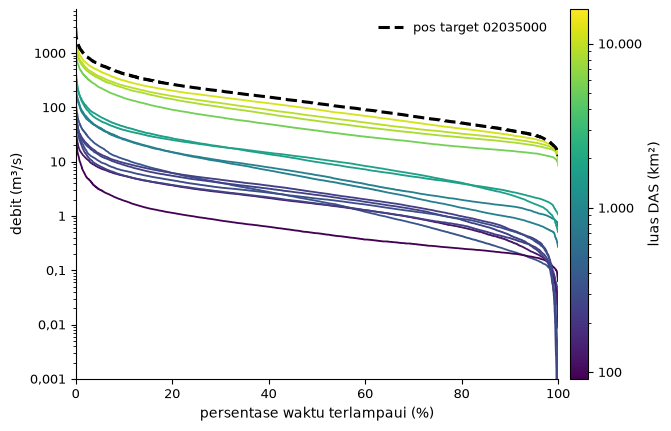

Gambar 4. Kurva durasi aliran 16 pos debit, 2000–2024, sumbu tegak logaritmik. Warna menyatakan luas DAS (91–16.193 km²); garis putus-putus hitam adalah pos target 02035000. Pada pos target, debit yang terlampaui 5 persen waktu 20 kali lebih besar daripada debit yang terlampaui 95 persen waktu.

rasio Q5/Q95 (debit terlampaui 5% dibanding 95% waktu):
02019500     16.0
02026000     16.0
02022500     17.0
02025500     17.0
02029000     18.0
02035000     20.0
02030000     28.0
02031000     30.0
02024000     31.0
02018000     34.0
02034000     34.0
02027500     36.0
02027000     37.0
02028500     51.0
02021500     58.0
02020500    118.0

rentang seluruh pos: 0.000 sampai 2860 m3/s, 7.0 orde besaran


In [55]:
luas = sp.loc[pos, "luas_nwis_km2"]
nrm_l = mpl.colors.LogNorm(luas.min(), luas.max())
cm = plt.get_cmap(CMAP)

fig, ax = plt.subplots(figsize=(7.5, 4.8))
for p in pos:
    q_ = np.sort(Q_semua[p].dropna().to_numpy())[::-1]
    pe_ = np.arange(1, len(q_) + 1) / (len(q_) + 1) * 100
    if p == TARGET:
        ax.plot(pe_, q_, color="black", lw=2.2, ls="--", zorder=4, label=f"pos target {TARGET}")
    else:
        ax.plot(pe_, q_, color=cm(nrm_l(luas[p])), lw=1.3)
ax.set_yscale("log")
ax.set_ylim(1e-3, None)       # debit nol pada anak sungai kecil tidak dapat digambar di sumbu log
ax.set_xlim(0, 100)
ax.set_xlabel("persentase waktu terlampaui (%)")
ax.set_ylabel("debit (m³/s)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda y_, _: f"{y_:g}".replace(".", ",")))
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=nrm_l, cmap=cm), ax=ax, pad=0.02)
cb.set_label("luas DAS (km²)")
cb.ax.yaxis.set_major_formatter(FuncFormatter(lambda y_, _: f"{y_:,.0f}".replace(",", ".")))
ax.legend(frameon=False, loc="upper right")
q5, q95 = Q_semua[pos].quantile(0.95), Q_semua[pos].quantile(0.05)
rasio = q5 / q95
ket = (
    f"Gambar 4. Kurva durasi aliran {len(pos)} pos debit, 2000–2024, sumbu tegak logaritmik. Warna "
    f"menyatakan luas DAS ({ribu(luas.min())}–{ribu(luas.max())} km²); garis putus-putus hitam adalah pos "
    f"target {TARGET}. Pada pos target, debit yang terlampaui 5 persen waktu "
    f"{ribu(rasio[TARGET])} kali lebih besar daripada debit yang terlampaui 95 persen waktu."
)
plt.show()
print(ket)

print("\nrasio Q5/Q95 (debit terlampaui 5% dibanding 95% waktu):")
print(rasio.round(0).sort_values().to_string())
print(f"\nrentang seluruh pos: {Q_semua[pos].min().min():.3f} sampai {Q_semua[pos].max().max():.0f} m3/s, "
      f"{np.log10(Q_semua[pos].max().max() / Q_semua[pos][Q_semua[pos] > 0].min().min()):.1f} orde besaran")

### Rentang debit

Rasio debit yang terlampaui 5 persen waktu terhadap debit yang terlampaui 95
persen waktu berkisar 16 sampai 118 kali per pos, atau satu sampai dua orde
besaran, dan pada pos target sebesar 20 kali. Rentang lebih dari dua orde
besaran baru terlihat jika yang dibandingkan adalah nilai minimum dan maksimum
(pos target 12,7 sampai 2.860 m³/s, atau 226 kali) atau antarpos (dari anak
sungai kecil yang hampir kering sampai sungai utama). Kurva yang turun tajam di
ujung kanan berasal dari anak sungai yang pernah mencatat debit nol atau hampir
nol, dan sumbunya dipotong pada 0,001 m³/s.

---
# Bagian V — Preprocessing

---
## 20. Penambalan gap

Aturan penambalan debit:

| Panjang gap | Penanganan | Alasan |
|---|---|---|
| 1–2 hari | Interpolasi linear | Debit berubah perlahan, sehingga masuk akal secara fisik |
| 3–7 hari | Interpolasi dan diberi flag | Dipakai untuk training, dikeluarkan dari data uji |
| lebih dari 7 hari | Tidak ditambal | Nilai hasil tambalan terlalu jauh dari data asli |

Pada 16 pos yang terpilih hanya ada dua gap, masing-masing satu hari, sehingga
tidak ada nilai yang perlu diberi flag. Penambalan data hujan memakai aturan
yang berbeda dan sudah dilakukan di tahap 16d.

In [56]:
Qs = Q_semua[pos].copy()
Es = E_semua[pos].copy()
ditambal = pd.DataFrame(False, index=Qs.index, columns=Qs.columns)

for k in Qs.columns:
    gap = panjang_gap(Qs[k])
    bisa = (gap > 0) & (gap <= GAP_FLAG)
    ditambal[k] = (gap > GAP_INTERP) & (gap <= GAP_FLAG)
    if bisa.any():
        Qs.loc[bisa, k] = Qs[k].interpolate("linear", limit_area="inside")[bisa]

sah = Qs.notna().all(axis=1).to_numpy()
n_interp = int(((Qs.notna()) & (Q_semua[pos].isna())).sum().sum())
print(f"nilai yang ditambal            : {n_interp}")
print(f"nilai tambalan yang diberi flag: {int(ditambal.sum().sum())}")
print(f"baris lengkap di semua stasiun : {sah.sum():,} dari {len(sah):,} "
      f"({sah.mean()*100:.1f}%)")
print(f"\n-> hanya {n_interp} nilai hasil interpolasi dari {Qs.size:,} sel ({n_interp/Qs.size*100:.4f} persen)")

nilai yang ditambal            : 2
nilai tambalan yang diberi flag: 0
baris lengkap di semua stasiun : 9,132 dari 9,132 (100.0%)

-> hanya 2 nilai hasil interpolasi dari 146,112 sel (0.0014 persen)


In [57]:
# gabung dua jenis nilai yang tidak boleh masuk data uji
tak_murni = (Es | ditambal).to_numpy()
print(f"nilai perkiraan (A:e)          : {int(Es.to_numpy().sum()):,}")
print(f"nilai hasil tambalan           : {int(ditambal.to_numpy().sum()):,}")
print(f"gabungan 'tidak murni'         : {int(tak_murni.sum()):,} "
      f"({tak_murni.mean()*100:.2f}% dari {tak_murni.size:,} sel)")
i_target = pos.index(TARGET)
print(f"\ndi pos target {TARGET}: {int(tak_murni[:, i_target].sum()):,} hari "
      f"({tak_murni[:, i_target].mean()*100:.1f}%)")

nilai perkiraan (A:e)          : 4,876
nilai hasil tambalan           : 0
gabungan 'tidak murni'         : 4,876 (3.34% dari 146,112 sel)

di pos target 02035000: 302 hari (3.3%)


---
## 21. Statistik debit sebelum scaling

Statistik ini dihitung sebelum data diubah, sebagai pembanding.

In [58]:
stat_debit = pd.DataFrame({
    "min": Qs.min().round(3), "q25": Qs.quantile(.25).round(2),
    "median": Qs.median().round(2), "q75": Qs.quantile(.75).round(2),
    "maks": Qs.max().round(1),
    "rasio_maks_min": (Qs.max()/Qs.min().replace(0, np.nan)).round(0),
    "skewness": Qs.skew().round(1),
})
print(stat_debit.to_string())
print(f"\npos target {TARGET}: {Qs[TARGET].min():.1f} sampai {Qs[TARGET].max():.0f} m3/s"
      f", rasio {Qs[TARGET].max()/Qs[TARGET].min():.0f} kali")

             min    q25  median     q75    maks  rasio_maks_min  skewness
02018000   0.643   2.32    5.66   12.46   376.6           586.0       6.3
02020500   0.012   0.57    1.90    4.99   232.8         20049.0       7.7
02021500   0.271   1.76    4.73   12.06   351.1          1297.0       5.9
02022500   0.063   0.28    0.48    0.96    56.4           892.0      10.2
02019500   9.090  20.76   37.52   76.17  1834.9           202.0       4.8
02024000   1.073   4.59    9.85   22.41   569.2           530.0       5.3
02025500  10.194  30.58   56.35  118.65  1928.4           189.0       4.3
02027000   0.015   1.22    2.72    5.30   159.7         10642.0       8.0
02027500   0.009   0.76    1.66    3.11    88.1         10032.0       6.6
02026000   8.495  36.81   68.67  138.19  2078.5           245.0       4.0
02031000   0.000   0.79    1.70    3.20   183.5             NaN      12.0
02028500   0.002   1.08    2.44    4.70   117.2         59143.0       6.3
02030000   0.000   1.05    2.10    3.8

### Konsekuensi tanpa transformasi logaritma

Debit hanya distandardisasi tanpa transformasi logaritma. Debit sungai memiliki
sebaran yang menceng ke kanan dengan skewness di atas 5 pada sebagian pos dan
rentang nilai hingga ratusan kali. Standardisasi hanya menggeser dan mengubah
skala data tanpa mengubah bentuk sebarannya, sehingga setelah standardisasi
sebarannya tetap menceng.

Akibatnya, loss kuadrat (MSE) akan didominasi oleh hari-hari banjir, dan error
pada aliran rendah hampir tidak berpengaruh selama training. NSE juga cenderung
bias ke aliran tinggi, sehingga NSE yang tinggi belum tentu berarti model
bekerja baik pada aliran rendah.

Untuk mengatasinya, metrik evaluasi akan dilaporkan terpisah untuk setiap
rentang aliran, yaitu NSE pada seluruh data dan NSE pada hari-hari di bawah
kuartil pertama. Batas kuartil dihitung di sel berikut dan disimpan agar
langsung bisa dipakai saat evaluasi. Batas ini hanya dipakai untuk
mengelompokkan hari saat evaluasi, bukan untuk training. Batasnya dihitung dari
data latih saja, karena ambang yang dihitung dari seluruh periode ikut memuat
sebaran debit periode uji, padahal ambang itu dipakai untuk melaporkan metrik
evaluasi.

In [59]:
q25_target = float(Qs[TARGET].iloc[:i_latih].quantile(.25))     # data latih saja
q75_target = float(Qs[TARGET].iloc[:i_latih].quantile(.75))
print(f"ambang aliran rendah (kuartil 1 data latih) : {q25_target:.2f} m3/s")
print(f"ambang aliran tinggi (kuartil 3 data latih) : {q75_target:.2f} m3/s")
print(f"pembanding, kuartil seluruh periode         : {Qs[TARGET].quantile(.25):.2f} dan "
      f"{Qs[TARGET].quantile(.75):.2f} m3/s (tidak dipakai)")
print(f"\nhari aliran rendah, data uji : {int((Qs[TARGET].iloc[i_val:] <= q25_target).sum()):,} dari {n_hari - i_val:,}")
print(f"hari aliran tinggi, data uji : {int((Qs[TARGET].iloc[i_val:] >= q75_target).sum()):,} dari {n_hari - i_val:,}")

ambang aliran rendah (kuartil 1 data latih) : 57.77 m3/s
ambang aliran tinggi (kuartil 3 data latih) : 220.87 m3/s
pembanding, kuartil seluruh periode         : 59.47 dan 228.52 m3/s (tidak dipakai)

hari aliran rendah, data uji : 372 dari 1,370
hari aliran tinggi, data uji : 248 dari 1,370


---
## 22. Pembagian data sebelum scaling

Data dibagi terlebih dahulu, baru kemudian di-scaling.

Parameter scaling, yaitu rata-rata dan standar deviasi, dihitung hanya dari
data latih, lalu diterapkan ke ketiga bagian data. Jika dihitung dari seluruh
data, rata-ratanya sudah memuat informasi dari periode uji, dan informasi
tersebut ikut masuk ke proses training (data leakage).

Semua standar deviasi pada scaling memakai `ddof = 0` (pembagi n, standar
deviasi populasi), sesuai kelaziman scaling pada pembelajaran mesin. Pilihan
ini berlaku seragam untuk debit, atribut statis (tahap 13), dan hujan (tahap
26).

Pembagian dilakukan berdasarkan urutan waktu, bukan secara acak. Pembagian acak
akan menempatkan hari-hari yang berdekatan di bagian data yang berbeda, padahal
debit pada hari yang berdekatan sangat berkorelasi, sehingga model seolah-olah
sudah melihat jawabannya.

Batas pembagian, `i_latih` dan `i_val`, sudah ditetapkan di sel persiapan agar
semua analisis eksploratif sebelumnya juga hanya memakai data latih. Di tahap
ini batas tersebut dipakai untuk scaling.

In [60]:
nilai = Qs.to_numpy(float)
n = len(nilai)
print(f"batas dari sel persiapan: i_latih {i_latih:,} (= {n} x 0,70 dibulatkan ke bawah), "
      f"i_val {i_val:,} (= {n} x 0,85)")
print(f"latih    {i_latih:>6,} hari  {Qs.index[0].date()} s.d. {Qs.index[i_latih-1].date()}")
print(f"validasi {i_val-i_latih:>6,} hari  {Qs.index[i_latih].date()} s.d. {Qs.index[i_val-1].date()}")
print(f"uji      {n-i_val:>6,} hari  {Qs.index[i_val].date()} s.d. {Qs.index[-1].date()}")

# mean dan std hanya dari data latih
rata = nilai[:i_latih].mean(axis=0)
std = nilai[:i_latih].std(axis=0)
std[std == 0] = 1.0
scaled = (nilai - rata) / std

print(f"\ncek: data latih setelah scaling")
print(f"  rata-rata {scaled[:i_latih].mean():+.6f}  (harus 0)")
print(f"  std       {scaled[:i_latih].std():.6f}  (harus 1)")
print(f"\ndata uji setelah scaling (tidak harus 0 dan 1)")
print(f"  rata-rata {scaled[i_val:].mean():+.4f}")
print(f"  std       {scaled[i_val:].std():.4f}")
print(f"  skewness tetap: {pd.Series(scaled[:, i_target]).skew():.1f}")

batas dari sel persiapan: i_latih 6,392 (= 9132 x 0,70 dibulatkan ke bawah), i_val 7,762 (= 9132 x 0,85)
latih     6,392 hari  2000-01-01 s.d. 2017-07-01
validasi  1,370 hari  2017-07-02 s.d. 2021-04-01
uji       1,370 hari  2021-04-02 s.d. 2024-12-31

cek: data latih setelah scaling
  rata-rata +0.000000  (harus 0)
  std       1.000000  (harus 1)

data uji setelah scaling (tidak harus 0 dan 1)
  rata-rata -0.1231
  std       0.8517
  skewness tetap: 3.6


Rata-rata data uji tidak bernilai nol. Hal ini sesuai harapan, karena parameter
scaling hanya berasal dari data latih. Jika data uji juga tepat memiliki
rata-rata 0 dan standar deviasi 1, berarti parameternya dihitung dari seluruh
data dan terjadi kebocoran.

Skewness tetap tinggi setelah standardisasi, sesuai penjelasan di tahap 21.
Alasan memilih standardisasi dibandingkan normalisasi Min-Max seperti pada
Le dkk. (2025) diuji di tahap 28 bersama Tabel 2.

---
## 23. Penentuan panjang window

Panjang window ditentukan dari dua besaran yang dihitung langsung dari data,
yaitu **lag perambatan** dan **konstanta waktu resesi**.

Keduanya dihitung hanya dari data latih, karena panjang window termasuk
keputusan rancangan model. Jika dihitung dari seluruh data, periode uji ikut
menentukan arsitektur model.

### 23a. Lag perambatan

Korelasi silang dihitung pada selisih harian, bukan pada nilai debit. Nilai
debit di semua pos naik dan turun bersamaan mengikuti musim, sehingga
korelasinya tinggi di semua lag dan tidak memberikan informasi tentang
perambatan. Selisih harian menghilangkan komponen musiman dan menyisakan sinyal
gelombang aliran yang bergerak.

In [61]:
Dl = Qs.iloc[:i_latih].diff().dropna()      # selisih harian, data latih saja
LAG_MAKS = 10
hulu = [p for p in pos if p != TARGET]
r_lag = pd.DataFrame({p: [Dl[p].corr(Dl[TARGET].shift(-L)) for L in range(LAG_MAKS + 1)]
                        for p in hulu})
puncak = r_lag.idxmax()

tabel_lag = pd.DataFrame({
    "pos": hulu,
    "jarak_alur_km": sp.loc[hulu, "jarak_alur_ke_muara_km"].to_numpy(),
    "lag_puncak": puncak.to_numpy(),
    "r_puncak": r_lag.max().round(3).to_numpy(),
    **{f"r_t{i}": r_lag.loc[i].round(2).to_numpy() for i in range(5)},
}).sort_values("jarak_alur_km", ascending=False)
print(tabel_lag.to_string(index=False))
T_MAKS = int(puncak.max())
print(f"\nlag puncak tertinggi di seluruh pos hulu   : {T_MAKS} hari")
print(f"sebaran lag puncak                       : {puncak.value_counts().sort_index().to_dict()}")
print(f"korelasi antara jarak alur dan lag puncak: "
      f"r = {tabel_lag['jarak_alur_km'].corr(tabel_lag['lag_puncak']):.3f}")

     pos  jarak_alur_km  lag_puncak  r_puncak  r_t0  r_t1  r_t2  r_t3  r_t4
02018000          294.1           1     0.630  0.21  0.63  0.11 -0.23 -0.08
02020500          281.2           1     0.584  0.09  0.58  0.17 -0.18 -0.10
02021500          265.7           1     0.664  0.13  0.66  0.18 -0.21 -0.11
02022500          249.4           1     0.465 -0.22  0.46  0.38 -0.18 -0.12
02019500          241.4           1     0.691  0.36  0.69  0.00 -0.24 -0.09
02024000          231.8           1     0.726  0.21  0.73  0.11 -0.24 -0.11
02025500          181.2           1     0.706  0.48  0.71 -0.10 -0.24 -0.08
02027000          135.9           1     0.642  0.05  0.64  0.13 -0.24 -0.09
02027500          132.4           1     0.641  0.08  0.64  0.12 -0.24 -0.10
02026000          114.3           0     0.658  0.66  0.61 -0.23 -0.22 -0.07
02031000          110.2           1     0.616  0.03  0.62  0.10 -0.19 -0.08
02028500          109.6           1     0.660  0.04  0.66  0.14 -0.22 -0.10
02030000    

### Gambar 2 — Korelasi silang dengan lag

Warna garis menunjukkan jarak alur ke pos target. Jika lag perambatan bergantung
pada jarak, garis yang lebih terang akan mencapai puncak lebih ke kanan.

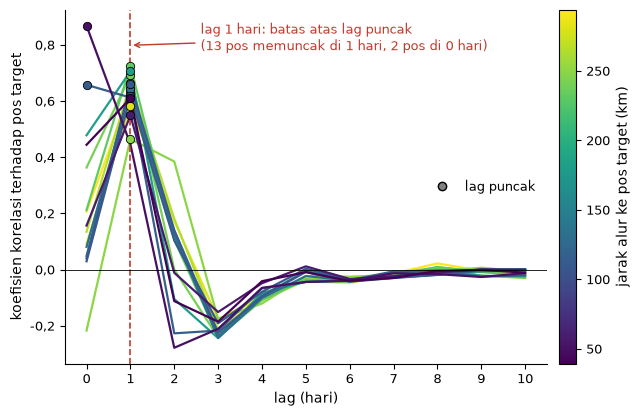

Gambar 2. Korelasi silang antara selisih harian debit tiap pos hulu dan selisih harian debit pos target 02035000 pada lag 0–10 hari, data latih. Warna garis menyatakan jarak alur ke pos target; titik menandai lag puncak tiap pos. Seluruh pos hulu memuncak pada lag 0–1 hari, termasuk pos terjauh (294,1 km), yang menyiratkan kecepatan rambat sekitar 3,4 m/s bila lag puncaknya 1 hari.


In [62]:
jarak = sp.loc[hulu, "jarak_alur_ke_muara_km"]
nrm = mpl.colors.Normalize(jarak.min(), jarak.max())
cm = plt.get_cmap(CMAP)

fig, ax = plt.subplots(figsize=(7.5, 4.6))
for p in hulu:
    w = cm(nrm(jarak[p]))
    ax.plot(r_lag.index, r_lag[p], color=w, lw=1.6)
    L = puncak[p]
    ax.plot(L, r_lag.at[L, p], "o", color=w, mec="black", mew=0.6, ms=6, zorder=3)
ax.axvline(1, color=WARNA["aksen"], ls="--", lw=1.2)
ax.axhline(0, color="black", lw=0.6)
n0, n1 = int((puncak == 0).sum()), int((puncak == 1).sum())
ax.annotate(f"lag 1 hari: batas atas lag puncak\n"
            f"({n1} pos memuncak di 1 hari, {n0} pos di 0 hari)",
            xy=(1, r_lag.max().max() * 0.92), xytext=(2.6, r_lag.max().max() * 0.9),
            fontsize=9, color=WARNA["aksen"],
            arrowprops=dict(arrowstyle="->", color=WARNA["aksen"]))
ax.set_xlabel("lag (hari)")
ax.set_ylabel("koefisien korelasi terhadap pos target")
ax.set_xticks(range(LAG_MAKS + 1))
sumbu_koma(ax, "y", 1)
sm = mpl.cm.ScalarMappable(norm=nrm, cmap=cm)
cb = fig.colorbar(sm, ax=ax, pad=0.02)
cb.set_label("jarak alur ke pos target (km)")
ax.legend(handles=[Line2D([], [], marker="o", ls="", color="grey", mec="black", label="lag puncak")],
          loc="center right", frameon=False)
v_rambat = jarak.max() * 1000 / 86400
ket = (
    f"Gambar 2. Korelasi silang antara selisih harian debit tiap pos hulu dan selisih harian debit pos "
    f"target {TARGET} pada lag 0–{LAG_MAKS} hari, data latih. Warna garis menyatakan jarak alur ke "
    f"pos target; titik menandai lag puncak tiap pos. Seluruh pos hulu memuncak pada lag {puncak.min()}–"
    f"{puncak.max()} hari, termasuk pos terjauh ({koma(jarak.max(), d=1)} km), yang menyiratkan kecepatan "
    f"rambat sekitar {koma(v_rambat, d=1)} m/s bila lag puncaknya 1 hari."
)
plt.show()
print(ket)

### Hasil

Tiga belas pos mencapai korelasi puncak pada lag 1 hari, sedangkan dua pos pada
lag 0 hari, yaitu 02026000 (James River at Bent Creek, 114 km) dan 02029000
(James River at Scottsville, 50 km). Keduanya berada di sungai utama, sedangkan
pos anak sungai dengan jarak yang hampir sama (02031000 dan 02028500, sekitar
110 km) mencapai puncak pada lag 1 hari. Jadi lag puncak tidak hanya ditentukan
oleh jarak alur, tetapi juga oleh posisi pos di sungai utama, tempat gelombang
banjir merambat lebih cepat. Lag puncak semua pos paling lama 1 hari, termasuk
pos yang berjarak 294 km. Pada lag 2 sampai 3 hari, korelasi hampir semua pos
menjadi negatif, artinya kenaikan debit di hulu diikuti penurunan debit di pos
target dua atau tiga hari kemudian setelah gelombangnya lewat.

Hasil ini menunjukkan kecepatan rambat sekitar 294 km per hari, atau **3,4 m/s**,
jauh lebih cepat daripada nilai umum 1 sampai 2 m/s untuk gelombang banjir.
Ada dua kemungkinan penjelasan. Pertama, pada sungai sebesar ini kecepatan
rambat gelombang memang bisa melebihi 3 m/s saat aliran tinggi. Kedua, sistem
hujan frontal di wilayah ini berukuran ratusan kilometer, sehingga hulu dan
hilir sering terkena hujan secara bersamaan. Sebagian korelasi pada lag nol
berasal dari hujan yang terjadi bersamaan, bukan dari perambatan aliran.

Dari hasil ini, pada horizon 1 hari data pos hulu memberikan informasi
perambatan secara langsung. Pada horizon 2 dan 3 hari, informasi perambatan
tersebut sudah lewat, sehingga model lebih bergantung pada dinamika resesi dan
simpanan air di DAS. Karena itu kontribusi komponen spasial diperkirakan paling
besar pada horizon 1 hari dan menurun pada horizon 3 hari. Dugaan ini akan diuji
setelah model dilatih.

### 23b. Konstanta waktu resesi

Resesi aliran sungai dimodelkan sebagai peluruhan eksponensial,
Q(t+1) = k · Q(t). Koefisien k diperkirakan dari median kemiringan log debit
pada hari-hari saat debit menurun. Konstanta waktunya adalah −1/ln k, yaitu
waktu yang dibutuhkan debit untuk turun menjadi 1/e atau sekitar 37 persen.

Besaran ini menentukan seberapa jauh ke belakang model perlu melihat untuk
mengetahui kondisi simpanan air di DAS.

In [63]:
ql = Qs[TARGET].iloc[:i_latih]
dlog = np.log(ql.replace(0, np.nan)).diff()
dlog_turun = dlog[dlog < 0]
k_res = float(np.exp(dlog_turun.median()))
tau = -1/np.log(k_res)

print(f"koefisien resesi harian k   : {k_res:.4f}")
print(f"konstanta waktu resesi tau  : {tau:.1f} hari")
print(f"waktu meluruh ke 5 persen   : {np.log(0.05)/np.log(k_res):.1f} hari\n")

print("autokorelasi debit pos target (data latih):")
print(f"{'lag':>6} {'r':>8}")
for L in [1, 2, 3, 5, 7, 10, 14, 21, 30]:
    print(f"{L:>6} {ql.corr(ql.shift(L)):>8.3f}")

koefisien resesi harian k   : 0.9143
konstanta waktu resesi tau  : 11.2 hari
waktu meluruh ke 5 persen   : 33.4 hari

autokorelasi debit pos target (data latih):
   lag        r
     1    0.853
     2    0.644
     3    0.524
     5    0.403
     7    0.335
    10    0.288
    14    0.276
    21    0.247
    30    0.232


### 23c. Panjang window yang dipakai

| Besaran | Nilai | Kebutuhan window |
|---|---|---|
| Lag perambatan maksimum | 1 hari | sekitar 3 hari |
| Konstanta waktu resesi | 11,2 hari | sekitar 1 sampai 1,5 kali τ |

Konstanta waktu resesi lebih menentukan karena nilainya jauh lebih besar.
Window yang dipakai adalah **14 hari**, setara dengan **1,25 kali konstanta
waktu resesi**, sehingga mencakup sekitar 1 − e^(−14/11,2), atau **71 persen**
sinyal resesi jika resesinya mengikuti satu fungsi eksponensial. Panjang ini
juga jauh melebihi lag perambatan maksimum.

Window yang lebih panjang hanya menambah sedikit informasi, karena autokorelasi
pada lag 21 dan 30 hari hampir sama, sementara jumlah parameter LSTM dan waktu
training terus bertambah.

In [64]:
LAG_DASAR = 1     # lag di tabel penetapan, diperiksa ulang di tahap 27
WINDOW = 14
print(f"panjang window  : {WINDOW} hari")
print(f"  = {WINDOW/tau:.2f} x konstanta waktu resesi ({tau:.1f} hari)")
print(f"  = {WINDOW/max(T_MAKS,1):.0f} x lag perambatan maksimum ({T_MAKS} hari)")
print(f"  mencakup {1-np.exp(-WINDOW/tau):.0%} sinyal resesi (anggapan eksponensial tunggal)")

panjang window  : 14 hari
  = 1.25 x konstanta waktu resesi (11.2 hari)
  = 14 x lag perambatan maksimum (1 hari)
  mencakup 71% sinyal resesi (anggapan eksponensial tunggal)


### Gambar 5 — Analisis resesi

Panel kiri menampilkan semua pasangan hari berurutan saat debit menurun. Pada
sumbu log-log, model peluruhan eksponensial berbentuk garis yang sejajar dengan
garis 1:1 dan bergeser sebesar ln k. Sebagai pembanding, ditampilkan juga
regresi kuadrat terkecil tanpa batasan. Panel kanan menampilkan satu kejadian
resesi, yaitu periode penurunan debit terpanjang di data latih, bersama panjang
window yang sudah ditetapkan.

In [65]:
qt, qt1 = ql.shift(1)[dlog < 0], ql[dlog < 0]      # pasangan (Q(t), Q(t+1)) pada hari menurun
b1, b0 = np.polyfit(np.log(qt), np.log(qt1), 1)

# satu kejadian resesi: rentetan hari menurun terpanjang di data latih
turun = dlog < 0
g = (turun != turun.shift()).cumsum()
ukuran = turun.groupby(g).sum()                          # panjang tiap rentetan hari menurun
hari = turun.index[g == ukuran.idxmax()]
n_res = len(hari)
mulai = hari[0] - pd.Timedelta(days=1)                    # hari puncak, sehari sebelum mulai turun
akhir = hari[-1]
kej = ql.loc[mulai - pd.Timedelta(days=5): akhir + pd.Timedelta(days=5)]
t_rel = (kej.index - mulai).days
k_kej = float(np.exp(np.polyfit(np.arange(n_res + 1), np.log(ql.loc[mulai:akhir]), 1)[0]))

# pelambatan resesi: tau menurut umur resesi, dari seluruh hari menurun di data latih
umur = turun.groupby(g).cumsum()                         # hari ke berapa dalam rentetan menurun
resesi_umur = pd.DataFrame([
    {"umur_resesi": lab, "n_hari": int(m.sum()), "tau_hari": round(float(-1 / dlog[m].median()), 1)}
    for lab, m in [("hari ke 1-7", turun & umur.between(1, 7)),
                   ("hari ke 8-14", turun & umur.between(8, 14)),
                   ("hari ke 15 ke atas", turun & (umur >= 15))]])

print(f"k median                : {k_res:.4f}   tau {tau:.1f} hari")
print(f"regresi bebas log-log   : kemiringan {b1:.4f}, potongan {b0:+.4f}")
print(f"hari menurun            : {len(qt):,} dari {len(ql)-1:,}")
print(f"kejadian resesi terpanjang: {mulai.date()} s.d. {akhir.date()}, {n_res} hari berturut-turut")
print(f"  k kejadian ini        : {k_kej:.4f}  (tau {-1/np.log(k_kej):.1f} hari)")
print(f"\nkonstanta waktu menurut umur resesi, seluruh {int(turun.sum()):,} hari menurun:")
print(resesi_umur.to_string(index=False))

k median                : 0.9143   tau 11.2 hari
regresi bebas log-log   : kemiringan 0.9513, potongan +0.1194
hari menurun            : 4,131 dari 6,391
kejadian resesi terpanjang: 2012-03-26 s.d. 2012-04-18, 23 hari berturut-turut
  k kejadian ini        : 0.9173  (tau 11.6 hari)

konstanta waktu menurut umur resesi, seluruh 4,131 hari menurun:
       umur_resesi  n_hari  tau_hari
       hari ke 1-7    3523      10.1
      hari ke 8-14     555      16.0
hari ke 15 ke atas      53      27.4


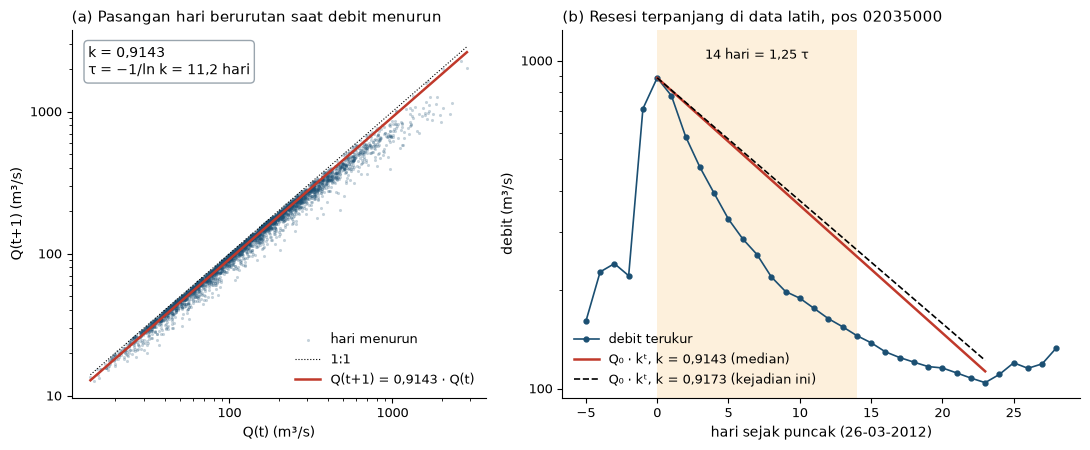

Gambar 5. Analisis resesi pos target 02035000, data latih. (a) Debit hari berikutnya terhadap debit hari ini pada 4.131 hari menurun; garis merah adalah model peluruhan eksponensial dengan koefisien resesi k = 0,9143 (median), setara konstanta waktu τ = 11,2 hari. (b) Kejadian resesi terpanjang (23 hari, mulai 26-03-2012) dengan kurva peluruhan k median (merah) dan k hasil pencocokan pada kejadian ini (hitam putus-putus); kurva terukur menyusut lebih cepat dari keduanya pada pekan pertama lalu lebih lambat sesudahnya. Daerah berarsir menunjukkan panjang window input 14 hari, setara 1,25 τ.


In [66]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})

a1.scatter(qt, qt1, s=5, alpha=0.25, color=WARNA["utama"], lw=0, label="hari menurun")
x = np.geomspace(qt.min(), qt.max(), 50)
a1.plot(x, x, color="black", lw=0.8, ls=":", label="1:1")
a1.plot(x, k_res * x, color=WARNA["aksen"], lw=1.8, label=f"Q(t+1) = {koma(k_res, d=4)} · Q(t)")
a1.set_xscale("log"); a1.set_yscale("log")
a1.set_xlabel("Q(t) (m³/s)"); a1.set_ylabel("Q(t+1) (m³/s)")
for a in (a1.xaxis, a1.yaxis):
    a.set_major_formatter(FuncFormatter(lambda y_, _: f"{y_:g}".replace(".", ",")))
a1.text(0.04, 0.96, f"k = {koma(k_res, d=4)}\nτ = −1/ln k = {koma(tau, d=1)} hari",
        transform=a1.transAxes, va="top", fontsize=10,
        bbox=dict(boxstyle="round", fc="white", ec=WARNA["abu"]))
a1.legend(loc="lower right", frameon=False)
a1.set_title("(a) Pasangan hari berurutan saat debit menurun", loc="left")

a2.plot(t_rel, kej.to_numpy(), "o-", color=WARNA["utama"], ms=3.5, lw=1.2, label="debit terukur")
tt = np.arange(0, n_res + 1)
a2.plot(tt, ql.loc[mulai] * k_res ** tt, color=WARNA["aksen"], lw=1.8,
        label=f"Q₀ · kᵗ, k = {koma(k_res, d=4)} (median)")
a2.plot(tt, ql.loc[mulai] * k_kej ** tt, color="black", lw=1.2, ls="--",
        label=f"Q₀ · kᵗ, k = {koma(k_kej, d=4)} (kejadian ini)")
a2.axvspan(0, WINDOW, color=WARNA["risiko"], alpha=0.18, lw=0)
a2.text(WINDOW / 2, kej.max() * 1.12, f"{WINDOW} hari = {koma(WINDOW / tau, d=2)} τ",
        ha="center", va="bottom", fontsize=9)
a2.set_yscale("log")
a2.set_ylim(None, kej.max() * 1.4)
a2.yaxis.set_major_formatter(FuncFormatter(lambda y_, _: f"{y_:g}".replace(".", ",")))
a2.set_xlabel(f"hari sejak puncak ({mulai.strftime('%d-%m-%Y')})")
a2.set_ylabel("debit (m³/s)")
a2.legend(frameon=False, loc="lower left")
a2.set_title(f"(b) Resesi terpanjang di data latih, pos {TARGET}", loc="left")
fig.tight_layout()
ket = (
    f"Gambar 5. Analisis resesi pos target {TARGET}, data latih. (a) Debit hari berikutnya terhadap "
    f"debit hari ini pada {ribu(len(qt))} hari menurun; garis merah adalah model peluruhan eksponensial dengan "
    f"koefisien resesi k = {koma(k_res, d=4)} (median), setara konstanta waktu τ = {koma(tau, d=1)} hari. "
    f"(b) Kejadian resesi terpanjang ({n_res} hari, mulai {mulai.strftime('%d-%m-%Y')}) dengan kurva "
    f"peluruhan k median (merah) dan k hasil pencocokan pada kejadian ini (hitam putus-putus); kurva terukur "
    f"menyusut lebih cepat dari keduanya pada pekan pertama lalu lebih lambat sesudahnya. Daerah berarsir "
    f"menunjukkan panjang window input {WINDOW} hari, setara {koma(WINDOW / tau, d=2)} τ."
)
plt.show()
print(ket)

### Hasil

Koefisien resesi dihitung dari seluruh 4.131 hari menurun di data latih, tanpa
memilih kejadian tertentu. Hari menurun adalah hari ketika debit lebih kecil
daripada hari sebelumnya, dan k adalah eksponensial dari median selisih
logaritma debit pada hari-hari tersebut. Hasilnya k = 0,9143 dan τ = 11,2 hari.
Pada kejadian resesi terpanjang, k hasil pencocokan pada seluruh kejadian
(0,9173) hampir sama dengan k median.

Satu kurva eksponensial tetap merupakan penyederhanaan. Regresi pada panel (a)
berkemiringan 0,95, bukan 1, artinya debit tinggi turun lebih cepat daripada
debit rendah. Hal yang sama terlihat jika hari menurun dikelompokkan menurut
umur resesinya, yaitu hari ke berapa sejak debit mulai turun:

| Umur resesi | Jumlah hari | Konstanta waktu |
|---|---|---|
| Hari ke 1–7 | 3.523 | 10,1 hari |
| Hari ke 8–14 | 555 | 16,0 hari |
| Hari ke 15 ke atas | 53 | 27,4 hari |

Pekan pertama masih memuat pengatusan aliran cepat, sedangkan sesudahnya yang
tersisa adalah aliran dasar dari simpanan air tanah, sehingga resesi melambat.
Pola pelambatan ini dilaporkan sebagai nuansa, bukan sebagai dasar penetapan
window. Dasar penetapan window tetap konstanta waktu 11,2 hari dari seluruh
hari menurun, sehingga window 14 hari setara 1,25 kali τ.

Nilai 71 persen sinyal resesi hanya berlaku dengan anggapan peluruhan
eksponensial tunggal. Untuk resesi yang sudah berumur lebih dari dua pekan,
14 hari masih kurang dari satu konstanta waktu.

---
## 24. Menyusun window waktu

Satu sampel terdiri dari data 14 hari terakhir di semua stasiun dan dipakai
untuk memprediksi debit pos target 1, 2, atau 3 hari ke depan.

Sampel yang mengandung baris tidak valid dibuang. Pada data ini tidak ada
sampel yang terbuang karena datanya lengkap, tetapi pengecekannya tetap dibuat
agar kode tetap benar jika pos atau periode diubah.

In [67]:
HORIZON = [1, 2, 3]

def susun(arr, i_target, window, horizon, sah, tak_murni):
    X, y, idx, murni = [], [], [], []
    for t in range(window-1, len(arr)-horizon):
        a, b = t-window+1, t+1
        if not sah[a:b].all() or not sah[t+horizon]:
            continue
        X.append(arr[a:b])
        y.append(arr[t+horizon, i_target])
        idx.append(t+horizon)
        # True kalau target hasil ukur, bukan perkiraan
        murni.append(not tak_murni[t+horizon, i_target])
    return (np.asarray(X)[..., None], np.asarray(y),
            np.asarray(idx), np.asarray(murni))

tensor = {}
for h in HORIZON:
    X, y, idx, murni = susun(scaled, i_target, WINDOW, h, sah, tak_murni)
    # 0 latih, 1 validasi, 2 uji, 3 uji-dikecualikan (target hasil perkiraan)
    bagian = np.where(idx < i_latih, 0, np.where(idx < i_val, 1, 2))
    bagian = np.where((bagian == 2) & (~murni), 3, bagian)
    tensor[h] = (X, y, idx, bagian, murni)
    print(f"horizon {h}: X{X.shape}  latih {int((bagian==0).sum()):,}  "
          f"validasi {int((bagian==1).sum()):,}  uji {int((bagian==2).sum()):,}  "
          f"uji-dikecualikan {int((bagian==3).sum()):,}")

# kode bagian 2 hanya menjamin nilai TARGET hasil ukur; window input masih bisa memuat A:e
X, y, idx, bagian, murni = tensor[1]
baris_w = (idx[bagian == 2] - 1)[:, None] + np.arange(-(WINDOW - 1), 1)[None, :]
E_w = Es.to_numpy()[baris_w]                                  # (sampel uji, window, stasiun)
n_uji = int((bagian == 2).sum())
n_uji_e_target = int(E_w[:, :, i_target].any(axis=1).sum())
n_uji_e_pos = int(E_w.any(axis=(1, 2)).sum())
print(f"\nsampel uji horizon 1 (kode 2): {n_uji:,}")
print(f"  window memuat A:e di pos target   : {n_uji_e_target:,}")
print(f"  window memuat A:e di pos mana pun : {n_uji_e_pos:,}")

horizon 1: X(9118, 14, 16, 1)  latih 6,378  validasi 1,370  uji 1,322  uji-dikecualikan 48
horizon 2: X(9117, 14, 16, 1)  latih 6,377  validasi 1,370  uji 1,322  uji-dikecualikan 48
horizon 3: X(9116, 14, 16, 1)  latih 6,376  validasi 1,370  uji 1,322  uji-dikecualikan 48

sampel uji horizon 1 (kode 2): 1,322
  window memuat A:e di pos target   : 301
  window memuat A:e di pos mana pun : 938


Sampel uji dengan nilai target hasil perkiraan tidak dibuang dari file, tetapi
diberi kode bagian 3. Dengan cara ini evaluasi bisa dilaporkan dua kali, yaitu
pada seluruh data uji dan pada sampel yang nilai targetnya hasil pengukuran.

Pengecualian ini hanya berlaku pada nilai yang diprediksi. Window input sampel
berkode 2 tetap boleh memuat nilai perkiraan. Dari 1.322 sampel uji horizon 1,
sebanyak 301 memuat `A:e` pada window pos target dan 938 memuat `A:e` pada pos
mana pun. Jadi data uji berkode 2 bukan data yang seluruhnya hasil pengukuran,
melainkan data yang nilai targetnya hasil pengukuran.

---
## 25. Menggabungkan atribut statis

Atribut statis disalin di sepanjang sumbu waktu sebagai channel tambahan. Cara
ini memang memakai memori lebih banyak, tetapi CNN jadi menerima atribut di
setiap langkah waktu dan setiap stasiun, sehingga kernel yang bergerak di sumbu
stasiun bisa langsung membandingkan debit dengan karakteristik fisik setiap
stasiun.

In [68]:
for h in HORIZON:
    X, y, idx, bagian, murni = tensor[h]
    if X.shape[-1] != 1:      # sudah digabung: menjalankan ulang sel ini tidak menggandakan channel
        print(f"horizon {h}: atribut sudah tergabung, {X.shape}")
        continue
    n_, t_, s_, _ = X.shape
    stat = np.broadcast_to(As[None, None, :, :], (n_, t_, s_, As.shape[1]))
    Xl = np.concatenate([X, stat], axis=-1).astype(np.float32)
    tensor[h] = (Xl, y.astype(np.float32), idx, bagian, murni)
    print(f"horizon {h}: {X.shape} -> {Xl.shape}   "
          f"{Xl.nbytes/1e6:.1f} MB")
print(f"\nchannel: 0 = debit terskala, 1-{As.shape[1]} = {', '.join(A.columns)}")

horizon 1: (9118, 14, 16, 1) -> (9118, 14, 16, 11)   89.9 MB
horizon 2: (9117, 14, 16, 1) -> (9117, 14, 16, 11)   89.9 MB
horizon 3: (9116, 14, 16, 1) -> (9116, 14, 16, 11)   89.8 MB

channel: 0 = debit terskala, 1-10 = jarak_alur_km, kemiringan_alur, elevasi_pos_m, log_luas, kebulatan, elev_rata_das_m, kemiringan_das, hujan_tahunan_cm, aliran_dasar, kerapatan_alur


---
## 26. Menyusun tensor hujan

### Scaling hujan

Sebaran hujan harian sangat berbeda dengan debit. Sebagian besar harinya
bernilai nol, dan sisanya sangat menceng. Standardisasi saja tidak mengubah
bentuk sebaran, sehingga semua hari nol menjadi satu nilai negatif yang sama,
sementara beberapa hari hujan lebat berada belasan standar deviasi di atasnya.

Karena itu data hujan diubah dengan **log1p**, yaitu ln(1 + x), lalu
distandardisasi. Nilai nol tetap nol sebelum distandardisasi, tidak ada masalah
logaritma dari nol, dan nilai-nilai ekstrem menjadi lebih rapat. Hal ini tidak
bertentangan dengan debit yang tidak dilogaritmakan, karena debit adalah
variabel yang diprediksi, sedangkan hujan hanya input, sama seperti luas DAS
yang dilogaritmakan di tahap 13.

Rata-rata dan standar deviasi dihitung hanya dari data latih untuk setiap pos,
lalu diterapkan ke seluruh periode.

In [69]:
def scaling_hujan(P_):
    L_ = np.log1p(P_)
    r, s = L_.iloc[:i_latih].mean(), L_.iloc[:i_latih].std(ddof=0)
    s = s.replace(0, 1.0)
    return (L_ - r) / s, r.to_numpy(), s.to_numpy()

S_terdekat, rata_t, std_t = scaling_hujan(P_terdekat)
S_idw, rata_i, std_i = scaling_hujan(P_idw)

lat_i = P_idw.iloc[:i_latih]
z_saja = (lat_i - lat_i.mean()) / lat_i.std(ddof=0)
banding_skala = pd.DataFrame({
    "nol_%": (lat_i.eq(0).mean() * 100).round(1),
    "skewness_asli": lat_i.skew().round(1),
    "maks_z_tanpa_log": z_saja.max().round(1),
    "skewness_log1p": np.log1p(lat_i).skew().round(1),
    "maks_z_log1p": S_idw.iloc[:i_latih].max().round(1),
})
print("pemetaan IDW, data latih:")
print(banding_skala.to_string())
print(f"\ncek data latih (IDW): rata-rata {S_idw.iloc[:i_latih].to_numpy().mean():+.2e}, "
      f"std {S_idw.iloc[:i_latih].to_numpy().std():.6f}")

pemetaan IDW, data latih:
          nol_%  skewness_asli  maks_z_tanpa_log  skewness_log1p  maks_z_log1p
02018000   50.0            4.1              11.0             1.4           3.7
02020500   46.0            3.9              11.5             1.3           3.7
02021500   49.3            4.3              12.3             1.4           3.8
02022500   56.3            4.6              12.7             1.5           3.9
02019500   49.7            4.2              12.1             1.4           3.8
02024000   65.9            5.2              14.4             1.7           4.1
02025500   56.5            4.5              14.7             1.5           4.0
02027000   52.3            4.5              13.9             1.4           3.9
02027500   52.3            4.5              14.1             1.4           3.9
02026000   57.8            4.3              12.4             1.5           3.9
02031000   54.1            4.2              10.3             1.5           3.8
02028500   55.9           

### Tensor

Untuk setiap horizon h, sampel ke-n pada tensor debit memiliki indeks target
`idx[n]`, dan window-nya mencakup hari `idx[n] − h − 13` sampai `idx[n] − h`.
Tensor hujan disusun dari hari yang sama, sehingga perbedaannya dengan tensor
debit hanya pada isi channel-nya.

Kedua metode pemetaan disimpan sebagai array terpisah, `X_terdekat` dan
`X_idw`, masing-masing berukuran `(sampel, 14, 16, 1)`. Contoh pemakaiannya:

```python
d  = np.load("processed/tensor_h1.npz", allow_pickle=True)
dh = np.load("processed/tensor_hujan_h1.npz", allow_pickle=True)
X  = np.concatenate([d["X"], dh["X_idw"]], axis=-1)     # (sampel, 14, 16, 12)
```

In [70]:
offset = np.arange(-(WINDOW - 1), 1)
tensor_hujan = {}
for h in HORIZON:
    X, y, idx, bagian, murni = tensor[h]
    baris_h = (idx - h)[:, None] + offset[None, :]                  # (sampel, 14)
    Xt = S_terdekat.to_numpy(np.float32)[baris_h][..., None]
    Xi = S_idw.to_numpy(np.float32)[baris_h][..., None]
    tensor_hujan[h] = dict(X_terdekat=Xt, X_idw=Xi,
                           cadangan_terdekat=cad_terdekat.to_numpy()[baris_h],
                           cadangan_idw=cad_idw.to_numpy()[baris_h],
                           idx=idx, bagian=bagian, murni=murni, pos=np.array(P_idw.columns, dtype=str),
                           baris_min=int(baris_h.min()))
    print(f"horizon {h}: X_debit {X.shape} | X_terdekat {Xt.shape} | X_idw {Xi.shape}")

horizon 1: X_debit (9118, 14, 16, 11) | X_terdekat (9118, 14, 16, 1) | X_idw (9118, 14, 16, 1)
horizon 2: X_debit (9117, 14, 16, 11) | X_terdekat (9117, 14, 16, 1) | X_idw (9117, 14, 16, 1)
horizon 3: X_debit (9116, 14, 16, 11) | X_terdekat (9116, 14, 16, 1) | X_idw (9116, 14, 16, 1)


---
# Bagian VI — Verifikasi dan penyimpanan

---
## 27. Verifikasi

### Gambar 6 — Diagram alur preprocessing

Diagram ini merangkum seluruh alur pengolahan debit. Semua angka di dalam kotak
dihitung dari data. Kotak oranye menandai tahap yang berisiko menyebabkan
kebocoran informasi dari periode uji, yaitu pembagian data dan scaling.

{'nldi': 249, 'dv': 23, 'lolos': 16, 'buang': 7, 'interp': 2, 'sel': 146112, 'latih': 6392, 'val': 1370, 'uji': 1370, 'sampel': 9118, 'uji3': 48, 'gg': 571, 'gg_aman': 336, 'attr': 10, 'shape': '9118 × 14 × 16 × 11'}


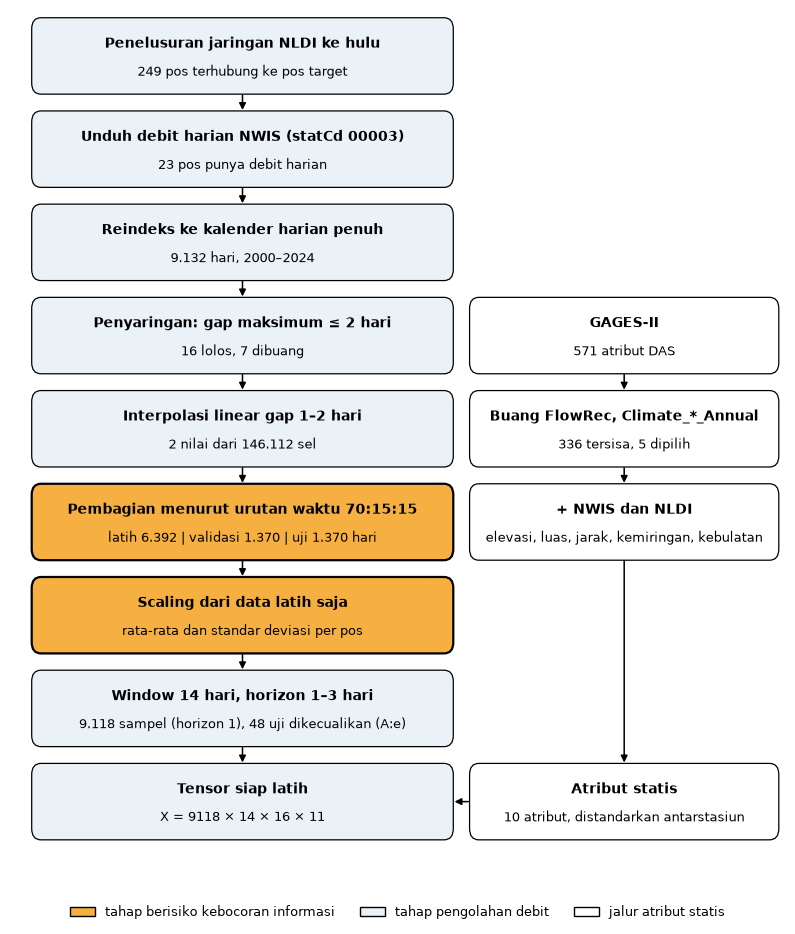

Gambar 6. Alur praproses dari data mentah sampai tensor siap latih. Kotak oranye menandai tahap yang berisiko membocorkan informasi periode uji, yaitu pembagian data menurut urutan waktu dan scaling yang parameternya dihitung dari data latih saja. Kolom kanan menunjukkan jalur atribut statis DAS. Sampel uji yang nilai targetnya berkode kualitas A:e (hasil perkiraan) diberi kode bagian tersendiri dan dikeluarkan dari evaluasi.


In [71]:
kol_gg = list(gg.columns)
X1, y1, idx1, bag1, _ = tensor[1]
angka_alur = {
    "nldi": len(nldi["features"]),
    "dv": Q_semua.shape[1],
    "lolos": len(pos), "buang": Q_semua.shape[1] - len(pos),
    "interp": n_interp, "sel": Qs.size,
    "latih": i_latih, "val": i_val - i_latih, "uji": n_hari - i_val,
    "sampel": len(y1), "uji3": int((bag1 == 3).sum()),
    "gg": len(kol_gg), "gg_aman": len(kol_gg) - len(dilarang), "attr": len(A.columns),
    "shape": " × ".join(str(s) for s in X1.shape),
}
print(angka_alur)

utama = [
    ("Penelusuran jaringan NLDI ke hulu", f"{ribu(angka_alur['nldi'])} pos terhubung ke pos target", False),
    ("Unduh debit harian NWIS (statCd 00003)", f"{angka_alur['dv']} pos punya debit harian", False),
    ("Reindeks ke kalender harian penuh", f"{ribu(n_hari)} hari, 2000–2024", False),
    ("Penyaringan: gap maksimum ≤ 2 hari", f"{angka_alur['lolos']} lolos, {angka_alur['buang']} dibuang", False),
    ("Interpolasi linear gap 1–2 hari", f"{angka_alur['interp']} nilai dari {ribu(angka_alur['sel'])} sel", False),
    ("Pembagian menurut urutan waktu 70:15:15",
     f"latih {ribu(angka_alur['latih'])} | validasi {ribu(angka_alur['val'])} | uji {ribu(angka_alur['uji'])} hari", True),
    ("Scaling dari data latih saja", "rata-rata dan standar deviasi per pos", True),
    (f"Window {WINDOW} hari, horizon 1–3 hari",
     f"{ribu(angka_alur['sampel'])} sampel (horizon 1), {angka_alur['uji3']} uji dikecualikan (A:e)", False),
    ("Tensor siap latih", f"X = {angka_alur['shape']}", False),
]
N_GG_DIPILIH = 5     # 5 dari GAGES-II, 5 lainnya dari NWIS dan NLDI (tahap 13)
samping = [
    ("GAGES-II", f"{angka_alur['gg']} atribut DAS", 3),
    ("Buang FlowRec, Climate_*_Annual", f"{angka_alur['gg_aman']} tersisa, {N_GG_DIPILIH} dipilih", 4),
    ("+ NWIS dan NLDI", "elevasi, luas, jarak, kemiringan, kebulatan", 5),
    ("Atribut statis", f"{angka_alur['attr']} atribut, distandarkan antarstasiun", 8),
]

fig, ax = plt.subplots(figsize=(10, 11.5))
ax.set_xlim(0, 10); ax.set_ylim(-1.0, len(utama) - 0.5); ax.axis("off")
LX, LW, BH = 0.3, 5.4, 0.78
def kotak(x, y_, w, judul, isi_, warna, tebal=False):
    ax.add_patch(FancyBboxPatch((x, y_ - BH / 2), w, BH, boxstyle="round,pad=0.02,rounding_size=0.12",
                                fc=warna, ec="black", lw=1.6 if tebal else 0.9))
    ax.text(x + w / 2, y_ + 0.13, judul, ha="center", va="center", fontsize=10, weight="bold")
    ax.text(x + w / 2, y_ - 0.17, isi_, ha="center", va="center", fontsize=9.5)
def panah(x1, y1_, x2, y2_):
    ax.annotate("", xy=(x2, y2_), xytext=(x1, y1_), arrowprops=dict(arrowstyle="-|>", lw=1.1, color="black"))

ys = [len(utama) - 1 - i for i in range(len(utama))]
for (j, isi_, risiko), y_ in zip(utama, ys):
    kotak(LX, y_, LW, j, isi_, WARNA["risiko"] if risiko else WARNA["netral"], tebal=risiko)
for ya, yb in zip(ys[:-1], ys[1:]):
    panah(LX + LW / 2, ya - BH / 2, LX + LW / 2, yb + BH / 2)

SX, SW = 5.95, 3.95
pos_y = {}
for j, isi_, yy in samping:
    y_ = len(utama) - 1 - yy
    pos_y[j] = y_
    kotak(SX, y_, SW, j, isi_, "white")
panah(SX + SW / 2, pos_y["GAGES-II"] - BH / 2, SX + SW / 2, pos_y["Buang FlowRec, Climate_*_Annual"] + BH / 2)
panah(SX + SW / 2, pos_y["Buang FlowRec, Climate_*_Annual"] - BH / 2, SX + SW / 2, pos_y["+ NWIS dan NLDI"] + BH / 2)
panah(SX + SW / 2, pos_y["+ NWIS dan NLDI"] - BH / 2, SX + SW / 2, pos_y["Atribut statis"] + BH / 2)
panah(SX, pos_y["Atribut statis"], LX + LW, ys[-1])
ax.legend(handles=[Patch(fc=WARNA["risiko"], ec="black", label="tahap berisiko kebocoran informasi"),
                   Patch(fc=WARNA["netral"], ec="black", label="tahap pengolahan debit"),
                   Patch(fc="white", ec="black", label="jalur atribut statis")],
          loc="lower center", frameon=False, ncol=3, bbox_to_anchor=(0.5, -0.04))
ket = (
    f"Gambar 6. Alur praproses dari data mentah sampai tensor siap latih. Kotak oranye menandai tahap "
    f"yang berisiko membocorkan informasi periode uji, yaitu pembagian data menurut urutan waktu dan "
    f"scaling yang parameternya dihitung dari data latih saja. Kolom kanan menunjukkan jalur atribut "
    f"statis DAS. Sampel uji yang nilai targetnya berkode kualitas A:e (hasil perkiraan) diberi kode "
    f"bagian tersendiri dan dikeluarkan dari evaluasi."
)
plt.show()
print(ket)

### Pemeriksaan akhir

Sel berikut menjalankan semua pemeriksaan terhadap hasil preprocessing, mulai
dari bentuk tensor, kebocoran data, hasil analisis eksploratif, data hujan,
sampai penanganan nilai akumulasi. Semua pemeriksaan harus lolos sebelum data
disimpan di tahap 28, dan sel akan berhenti dengan error jika ada yang gagal.

Lag puncak dibandingkan dengan nilai yang dipakai untuk menentukan panjang
window di tahap 23c, sedangkan konstanta resesi dibandingkan dengan nilai yang
dihitung ulang dari data latih.

Lima pemeriksaan ditulis sebagai fungsi, yaitu parameter scaling, atribut
statis, lembar GAGES-II, kesejajaran tensor hujan, dan konstanta resesi. Sel
sesudahnya memberi kelima fungsi itu masukan yang sengaja salah dan memastikan
semuanya menolak, karena pemeriksaan yang tidak pernah bisa gagal tidak menguji
apa pun.

In [72]:
uji = []
def periksa(kelompok, nama, lulus):
    uji.append((kelompok, nama, bool(lulus)))

# --- lima pemeriksaan berikut ditulis sebagai fungsi agar bisa diberi masukan yang salah (sel berikutnya)
def cek_skala(q, rata, std, i_latih):
    """(cocok, beda): rata dan std sama dengan hitung ulang dari irisan latih, toleransi 1e-10;
    dan parameter dari seluruh data berbeda dari keduanya."""
    sama = lambda a, b: np.allclose(a, b, rtol=0, atol=1e-10)
    cocok = sama(q[:i_latih].mean(axis=0), rata) and sama(q[:i_latih].std(axis=0), std)
    beda = not sama(q.mean(axis=0), rata) and not sama(q.std(axis=0), std)
    return cocok, beda

def baca_sumber_atribut():
    """Sepuluh atribut dibaca ulang langsung dari raw/, terpisah dari tabel A."""
    s = pd.read_csv(RAW/"spatial"/"atribut_turunan.csv", dtype={"kode_pos": str})
    s.index = s.pop("kode_pos").str.zfill(8)
    g_ = pd.read_csv(RAW/"gagesii"/"gagesii_atribut.csv", dtype={"STAID": str})
    g_.index = g_.pop("STAID").str.zfill(8)
    n_ = baca_rdb(RAW/"sites"/"site_info.rdb").drop_duplicates("site_no").set_index("site_no")
    d_ = {"jarak_alur_km": s["jarak_alur_ke_muara_km"],
          "kemiringan_alur": s["kemiringan_ke_muara_m_per_km"].fillna(0.0),
          "elevasi_pos_m": pd.to_numeric(n_["alt_va"], errors="coerce") * FT_KE_M,
          "log_luas": np.log10(pd.to_numeric(n_["drain_area_va"], errors="coerce") * MI2_KE_KM2),
          "kebulatan": s["kebulatan"]}
    d_.update({a: g_[k] for a, k in KOLOM_GG.items()})
    return pd.DataFrame(d_).loc[pos, list(A.columns)]

def cek_atribut(X, sumber):
    """Tiap atribut bervariasi antarstasiun sebelum distandarkan, dan channel statis tensor
    sama dengan nilai dari raw/ yang distandarkan ulang (ddof=0)."""
    s = sumber.to_numpy(float)
    if not (s.std(axis=0) > 0).all():
        return False
    return np.allclose(X[0, 0, :, 1:], (s - s.mean(axis=0)) / s.std(axis=0), atol=1e-5)

def cek_lembar(kolom_masuk, kolom_gg, dilarang):
    """Kolom GAGES-II yang masuk tensor ada di daftar kolom aslinya dan bukan dari lembar terlarang."""
    awalan = tuple(l + "__" for l in dilarang)
    return (len(kolom_masuk) > 0 and all(k in kolom_gg for k in kolom_masuk)
            and not any(k.startswith(awalan) for k in kolom_masuk))

def cek_sejajar(hujan, idx, bagian, pos):
    """idx, bagian, dan pos tensor hujan identik dengan tensor debit."""
    return (np.array_equal(hujan["idx"], idx) and np.array_equal(hujan["bagian"], bagian)
            and list(hujan["pos"]) == list(pos))

def cek_tau(q_latih, tau_dipakai):
    """tau yang dipakai sama dengan hitung ulang dari deret debit yang diberikan."""
    d_ = np.log(q_latih.replace(0, np.nan)).diff()
    return abs(-1 / d_[d_ < 0].median() - tau_dipakai) < 1e-10

# ---------- tensor debit horizon 1
X, y, idx, bagian, murni = tensor[1]
periksa("tensor", "bentuk tensor sesuai", X.ndim == 4 and X.shape[2] == len(pos)
        and X.shape[1] == WINDOW and X.shape[3] == 1 + As.shape[1])
periksa("tensor", "tidak ada NaN maupun inf",
        not (np.isnan(X).any() or np.isinf(X).any() or np.isnan(y).any() or np.isinf(y).any()))
skala_cocok, skala_beda = cek_skala(Qs.to_numpy(float), rata, std, i_latih)
periksa("tensor", "parameter scaling sama dengan hitung ulang dari data latih (1e-10)", skala_cocok)
periksa("tensor", "parameter scaling dari seluruh data berbeda dari yang dipakai", skala_beda)
periksa("tensor", "tidak ada kebocoran waktu antarbagian data",
        idx[bagian == 0].max() < idx[bagian >= 1].min()
        and idx[bagian == 1].max() < idx[(bagian == 2) | (bagian == 3)].min())
periksa("tensor", "atribut statis konstan sepanjang waktu", float(X[:, :, :, 1:].var(axis=1).max()) < 1e-8)
sumber_atribut = baca_sumber_atribut()
periksa("tensor", "atribut bervariasi antarstasiun dan cocok dengan sumbernya di raw/", cek_atribut(X, sumber_atribut))
periksa("tensor", "y sama dengan channel debit pada indeks target", np.allclose(y, scaled[idx, i_target], atol=1e-5))
periksa("tensor", "sampel uji-dikecualikan memang hasil perkiraan",
        tak_murni[idx[bagian == 3], i_target].all() if (bagian == 3).any() else True)

# ---------- analisis eksploratif
periksa("analisis", "korelasi dihitung dari data latih saja", gab_latih.index.max() == PERIODE[i_latih - 1])
periksa("analisis", "matriks korelasi 32 x 32", K_level.shape == (32, 32) and K_diff.shape == (32, 32))
periksa("analisis", "urutan pos di matriks korelasi mengikuti urutan hulu ke hilir",
        list(K_level.columns[:16]) == [f"{p}_Q" for p in pos])
periksa("analisis", "lag puncak tidak lebih dari dasar penentuan window", int(puncak.max()) <= LAG_DASAR)
periksa("analisis", "konstanta resesi yang dipakai sama dengan hitung ulang dari data latih",
        ql.index.max() == PERIODE[i_latih - 1] and cek_tau(Qs[TARGET].iloc[:i_latih], tau))
periksa("analisis", "tabel 1 berisi 16 pos tanpa nilai kosong", len(tab1) == 16 and not tab1.isna().any().any())

# ---------- tensor hujan
for h in HORIZON:
    Xd, yd, idxd, bagd, murd = tensor[h]
    t = tensor_hujan[h]
    periksa("hujan", f"h{h}: bentuk sama dengan tensor debit kecuali channel",
            t["X_idw"].shape[:3] == Xd.shape[:3] and t["X_terdekat"].shape[:3] == Xd.shape[:3])
    periksa("hujan", f"h{h}: idx, bagian, murni identik",
            np.array_equal(t["idx"], idxd) and np.array_equal(t["bagian"], bagd) and np.array_equal(t["murni"], murd))
    periksa("hujan", f"h{h}: idx, bagian, dan pos sejajar dengan tensor debit", cek_sejajar(t, idxd, bagd, pos))
    periksa("hujan", f"h{h}: tidak ada NaN maupun inf",
            np.isfinite(t["X_idw"]).all() and np.isfinite(t["X_terdekat"]).all())
    # window tensor debit berakhir pada hari idx - h: dicek lewat y sampel lain,
    # lalu dipastikan tensor hujan mengambil hari yang sama
    y_pada = dict(zip(idxd, yd))
    cocok = [np.isclose(Xd[n_, -1, i_target, 0], y_pada[idxd[n_] - h], atol=1e-5)
             for n_ in range(len(idxd)) if idxd[n_] - h in y_pada]
    cocok0 = [np.isclose(Xd[n_, 0, i_target, 0], y_pada[idxd[n_] - h - (WINDOW - 1)], atol=1e-5)
              for n_ in range(len(idxd)) if idxd[n_] - h - (WINDOW - 1) in y_pada]
    hujan_ok = np.allclose(t["X_idw"][:, -1, :, 0], S_idw.to_numpy(np.float32)[idxd - h])
    periksa("hujan", f"h{h}: hari pertama dan terakhir window sejajar dengan tensor debit",
            len(cocok) > 1000 and all(cocok) and len(cocok0) > 1000 and all(cocok0) and hujan_ok)
periksa("hujan", "urutan pos sama dengan tensor debit", list(P_idw.columns) == pos == list(P_terdekat.columns))
periksa("hujan", "scaling dari data latih (rata-rata 0, std 1)",
        all(abs(S.iloc[:i_latih].mean()).max() < 1e-9 and abs(S.iloc[:i_latih].std(ddof=0) - 1).max() < 1e-9
            for S in (S_idw, S_terdekat)))
periksa("hujan", "data uji tidak ikut menentukan parameter scaling",
        not np.allclose(np.log1p(P_idw).mean().to_numpy(), rata_i))
periksa("hujan", "tidak ada interpolasi linear: nilai tambalan seluruhnya nol", (H[diisi].stack().dropna() == 0).all())
periksa("hujan", "hujan tidak negatif", (H.stack().dropna() >= 0).all() and (P_idw >= 0).all().all())
periksa("hujan", "hasil pemetaan lengkap", not P_idw.isna().any().any() and not P_terdekat.isna().any().any())
periksa("hujan", "koreksi jam: hanya stasiun yang terlambat yang dimajukan satu hari",
        set(GESER.values()) <= {0, -1} and [s for s in ST if GESER[s] == -1] == terlambat)
r_sel = {s: {L: lat2[ACUAN].corr(lat2[s].shift(-L)) for L in (-1, 0, 1)} for s in ST if s != ACUAN}
periksa("hujan", "setelah koreksi, korelasi tiap stasiun terhadap acuan tertinggi pada geseran 0",
        all(max(r, key=r.get) == 0 for r in r_sel.values()))
periksa("hujan", "indeks window tensor hujan tidak negatif", all(tensor_hujan[h]["baris_min"] >= 0 for h in HORIZON))
t_c = pd.Timestamp("2003-09-22") + pd.Timedelta(days=GESER[KONCORD])
periksa("hujan", "nilai Concord 22-09-2003 (258,8 mm) dijadikan NaN dan tercatat",
        np.isnan(mm_sel.at[t_c, KONCORD]) and akumulasi.at[t_c, KONCORD]
        and mm.at[pd.Timestamp("2003-09-22"), KONCORD] == 258.8)
periksa("hujan", "penanganan akumulasi hanya mengubah satu sel", int(akumulasi.sum().sum()) == 1)
periksa("hujan", "sel akumulasi tidak ikut diisi nol", not (diisi & akumulasi).any().any() and np.isnan(H.at[t_c, KONCORD]))

# ---------- umum
periksa("umum", "pos target lolos penyaringan", TARGET in pos)
periksa("umum", "pos target berada paling hilir", pos[-1] == TARGET)
periksa("umum", "debit 16 pos lengkap setelah penambalan", sah.all())
periksa("umum", "16 stasiun hujan", len(ST) == 16)
periksa("umum", "semua stasiun hujan punya nama pendek", set(NAMA_PENDEK) == set(ST))
periksa("umum", "kolom GAGES-II yang masuk tensor bukan dari FlowRec maupun Climate_*_Annual",
        cek_lembar(list(KOLOM_GG.values()), list(gg.columns), LEMBAR_DILARANG))

for kelompok, nama, lulus in uji:
    print(f"  {'LULUS' if lulus else 'GAGAL'}  [{kelompok:8}] {nama}")
print(f"\nper kelompok: {pd.Series([k for k, _, _ in uji]).value_counts().to_dict()}")
assert all(l for _, _, l in uji), "ADA PEMERIKSAAN YANG GAGAL"
print(f"{len(uji)}/{len(uji)} pemeriksaan lolos")

  LULUS  [tensor  ] bentuk tensor sesuai
  LULUS  [tensor  ] tidak ada NaN maupun inf
  LULUS  [tensor  ] parameter scaling sama dengan hitung ulang dari data latih (1e-10)
  LULUS  [tensor  ] parameter scaling dari seluruh data berbeda dari yang dipakai
  LULUS  [tensor  ] tidak ada kebocoran waktu antarbagian data
  LULUS  [tensor  ] atribut statis konstan sepanjang waktu
  LULUS  [tensor  ] atribut bervariasi antarstasiun dan cocok dengan sumbernya di raw/
  LULUS  [tensor  ] y sama dengan channel debit pada indeks target
  LULUS  [tensor  ] sampel uji-dikecualikan memang hasil perkiraan
  LULUS  [analisis] korelasi dihitung dari data latih saja
  LULUS  [analisis] matriks korelasi 32 x 32
  LULUS  [analisis] urutan pos di matriks korelasi mengikuti urutan hulu ke hilir
  LULUS  [analisis] lag puncak tidak lebih dari dasar penentuan window
  LULUS  [analisis] konstanta resesi yang dipakai sama dengan hitung ulang dari data latih
  LULUS  [analisis] tabel 1 berisi 16 pos tanpa nilai 

### Uji negatif pemeriksaan

Setiap fungsi pemeriksaan diberi masukan yang sengaja salah. Semuanya harus
mengembalikan `False`.

In [73]:
q_ = Qs.to_numpy(float)
t1 = tensor_hujan[1]
tukar = sumber_atribut.copy(); tukar.iloc[[0, 1]] = sumber_atribut.iloc[[1, 0]].to_numpy()
salah = {
    "skala: parameter dihitung dari seluruh data, cocok": cek_skala(q_, q_.mean(axis=0), q_.std(axis=0), i_latih)[0],
    "skala: parameter dihitung dari seluruh data, beda": cek_skala(q_, q_.mean(axis=0), q_.std(axis=0), i_latih)[1],
    "skala: std memakai ddof=1": cek_skala(q_, rata, q_[:i_latih].std(axis=0, ddof=1), i_latih)[0],
    "atribut: dua stasiun tertukar": cek_atribut(X, tukar),
    "atribut: satu atribut konstan di semua stasiun": cek_atribut(X, sumber_atribut.assign(kebulatan=0.3)),
    "atribut: distandarkan dengan ddof=1": cek_atribut(X * np.sqrt(15 / 16), sumber_atribut),
    "lembar: ada kolom FlowRec": cek_lembar(list(KOLOM_GG.values()) + ["FlowRec__FLOWYRS_1990_2009"],
                                            list(gg.columns), LEMBAR_DILARANG),
    "lembar: ada kolom Climate_Ppt_Annual": cek_lembar(["Climate_Ppt_Annual__PPT2009_AVG"], list(gg.columns), LEMBAR_DILARANG),
    "lembar: kolom tidak ada di GAGES-II": cek_lembar(["Topo__TIDAK_ADA"], list(gg.columns), LEMBAR_DILARANG),
    "sejajar: idx hujan tergeser satu hari": cek_sejajar({**t1, "idx": t1["idx"] + 1}, idx, bagian, pos),
    "sejajar: bagian hujan berbeda": cek_sejajar({**t1, "bagian": np.zeros_like(t1["bagian"])}, idx, bagian, pos),
    "sejajar: urutan pos hujan terbalik": cek_sejajar({**t1, "pos": t1["pos"][::-1]}, idx, bagian, pos),
    "tau: dihitung dari seluruh periode": cek_tau(Qs[TARGET], tau),
    "tau: nilai dibulatkan 11,2": cek_tau(Qs[TARGET].iloc[:i_latih], 11.2),
}
for nama, hasil in salah.items():
    print(f"  {'DITOLAK' if not hasil else 'LOLOS (SALAH)'}  {nama}")
assert not any(salah.values()), "ADA PEMERIKSAAN YANG MENERIMA MASUKAN SALAH"
print(f"{len(salah)}/{len(salah)} masukan salah ditolak")

  DITOLAK  skala: parameter dihitung dari seluruh data, cocok
  DITOLAK  skala: parameter dihitung dari seluruh data, beda
  DITOLAK  skala: std memakai ddof=1
  DITOLAK  atribut: dua stasiun tertukar
  DITOLAK  atribut: satu atribut konstan di semua stasiun
  DITOLAK  atribut: distandarkan dengan ddof=1
  DITOLAK  lembar: ada kolom FlowRec
  DITOLAK  lembar: ada kolom Climate_Ppt_Annual
  DITOLAK  lembar: kolom tidak ada di GAGES-II
  DITOLAK  sejajar: idx hujan tergeser satu hari
  DITOLAK  sejajar: bagian hujan berbeda
  DITOLAK  sejajar: urutan pos hujan terbalik
  DITOLAK  tau: dihitung dari seluruh periode
  DITOLAK  tau: nilai dibulatkan 11,2
14/14 masukan salah ditolak


---
## 28. Menyimpan output dan metadata

### Debit

In [74]:
for h in HORIZON:
    X, y, idx, bagian, murni = tensor[h]
    np.savez_compressed(
        PROC/f"tensor_h{h}.npz",
        X=X, y=y, idx=idx, bagian=bagian, murni=murni,
        rata=rata, std=std, i_target=i_target,
        pos=np.array(pos), atribut=np.array(A.columns.tolist()),
        tanggal=Qs.index.astype(str).to_numpy(),
    )

metadata = {
    "sumber": ["USGS NWIS", "USGS NLDI", "GAGES-II (Falcone 2011)"],
    "notebook": "preprocessing/preprocessing.ipynb",
    "pos_hulu_ke_hilir": pos,
    "pos_target": TARGET,
    "indeks_target": int(i_target),
    "periode": [str(Qs.index[0].date()), str(Qs.index[-1].date())],
    "n_hari": int(len(Qs)),
    "panjang_window": WINDOW,
    "horizon": HORIZON,
    "channel": ["debit_terskala"] + A.columns.tolist(),
    "alasan_atribut": ALASAN,
    "kode_bagian": {"0": "latih", "1": "validasi", "2": "uji",
                    "3": "uji, dikecualikan karena target hasil perkiraan"},
    "keputusan": {
        "1_jumlah_pos": f"{len(pos)}, gap maksimum 2 hari, total {n_interp} nilai interpolasi",
        "2_input": ("debit saja; curah hujan disiapkan terpisah di tensor_hujan_h*.npz "
                      "untuk eksperimen lanjutan"),
        "3_transformasi": ("standardisasi saja, tanpa logaritma. Sebaran tetap "
                           "menceng, jadi metrik harus dilaporkan terpisah per "
                           "rentang aliran"),
        "4_atribut": f"{len(A.columns)} dari {gg.shape[1]} yang tersedia",
        "5_nilai_perkiraan": ("sampel uji yang nilai TARGET-nya A:e diberi kode bagian 3 dan keluar dari "
                              "data uji. Pengecualian hanya berlaku pada nilai yang diprediksi; window "
                              f"input tetap boleh memuat A:e. Dari {n_uji} sampel uji horizon 1, "
                              f"{n_uji_e_target} memuat A:e pada window pos target dan {n_uji_e_pos} pada "
                              "pos mana pun"),
    },
    "lembar_gagesii_dilarang": LEMBAR_DILARANG,
    "alasan_dilarang": {
        "FlowRec": (f"riwayat pemantauan pos, bukan perilaku DAS: {len(wy)} kolom flag tahun air "
                    "wy1900 sampai wy2009, jumlah tahun rekaman lengkap (FLOWYRS_1900_2009, "
                    "FLOWYRS_1950_2009, FLOWYRS_1990_2009), persentase nilai perkiraan "
                    "(FLOW_PCT_EST_VALUES), dan status aktif 2009 (ACTIVE09). Untuk 2000 sampai 2009 "
                    "kesepuluh kolom tahun airnya bernilai seragam di 16 pos sehingga tidak membawa "
                    "informasi pembeda. Lembar ini tidak membocorkan periode uji: GAGES-II berhenti "
                    "pada 2009, periode uji mulai 2021"),
        "Climate_Ppt_Annual, Climate_Tmp_Annual": "nilai tahunan, bukan harian, dan berhenti 2009",
    },
    "catatan_BFI_AVE": ("BFI_AVE (aliran_dasar) dan lembar FlowRec sama-sama diturunkan dari rekaman debit. "
                        "BFI_AVE tetap dipakai karena menggambarkan sifat perilaku DAS, yaitu porsi aliran "
                        "dari simpanan air tanah, dan lazim dipakai sebagai deskriptor DAS pada literatur "
                        "hidrologi termasuk CAMELS. FlowRec menggambarkan riwayat pemantauan, yaitu tahun "
                        "mana saja pos merekam aliran, yang tidak menjelaskan perilaku DAS. BFI_AVE adalah "
                        "rata-rata jangka panjang terbitan 2011, tidak memuat periode uji"),
    "catatan_nama_kolom": ("nama kolom jarak_alur_ke_muara_km dan kemiringan_ke_muara_m_per_km di "
                           "raw/spatial/atribut_turunan.csv bersifat historis. Yang dimaksud adalah jarak "
                           "alur dan kemiringan ke pos target 02035000 (batas hilir penelitian), bukan ke "
                           "muara Sungai James"),
    "keterbatasan_urutan_stasiun": [
        ("urutan relatif 02031000 (110,2 km) dan 02028500 (109,6 km) tidak tegas: selisih 0,6 km lebih "
         "kecil daripada panjang segmen alur NHDPlus rata-rata di lintasan kedua pos (1,0 sampai 1,6 km)"),
        ("jaringan sungai berbentuk pohon, sedangkan sumbu stasiun berbentuk barisan; pos yang "
         "bersebelahan bisa berada di cabang berbeda, misalnya 02031000 (Mechums, hulu Rivanna) "
         "terpisah tiga posisi dari 02034000 (Rivanna)"),
    ],
    "aturan_gap": {"interpolasi_sampai_hari": GAP_INTERP,
                      "flag_sampai_hari": GAP_FLAG,
                      "lebih_panjang": "pos dibuang"},
    "pembagian": "70 / 15 / 15 menurut urutan waktu",
    "penskalaan": ("rata-rata dan standar deviasi dari data latih saja; ddof=0 untuk debit, atribut "
                   "statis, dan hujan"),
    "satuan_debit": "m3/s, dikonversi dari ft3/s faktor 0.0283168466",
    "ambang_aliran": {"rendah_kuartil1": round(q25_target, 2),
                      "tinggi_kuartil3": round(q75_target, 2),
                      "catatan": ("kuartil 1 dan 3 debit pos target dari data latih saja; dipakai untuk "
                                  "mengelompokkan hari saat evaluasi")},
    "justifikasi_window": {
        "lag_perambatan_maks_hari": T_MAKS,
        "metode_lag": "korelasi silang selisih harian, data latih saja",
        "koefisien_resesi_k": round(k_res, 4),
        "konstanta_waktu_resesi_hari": round(tau, 1),
        "n_hari_menurun": int(turun.sum()),
        "metode_resesi": ("k = exp(median selisih log debit) pada seluruh hari menurun data latih, tanpa "
                          "memilih kejadian; hari menurun = debit lebih kecil daripada hari sebelumnya"),
        "dasar": ("14 hari = 1,25 x konstanta waktu resesi, dengan anggapan peluruhan eksponensial "
                  "tunggal"),
        "pelambatan_resesi": {
            "catatan": ("nuansa, bukan dasar penetapan window: pekan pertama masih memuat pengatusan "
                        "aliran cepat, sesudahnya tersisa aliran dasar dari simpanan air tanah"),
            "tau_menurut_umur_resesi": resesi_umur.to_dict("records"),
        },
    },
    "belum_selesai": [
        "curah hujan belum dipakai di model dasar; tensor terpisah sudah tersedia di tensor_hujan_h*.npz",
        "sebagian pos berstatus Non-reference menurut GAGES-II",
    ],
}
(PROC/"metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False))
mutu.to_csv(PROC/"mutu_semua_pos.csv", index=False)
mutu[mutu["pos"].isin(pos)].to_csv(PROC/"mutu_pos_terpilih.csv", index=False)
A.to_csv(PROC/"atribut_terpakai.csv")
for f in sorted(PROC.glob("*.*")):
    print(f"  {f.stat().st_size/1e6:7.2f} MB  {f.relative_to(ROOT)}")

     0.00 MB  processed/atribut_terpakai.csv
     0.01 MB  processed/metadata.json
     0.00 MB  processed/mutu_pos_terpilih.csv
     0.00 MB  processed/mutu_semua_pos.csv
     1.43 MB  processed/tensor_h1.npz
     1.43 MB  processed/tensor_h2.npz
     1.43 MB  processed/tensor_h3.npz
     0.56 MB  processed/tensor_hujan_h1.npz
     0.56 MB  processed/tensor_hujan_h2.npz
     0.56 MB  processed/tensor_hujan_h3.npz


### Curah hujan

In [75]:
st.to_csv(PROC_H / "stasiun_hujan.csv")
H.to_csv(PROC_H / "hujan_harian_mm.csv", float_format="%.1f")
mutu_hujan.to_csv(PROC_H / "mutu_stasiun_hujan.csv")
D_ps.round(2).to_csv(PROC_H / "jarak_pos_ke_stasiun.csv")
P_terdekat.to_csv(PROC_H / "hujan_per_pos_terdekat.csv", float_format="%.2f")
P_idw.to_csv(PROC_H / "hujan_per_pos_idw.csv", float_format="%.2f")

for h in HORIZON:
    t = tensor_hujan[h]
    np.savez_compressed(
        PROC / f"tensor_hujan_h{h}.npz",
        X_terdekat=t["X_terdekat"], X_idw=t["X_idw"],
        cadangan_terdekat=t["cadangan_terdekat"], cadangan_idw=t["cadangan_idw"],
        idx=t["idx"], bagian=t["bagian"], murni=t["murni"],
        rata_terdekat=rata_t, std_terdekat=std_t, rata_idw=rata_i, std_idw=std_i,
        pos=t["pos"], tanggal=PERIODE.astype(str).to_numpy(),
        channel=np.array(["hujan_log1p_terskala"]),
    )

# kesejajaran diperiksa sekali lagi pada file yang sudah tersimpan
for h in HORIZON:
    dd = np.load(PROC / f"tensor_h{h}.npz", allow_pickle=True)
    dh = np.load(PROC / f"tensor_hujan_h{h}.npz", allow_pickle=True)
    assert cek_sejajar(dh, dd["idx"], dd["bagian"], dd["pos"]), f"tensor hujan h{h} tidak sejajar dengan tensor debit"

calon_lain = calon_akumulasi[calon_akumulasi["stasiun"] != KONCORD]
putusan = {"USC00442142": "pola akumulasi; belum diubah, penanganannya masih perlu diputuskan",
           "USC00448941": "bukan akumulasi; bandara Charlottesville mencatat 75,2 mm pada tanggal yang sama"}
meta_h = {
    "sumber": "NOAA GHCN-Daily, elemen PRCP, file .dly di raw/hujan/dly",
    "notebook": "preprocessing/preprocessing.ipynb, tahap 14-17 dan 26",
    "periode": [str(PERIODE[0].date()), str(PERIODE[-1].date())],
    "stasiun_barat_ke_timur": ST,
    "nama_stasiun": {s: st.at[s, "nama"] for s in ST},
    "pos_hulu_ke_hilir": pos,
    "satuan": "mm/hari, dikonversi dari per-sepuluh mm",
    "kalender": ("tengah malam ke tengah malam, sama dengan debit USGS; stasiun COOP yang dibaca pagi "
                 "hari dimajukan satu hari"),
    "aturan": {
        "tanggal_fiktif": "blok hari 29-31 pada bulan yang lebih pendek dilewati, bukan dihitung hilang",
        "nilai_9999": "kosong",
        "qflag_terisi": "kosong; nilai gagal uji kualitas NOAA tidak dipakai",
        "mflag_T": "dipakai, nilainya 0 (trace)",
        "mflag_P": "dipakai sebagai 0; hari ber-P tidak lebih sering hujan di stasiun acuan daripada hari nol biasa",
        "jam_pengamatan": {
            "acuan": ACUAN,
            "metode": "korelasi terhadap acuan pada geseran 0 dan +1 hari, data latih",
            "dimajukan_satu_hari": terlambat,
            "tidak_diubah": [s for s in ST if s not in terlambat],
            "alasan": ("stasiun COOP mencatat hujan 24 jam sampai pembacaan pagi pada tanggal pembacaan, "
                       "sehingga terlambat sehari dibanding bandara dan debit USGS. Menunda stasiun lain "
                       "akan membuang nilai prediktif dua stasiun bandara di hulu."),
            "uji_kenaikan_debit": {
                "lag_terbaik_sebelum": {str(k): int(v) for k, v in banding_lag[("sebelum", "terbaik")].value_counts().sort_index().items()},
                "lag_terbaik_sesudah": {str(k): int(v) for k, v in banding_lag[("sesudah", "terbaik")].value_counts().sort_index().items()},
                "titik_berat_selisih_kelompok_sebelum": round(float(berat_sebelum[selaras_b].mean() - berat_sebelum[terlambat].mean()), 2),
                "titik_berat_selisih_kelompok_sesudah": round(float(berat_sesudah[selaras_b].mean() - berat_sesudah[terlambat].mean()), 2),
            },
            "r2_regresi_80_20_bagian_latih": {k: v.to_dict() for k, v in r2.iterrows()},
            "batasan": ("bacaan pagi D+1 yang dimajukan ke D memuat sekitar 7 jam pertama hari D+1; window "
                        "yang berakhir di hari t memuat sedikit hujan hari t+1. Eksperimen hujan perlu "
                        "dibandingkan dengan data tanpa koreksi."),
        },
        "penambalan": {
            "metode": "isi nol hanya bila seluruh tetangga yang punya data mencatat nol",
            "radius_tetangga_km": R_TETANGGA,
            "gap_maks_hari": GAP_PENDEK,
            "pengecualian": "sel yang dijadikan NaN karena diduga akumulasi tidak diisi nol",
            "interpolasi_linear": "tidak dipakai; mengarang hujan yang tidak pernah turun",
        },
        "hari_hujan": "hujan >= 1 mm",
    },
    "akumulasi": {
        "dikosongkan": catatan_akumulasi,
        "alasan_concord": ("nol selama Badai Isabel 18-19 Sep 2003 lalu 258,8 mm pada 22 Sep 2003 ketika "
                           "tetangga kering; total 17-23 Sep 299,9 mm berbanding 135-177 mm di empat tetangga; "
                           "flag M dan Q kosong dan Concord tidak pernah memakai elemen MDPR"),
        "aturan_pencarian": (">= 25 mm setelah >= 3 hari nol; tetangga (4 terdekat) menerima >= 25 mm selama "
                             "hari nol; tetangga dalam +/-1 hari <= 1/4 nilainya; nilai >= 1/2 hujan tetangga "
                             "selama hari nol; total sepekan >= 1,5 x median tetangga"),
        "kandidat_lain": [{"stasiun": r.stasiun, "label": r.label, "tanggal_dly": str(r.tanggal_dly),
                           "nilai_mm": float(r.nilai_mm), "hari_nol": int(r.hari_nol),
                           "putusan": putusan.get(r.stasiun, "belum diperiksa")}
                          for r in calon_lain.itertuples()],
        "pemakaian_MDPR_bulan": {k: v["bulan_MDPR"] for k, v in jml_md.items()},
    },
    "pemetaan": {
        "terdekat": "deret stasiun terdekat; hari kosong diambil dari stasiun terdekat berikutnya yang punya data",
        "idw": {"radius_km": R_IDW, "bobot": "1/d^2, dihitung ulang atas stasiun yang punya data hari itu",
                "cadangan": "stasiun terdekat yang punya data bila tidak ada satu pun dalam radius"},
        "stasiun_terdekat_bersama": terdekat.map(NAMA_PENDEK).value_counts().to_dict(),
        "pasangan_kolom_r_di_atas_0_99": {"terdekat": rk_t["pasangan_r>0.99"], "idw": rk_i["pasangan_r>0.99"]},
        "pasangan_kolom_identik": {"terdekat": rk_t["pasangan_identik_penuh"], "idw": rk_i["pasangan_identik_penuh"]},
    },
    "penskalaan": {
        "transformasi": "log1p lalu standardisasi per pos",
        "parameter": "rata-rata dan standar deviasi dari data latih saja",
        "alasan": ("hujan menceng ekstrem dan didominasi nol; log1p memadatkan ekor tanpa masalah log nol. "
                   "Debit tidak dilogaritmakan karena debit variabel yang diprediksi, hujan hanya input."),
    },
    "tensor": {
        "file": [f"tensor_hujan_h{h}.npz" for h in HORIZON],
        "array": {"X_terdekat": "(sampel, 14, 16, 1)", "X_idw": "(sampel, 14, 16, 1)",
                  "cadangan_*": "(sampel, 14, 16) True bila nilai berasal dari aturan cadangan"},
        "penyelarasan": "window hari idx-h-13 sampai idx-h, sama dengan tensor_h{h}.npz",
        "penggabungan": "np.concatenate([d['X'], dh['X_idw']], axis=-1)",
    },
    "nilai_mencurigakan": {
        "aturan": ">= 50 mm sementara seluruh tetangga 50 km < 5 mm pada hari itu +/- 1 hari",
        "kasus": [{k: (str(v) if k == "tanggal" else v) for k, v in r.items() if k != "bulan"}
                  for r in curiga.to_dict("records")],
        "tindakan": "tidak diubah; perlu diputuskan sebelum eksperimen hujan",
    },
    "kejadian_rain_on_snow": f"banjir terbesar data latih ({t_banjir.strftime('%d-%m-%Y')}) didahului salju 127 mm di Glasgow",
    "catatan": "tidak digabung ke tensor_h*.npz; model dasar memakai debit saja (Ghimire dkk., 2021)",
}
(PROC_H / "metadata_hujan.json").write_text(json.dumps(meta_h, indent=2, ensure_ascii=False, default=str))
for f in sorted(PROC_H.iterdir()) + sorted(PROC.glob("tensor_hujan_h*.npz")):
    print(f"  {f.stat().st_size/1e6:7.2f} MB  {f.relative_to(ROOT)}")

     0.69 MB  processed/hujan/hujan_harian_mm.csv
     0.85 MB  processed/hujan/hujan_per_pos_idw.csv
     0.85 MB  processed/hujan/hujan_per_pos_terdekat.csv
     0.00 MB  processed/hujan/jarak_pos_ke_stasiun.csv
     0.01 MB  processed/hujan/metadata_hujan.json
     0.00 MB  processed/hujan/mutu_stasiun_hujan.csv
     0.00 MB  processed/hujan/stasiun_hujan.csv
     0.56 MB  processed/tensor_hujan_h1.npz
     0.56 MB  processed/tensor_hujan_h2.npz
     0.56 MB  processed/tensor_hujan_h3.npz


### Tabel 2 — Perbandingan dengan Le dkk. (2025)

Kolom Le dkk. diisi berdasarkan catatan saat membaca jurnal. Sel yang diberi
tanda † masih perlu dicocokkan kembali dengan naskah aslinya. Baris peran hujan
dan model yang dibandingkan diisi berdasarkan abstrak jurnal, yaitu Le dkk.
membandingkan enam varian model berbasis LSTM dan menguji pengaruh penambahan
hujan sebagai input.

#### Alasan memakai standardisasi, bukan Min-Max

Normalisasi Min-Max mengubah nilai ke rentang [0, 1] berdasarkan nilai minimum
dan maksimum data latih, sehingga skala data ditentukan oleh satu nilai saja,
yaitu debit maksimum. Pada debit sungai, nilai maksimum ini berasal dari satu
kejadian banjir ekstrem. Ada dua dampak yang diuji pada data ini: hari-hari
dengan debit biasa akan terhimpit di ujung bawah rentang, dan banjir pada
periode uji yang melebihi maksimum data latih akan berada di luar rentang
[0, 1].

In [76]:
q_l = Qs.loc[LATIH, TARGET]
q_u = Qs[TARGET].iloc[i_val:]
mm_skala = (Qs[TARGET] - q_l.min()) / (q_l.max() - q_l.min())
print(f"pos target, parameter dari data latih:")
print(f"  Min-Max  : median data latih -> {mm_skala.loc[LATIH].median():.3f}; "
      f"{(mm_skala.loc[LATIH] < 0.1).mean()*100:.1f}% hari data latih di bawah 0,1")
print(f"  hari di data uji di luar [0, 1]: {int(((mm_skala.iloc[i_val:] > 1) | (mm_skala.iloc[i_val:] < 0)).sum())}"
      f" (maks uji {mm_skala.iloc[i_val:].max():.3f})")
print(f"  debit maks latih {q_l.max():.0f} m3/s pada {q_l.idxmax().date()}, maks uji {q_u.max():.0f} m3/s")
q_tanpa = q_l.drop(q_l.idxmax())
print(f"  bila satu hari maksimum itu dibuang, skala Min-Max berubah "
      f"{(q_l.max()-q_l.min())/(q_tanpa.max()-q_tanpa.min()):.2f} kali; "
      f"standar deviasi berubah {q_l.std(ddof=0)/q_tanpa.std(ddof=0):.4f} kali")

pos target, parameter dari data latih:
  Min-Max  : median data latih -> 0.036; 84.0% hari data latih di bawah 0,1
  hari di data uji di luar [0, 1]: 0 (maks uji 0.672)
  debit maks latih 2860 m3/s pada 2003-02-24, maks uji 1926 m3/s
  bila satu hari maksimum itu dibuang, skala Min-Max berubah 1.09 kali; standar deviasi berubah 1.0119 kali


In [77]:
tab2 = pd.DataFrame([
    ("DAS", "Red River, Vietnam, 169.000 km²†", f"James River, AS, {ribu(round(luas[TARGET]))} km²"),
    ("Pos debit", "5†", f"{len(pos)}"),
    ("Stasiun hujan", "8†", f"{len(ST)}, belum dipakai pada model dasar"),
    ("Peran hujan", "Diuji sebagai input tambahan", "Disiapkan terpisah untuk eksperimen lanjutan"),
    ("Model dibandingkan", "Enam varian berbasis LSTM", "CNN-LSTM"),
    ("Periode", "2008–2021†", f"{PERIODE[0].year}–{PERIODE[-1].year}"),
    ("Panjang window", "8 hari†", f"{WINDOW} hari, dijustifikasi dari konstanta resesi ({koma(tau, d=1)} hari)"),
    ("Normalisasi", "Min-Max ke [0, 1]†", "Standardisasi, parameter dari data latih"),
    ("Horizon", "1–4 hari†", "1–3 hari"),
    ("Atribut fisik DAS", "Tidak ada†", f"{len(A.columns)} atribut"),
    ("Sumbu stasiun", "Kolom fitur†", "Terurut menurut jarak alur, dikonvolusi CNN"),
    ("Nilai perkiraan pada data uji", "Tidak dibahas†", "Dikeluarkan (kode bagian 3)"),
    ("Kuantifikasi ketidakpastian", "Monte Carlo Dropout", "Monte Carlo Dropout"),
], columns=["Aspek", "Le dkk. (2025)", "Penelitian ini"])
print(tab2.to_string(index=False))
print("\n† perlu dicocokkan ulang dengan naskah Le dkk. (2025)")

                        Aspek                   Le dkk. (2025)                                           Penelitian ini
                          DAS Red River, Vietnam, 169.000 km²†                              James River, AS, 16.193 km²
                    Pos debit                               5†                                                       16
                Stasiun hujan                               8†                       16, belum dipakai pada model dasar
                  Peran hujan     Diuji sebagai input tambahan             Disiapkan terpisah untuk eksperimen lanjutan
           Model dibandingkan        Enam varian berbasis LSTM                                                 CNN-LSTM
                      Periode                       2008–2021†                                                2000–2024
               Panjang window                          8 hari† 14 hari, dijustifikasi dari konstanta resesi (11,2 hari)
                  Normalisasi           

Hasil pengujian:

- **Data terhimpit di ujung bawah.** Dengan Min-Max, median debit pos target
  pada data latih hanya 0,036, dan 84 persen hari pada data latih bernilai di
  bawah 0,1.
- **Tidak ada nilai di luar [0, 1] pada pembagian ini.** Banjir terbesar selama
  periode penelitian (2.860 m³/s, Februari 2003) berada di data latih,
  sedangkan debit maksimum data uji hanya 1.926 m³/s.
- **Skala Min-Max lebih sensitif terhadap satu kejadian.** Jika satu hari dengan
  debit maksimum dibuang, skala Min-Max berubah 1,09 kali, sedangkan standar
  deviasi hanya berubah 1,012 kali, sekitar tujuh kali lebih kecil.

Berdasarkan hasil ini, standardisasi dipilih karena skala Min-Max sangat
bergantung pada satu nilai maksimum yang berasal dari satu kejadian banjir
ekstrem. Pada pos target, Min-Max menghimpit 84 persen hari data latih ke bawah
0,1, dan membuang satu hari maksimum saja mengubah skala sebesar 9 persen,
sedangkan standar deviasi hanya berubah 1,2 persen. Standardisasi juga tidak
memiliki batas atas yang bisa dilampaui oleh banjir di periode uji. Pada
pembagian data ini risiko tersebut memang tidak terjadi karena banjir terbesar
berada di data latih, tetapi dengan standardisasi hasilnya tidak bergantung
pada letak kejadian ekstrem tersebut. Standardisasi juga tidak mengubah skewness
sebaran, seperti yang sudah dibahas di tahap 21.

### Contoh memuat data

Sel berikut memuat tensor yang sudah disimpan, memisahkan data latih dan data
uji, lalu mengembalikan nilai target ke satuan m³/s.

In [78]:
# muat tensor, lalu kembalikan target ke satuan m3/s
d = np.load(PROC/"tensor_h1.npz", allow_pickle=True)
X, y, bag = d["X"], d["y"], d["bagian"]
X_latih, y_latih = X[bag == 0], y[bag == 0]
X_uji,   y_uji   = X[bag == 2], y[bag == 2]     # target hasil ukur; window masih bisa memuat A:e

it = int(d["i_target"]); rt, sp_ = d["rata"], d["std"]
y_uji_m3s = y_uji * sp_[it] + rt[it]
print(f"X_latih {X_latih.shape}  X_uji {X_uji.shape}")
print(f"debit uji dalam m3/s: {y_uji_m3s.min():.1f} sampai {y_uji_m3s.max():.0f}")
print(f"stasiun: {list(d['pos'])}")
print(f"channel: {list(d['atribut'])}")

dh = np.load(PROC/"tensor_hujan_h1.npz", allow_pickle=True)
print(f"\ndengan hujan IDW: {np.concatenate([X, dh['X_idw']], axis=-1).shape}")

X_latih (6378, 14, 16, 11)  X_uji (1322, 14, 16, 11)
debit uji dalam m3/s: 27.8 sampai 1926
stasiun: [np.str_('02018000'), np.str_('02020500'), np.str_('02021500'), np.str_('02022500'), np.str_('02019500'), np.str_('02024000'), np.str_('02025500'), np.str_('02027000'), np.str_('02027500'), np.str_('02026000'), np.str_('02031000'), np.str_('02028500'), np.str_('02030000'), np.str_('02029000'), np.str_('02034000'), np.str_('02035000')]
channel: [np.str_('jarak_alur_km'), np.str_('kemiringan_alur'), np.str_('elevasi_pos_m'), np.str_('log_luas'), np.str_('kebulatan'), np.str_('elev_rata_das_m'), np.str_('kemiringan_das'), np.str_('hujan_tahunan_cm'), np.str_('aliran_dasar'), np.str_('kerapatan_alur')]

dengan hujan IDW: (9118, 14, 16, 12)


In [79]:
print("output:")
for f in sorted(PROC.glob("*.*")) + sorted(PROC_H.iterdir()):
    print(f"  {f.stat().st_size/1e6:7.2f} MB  {f.relative_to(ROOT)}")
print(f"\nwaktu jalan notebook: {time.time() - MULAI_JALAN:.0f} detik")

output:
     0.00 MB  processed/atribut_terpakai.csv
     0.01 MB  processed/metadata.json
     0.00 MB  processed/mutu_pos_terpilih.csv
     0.00 MB  processed/mutu_semua_pos.csv
     1.43 MB  processed/tensor_h1.npz
     1.43 MB  processed/tensor_h2.npz
     1.43 MB  processed/tensor_h3.npz
     0.56 MB  processed/tensor_hujan_h1.npz
     0.56 MB  processed/tensor_hujan_h2.npz
     0.56 MB  processed/tensor_hujan_h3.npz
     0.69 MB  processed/hujan/hujan_harian_mm.csv
     0.85 MB  processed/hujan/hujan_per_pos_idw.csv
     0.85 MB  processed/hujan/hujan_per_pos_terdekat.csv
     0.00 MB  processed/hujan/jarak_pos_ke_stasiun.csv
     0.01 MB  processed/hujan/metadata_hujan.json
     0.00 MB  processed/hujan/mutu_stasiun_hujan.csv
     0.00 MB  processed/hujan/stasiun_hujan.csv

waktu jalan notebook: 7 detik


---
# Bagian VII — Persiapan eksperimen ablasi

## 30. Varian tensor untuk ablasi sumbu stasiun

Bagian ini tidak melatih model. Isinya fungsi yang menghasilkan varian tensor
untuk eksperimen ablasi di tahap analisis, beserta rencana dan dugaan yang
ditulis sebelum model dilatih.

Tanpa ablasi, klaim bahwa CNN memanfaatkan struktur spasial belum memiliki
bukti. Kinerja yang baik bisa saja berasal dari debit pos target sendiri, yang
autokorelasinya tinggi.

| Varian | Cara | Yang diuji |
|---|---|---|
| `asli` | Tensor apa adanya | Pembanding |
| `acak_stasiun` | Sumbu stasiun diacak dengan benih tetap; atribut ikut berpindah bersama stasiunnya | Apakah urutan di sumbu stasiun dimanfaatkan |
| `hanya_target` | Hanya pos target, sumbu stasiun berukuran 1 | Apakah pos hulu menambah informasi |
| `tanpa_atribut` | Hanya channel debit, 10 atribut statis dibuang | Apakah atribut statis menambah informasi |
| `urutan_luas` | Stasiun diurutkan menurut luas DAS, bukan jarak alur | Apakah urutannya harus bermakna hidrologis, atau cukup konsisten |

In [80]:
def varian_ablasi(X, nama, i_target, luas=None, benih=0):
    """Varian tensor untuk ablasi. Mengembalikan (X_varian, urutan); urutan[j] adalah indeks stasiun
    asal yang menempati posisi j pada sumbu stasiun yang baru. Seluruh channel diindeks sekaligus,
    sehingga atribut statis ikut berpindah bersama stasiunnya."""
    n_st = X.shape[2]
    if nama == "tanpa_atribut":
        return X[..., :1], np.arange(n_st)
    if nama == "asli":
        urutan = np.arange(n_st)
    elif nama == "acak_stasiun":
        urutan = np.random.default_rng(benih).permutation(n_st)
    elif nama == "hanya_target":
        urutan = np.array([i_target])
    elif nama == "urutan_luas":
        urutan = np.argsort(luas, kind="stable")          # luas DAS terkecil ke terbesar
    else:
        raise ValueError(f"varian tidak dikenal: {nama}")
    return X[:, :, urutan, :], urutan

d = np.load(PROC / "tensor_h1.npz", allow_pickle=True)
X, it = d["X"], int(d["i_target"])
luas_pos = sp.loc[list(d["pos"]), "luas_nwis_km2"].to_numpy()
for nama in ["asli", "acak_stasiun", "hanya_target", "tanpa_atribut", "urutan_luas"]:
    Xv, urutan = varian_ablasi(X, nama, it, luas=luas_pos)
    j_target = list(urutan).index(it)
    # debit pos target dan atributnya harus tetap utuh di posisinya yang baru
    assert np.array_equal(Xv[:, :, j_target, :], X[:, :, it, :Xv.shape[-1]])
    print(f"{nama:14} X{Xv.shape}  posisi pos target {j_target:>2}  urutan {urutan.tolist()}")

asli           X(9118, 14, 16, 11)  posisi pos target 15  urutan [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
acak_stasiun   X(9118, 14, 16, 11)  posisi pos target 15  urutan [2, 11, 3, 10, 0, 4, 7, 5, 14, 12, 6, 9, 13, 8, 1, 15]
hanya_target   X(9118, 14, 1, 11)  posisi pos target  0  urutan [15]
tanpa_atribut  X(9118, 14, 16, 1)  posisi pos target 15  urutan [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]


urutan_luas    X(9118, 14, 16, 11)  posisi pos target 15  urutan [3, 8, 7, 11, 10, 12, 1, 0, 2, 5, 14, 4, 6, 9, 13, 15]


### Rencana ablasi dan dugaan

Kelima varian dilatih dengan arsitektur, benih, dan pembagian data yang sama,
untuk ketiga horizon, lalu dibandingkan pada data uji berkode 2.

Dugaan berikut ditulis sebelum model dilatih:

- Kinerja varian `acak_stasiun` diperkirakan lebih rendah daripada `asli`.
  Apabila ternyata setara, maka sumbu stasiun yang terurut tidak memberi
  manfaat, dan klaim pemanfaatan struktur spasial tidak dapat dipertahankan.
- Kinerja varian `hanya_target` diperkirakan paling dekat dengan `asli` pada
  horizon 3 dan paling jauh pada horizon 1, karena lag perambatan hanya 1 hari
  (tahap 23a).
- Varian `urutan_luas` menguji hal yang lebih halus. Jika kinerjanya setara
  dengan `asli` tetapi lebih baik daripada `acak_stasiun`, yang penting adalah
  urutan yang konsisten, bukan urutan yang bermakna hidrologis.

Varian `acak_stasiun` adalah yang paling menentukan. Pengacakan memakai satu
benih tetap agar bisa diulang. Untuk memastikan hasilnya tidak bergantung pada
satu permutasi, varian ini sebaiknya diulang dengan beberapa benih.

### Keterbatasan konseptual sumbu stasiun

Jaringan sungai berbentuk pohon, sedangkan pengurutan menurut jarak alur
memaksanya menjadi barisan satu dimensi. Akibatnya pos yang bersebelahan pada
sumbu stasiun bisa berada di cabang yang berbeda, dan pos yang terhubung
langsung bisa terpisah jauh. Contohnya pos 02031000 (Mechums River), yang
merupakan hulu Sungai Rivanna, terpisah tiga posisi dari pos 02034000 (Rivanna
River at Palmyra). Di antara keduanya terdapat pos di Sungai Rockfish, Sungai
Hardware, dan batang utama Sungai James.

Kernel CNN yang bergerak di sumbu ini tidak melihat hubungan hulu ke hilir yang
sebenarnya, melainkan kedekatan jarak ke pos target. Urutan relatif dua pos
yang jaraknya hampir sama juga tidak tegas (tahap 12). Keterbatasan ini perlu
dibahas bersama hasil ablasi.